# MODEL 1: LOGISTIC REGRESSION

In [33]:
# Moving on from feature engineering to machine learning.

import pandas as pd
from pathlib import Path

In [34]:
PROCESSED_DIR = Path("../data/processed")

FEATURE_FILE = PROCESSED_DIR / "model_features.csv"

model_df = pd.read_csv(FEATURE_FILE)

print(model_df.shape)
model_df.head()

(1140, 85)


,match_id,date,matchday,home_team,away_team,home_goals,away_goals,home_xg,away_xg,home_shots,...,elo_difference,home_elo_v4,away_elo_v4,elo_difference_v4,home_elo_v4b,away_elo_v4b,elo_difference_v4b,home_elo_v4c,away_elo_v4c,elo_difference_v4c
0,mt_012211017,2023-10-07 14:00:00+00:00,8,Manchester United,Brentford,2,1,1.43,0.95,21.0,...,1.775081,1187.129949,1185.354869,1.775081,1387.129949,1385.354869,1.775081,1287.129949,1285.354869,1.775081
1,mt_012211028,2023-10-21 14:00:00+00:00,9,Newcastle United,Crystal Palace,4,0,2.39,1.21,10.0,...,0.693846,1209.944611,1209.250764,0.693846,1409.944611,1409.250764,0.693846,1309.944611,1309.250764,0.693846
2,mt_012211041,2023-10-29 14:00:00+00:00,10,Liverpool,Nottingham Forest,3,0,3.19,0.45,21.0,...,55.982342,1248.010557,1192.028215,55.982342,1448.010557,1392.028215,55.982342,1348.010557,1292.028215,55.982342
3,mt_012211070,2023-09-30 16:30:00+00:00,7,Tottenham Hotspur,Liverpool,2,1,2.23,1.31,24.0,...,-5.588693,1242.066059,1247.654753,-5.588693,1442.066059,1447.654753,-5.588693,1342.066059,1347.654753,-5.588693
4,mt_012211208,2023-11-04 15:00:00+00:00,11,Brentford,West Ham United,3,2,1.63,1.82,16.0,...,1.058805,1197.865326,1196.806520,1.058805,1397.865326,1396.806520,1.058805,1297.865326,1296.806520,1.058805


In [35]:
# Recreate the 42-feature list

engineered_features = [
    col for col in model_df.columns
    if (
        col.startswith("home_avg_")
        or col.startswith("away_avg_")
        or col.startswith("home_points_")
        or col.startswith("away_points_")
        or col.startswith("home_win_rate_")
        or col.startswith("away_win_rate_")
        or col.startswith("home_goal_difference_")
        or col.startswith("away_goal_difference_")
        or col.startswith("home_xg_difference_")
        or col.startswith("away_xg_difference_")
        or col in ["home_days_rest", "away_days_rest"]
    )
]

print("Number of model features:", len(engineered_features))

Number of model features: 42


In [36]:
# Recreate the clean modeling dataset

model_ready_df = model_df.dropna(
    subset = engineered_features + ["target"]
).copy()

print("Model-ready matches:", len(model_ready_df))

Model-ready matches: 969


In [37]:
# Rebuild the chronological train/test split

train_df = model_ready_df[
    model_ready_df["season"].isin(["2023_24", "2024_25"])
].copy()

test_df = model_ready_df[
    model_ready_df["season"] == "2025_26"
].copy()

print("Training matches:", len(train_df))
print("Testing matches:", len(test_df))

Training matches: 612
Testing matches: 357


In [38]:
# X: What the model knows before the game (features)
# y: what actually happened (home win, draw, away win)

# 42 pre-match features from the 612 training matches.
# Info the model learns from.
X_train = train_df[engineered_features]

# Actual result of those 612 matches (0 home, 1 draw, 2 away)
# What the model learns to predict.
y_train = train_df["target"]

# Same 42 features, but for the 357 matches from the test set (season 2025/26)
# Model hasn't trained on this.
X_test = test_df[engineered_features]

# What actually happened in the 357 matches.
# Hide this from the model and later compare its predictions against it.
y_test = test_df["target"]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (612, 42)
y_train: (612,)
X_test: (357, 42)
y_test: (357,)


In [39]:
# Training our first baseline model.
# Beginning with a multinomial log. reg.

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler

In [40]:
# Use feature scaling since all of the features are on different scaled.
# Possession: 30-70 % normally
# Passes: 300-700+
# etc.

scaler = StandardScaler()

# Same information from X_train, but standardized for the model to understand.
# fit_transform is only used on X_train because the scaler learns its averages only from the training seasons
# We don't want information from our 2025/26 future test set to influence preprocessing.
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [41]:
# Train the model

log_model = LogisticRegression(
    max_iter = 2000
)

log_model.fit(X_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [42]:
# Make predictions on the unseen 2025/26 matches:
# Training on 2023/24 + 2024/25
# Hasn't seen outcomes from 2025/26
# Asking the model to predict the 357 matches from the testing set using only information available before each match.
y_pred = log_model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)

print("Test accuracy:", accuracy)

Test accuracy: 0.4369747899159664


In [43]:
# Check to see what the model is actually predicting

from sklearn.metrics import classification_report, confusion_matrix

print(
    classification_report(
        y_test,
        y_pred,
        target_names = ["Home Win", "Draw", "Away Win"]
    )
)

              precision    recall  f1-score   support

    Home Win       0.51      0.59      0.55       149
        Draw       0.28      0.07      0.11        99
    Away Win       0.38      0.56      0.45       109

    accuracy                           0.44       357
   macro avg       0.39      0.41      0.37       357
weighted avg       0.41      0.44      0.40       357



In [44]:
# Create a confusion matrix

confusion_matrix(
    y_test,
    y_pred
)

# For 99 draws, it's only getting 7 correct.

array([[88, 11, 50],
       [42,  7, 50],
       [41,  7, 61]])

In [45]:
# Move on from hard predictions to probabilities.

y_proba = log_model.predict_proba(X_test_scaled)

y_proba[:5]

array([[0.28514043, 0.33050644, 0.38435313],
       [0.44212151, 0.32928611, 0.22859238],
       [0.27962445, 0.36807295, 0.35230261],
       [0.2621298 , 0.36283799, 0.37503221],
       [0.69583925, 0.16301012, 0.14115062]])

In [46]:
# Make the table readable.

probability_df = test_df[
    [
        "date",
        "home_team",
        "away_team",
        "winner"
    ]
].copy()

probability_df["home_probability"] = y_proba[:, 0]
probability_df["draw_probability"] = y_proba[:, 1]
probability_df["away_probability"] = y_proba[:, 2]

probability_df[
    [
        "home_team",
        "away_team",
        "home_probability",
        "draw_probability",
        "away_probability",
        "winner"
    ]
].head(10)

,home_team,away_team,home_probability,draw_probability,away_probability,winner
760,Leeds United,Crystal Palace,0.285140,0.330506,0.384353,home
761,Newcastle United,Burnley,0.442122,0.329286,0.228592,home
762,Brentford,Manchester United,0.279624,0.368073,0.352303,home
763,Nottingham Forest,Wolverhampton,0.262130,0.362838,0.375032,draw
764,Arsenal,West Ham United,0.695839,0.163010,0.141151,home
765,Arsenal,Manchester City,0.373140,0.287430,0.339430,draw
766,Burnley,West Ham United,0.191552,0.282783,0.525665,away
767,Nottingham Forest,Tottenham Hotspur,0.315046,0.089922,0.595032,home
768,Wolverhampton,Nottingham Forest,0.255540,0.099839,0.644621,away
769,Brighton & Hove Albion,Manchester City,0.353844,0.240971,0.405185,home


In [47]:
# Evaluate the probabilites
# Accuracy only checks whether the highest probability was correct.
# This project is alsoo about whether the probabiltiies themselves are sensible
# A standard metric to use is log loss, the lower the better and penalizes a model when it's very confident and wrong.

from sklearn.metrics import log_loss

logloss = log_loss(
    y_test,
    y_proba
)

print("Log loss:", logloss)

Log loss: 1.099315300932094


In [48]:
# Estable a simple historical-frequency baseline
# Training data tells us how often home wins and away wins occurec historically.
# A simple model could ignore all 42 features and predict those same probabilities for every match.

class_probs = (
    y_train
    .value_counts(normalize = True)
    .sort_index()
)

print(class_probs)

target
0    0.439542
1    0.233660
2    0.326797
Name: proportion, dtype: float64


In [49]:
import numpy as np

baseline_proba = np.tile(
    class_probs.values,
    (len(y_test), 1)
)

baseline_logloss = log_loss(
    y_test,
    baseline_proba
)

print("Historical frequency baseline log loss:", baseline_logloss)
print("Our logistic regression log loss:", logloss)

Historical frequency baseline log loss: 1.0877401062934442
Our logistic regression log loss: 1.099315300932094


In [50]:
# Let's compare our baseline model to Bet365, and call it a benchmark

test_df[
    [
        "home_odds",
        "draw_odds",
        "away_odds"
    ]
].head()

,home_odds,draw_odds,away_odds
760,2.80,3.20,2.63
761,1.30,5.50,9.50
762,3.30,3.75,2.05
763,1.73,3.90,4.50
764,1.17,8.00,15.00


In [51]:
# Convert Bet365 to raw implied probabilities.

test_df["market_home_raw"] = 1 / test_df["home_odds"]
test_df["market_draw_raw"] = 1 / test_df["draw_odds"]
test_df["market_away_raw"] = 1 / test_df["away_odds"]

# Calculate total implied probability

test_df["market_total"] = (
    test_df["market_home_raw"]
    + test_df["market_draw_raw"]
    + test_df["market_away_raw"]
)

# Remove bookmaker margin (including this would add up to more than 100%)

test_df["market_home_prob"] = (
    test_df["market_home_raw"] / test_df["market_total"]
)

test_df["market_draw_prob"] = (
    test_df["market_draw_raw"] / test_df["market_total"]
)

test_df["market_away_prob"] = (
    test_df["market_away_raw"] / test_df["market_total"]
)

In [52]:
# Inspect

test_df[
    [
        "home_team",
        "away_team",
        "home_odds",
        "draw_odds",
        "away_odds",
        "market_home_prob",
        "market_draw_prob",
        "market_away_prob"
    ]
].head(10)

,home_team,away_team,home_odds,draw_odds,away_odds,market_home_prob,market_draw_prob,market_away_prob
760,Leeds United,Crystal Palace,2.80,3.20,2.63,0.340178,0.297656,0.362167
761,Newcastle United,Burnley,1.30,5.50,9.50,0.728223,0.172125,0.099652
762,Brentford,Manchester United,3.30,3.75,2.05,0.286553,0.252167,0.461280
763,Nottingham Forest,Wolverhampton,1.73,3.90,4.50,0.547036,0.242659,0.210305
764,Arsenal,West Ham United,1.17,8.00,15.00,0.816827,0.119461,0.063712
765,Arsenal,Manchester City,2.05,3.60,3.40,0.460323,0.262129,0.277548
766,Burnley,West Ham United,3.00,3.60,2.25,0.315789,0.263158,0.421053
767,Nottingham Forest,Tottenham Hotspur,2.70,3.30,2.70,0.354839,0.290323,0.354839
768,Wolverhampton,Nottingham Forest,3.10,3.25,2.38,0.307091,0.292917,0.399992
769,Brighton & Hove Albion,Manchester City,3.40,3.60,2.05,0.277548,0.262129,0.460323


In [53]:
# Calculate Bet365 log loss

market_proba = test_df[
    [
        "market_home_prob",
        "market_draw_prob",
        "market_away_prob"
    ]
].values

In [54]:
market_logloss = log_loss(
    y_test,
    market_proba
)

print("Historical baseline:", baseline_logloss)
print("Logistic regression:", logloss)
print("Bet365 market:", market_logloss)

# Bet365 market model had better performance and less logloss compared to the baseline model
# At this point we move on to model #2 to reduce the gap in logloss.

Historical baseline: 1.0877401062934442
Logistic regression: 1.099315300932094
Bet365 market: 1.0161028468294055


# MODEL 2: RANDOM FOREST

In [55]:
from sklearn.ensemble import RandomForestClassifier

In [56]:
# Train the RF model using the same train/test split

rf_model = RandomForestClassifier(
    n_estimators = 500,
    random_state = 42,
    n_jobs = -1
)

rf_model.fit(X_train, y_train)

# No need to use scaled X_train/X_test sets

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [57]:
# Make predictions and probabilities for RF model.

rf_pred = rf_model.predict(X_test)
rf_proba = rf_model.predict_proba(X_test)

In [58]:
# Evaluate the model

rf_accuracy = accuracy_score(y_test, rf_pred)
rf_logloss = log_loss(y_test, rf_proba)

print("Random Forest accuracy:", rf_accuracy)
print("Random Forest log loss:", rf_logloss)

Random Forest accuracy: 0.49299719887955185
Random Forest log loss: 1.0693789367295925


In [59]:
# Check what the model is predicting

print(
    classification_report(
        y_test,
        rf_pred,
        target_names = ["Home Win", "Draw", "Away Win"]
    )
)

              precision    recall  f1-score   support

    Home Win       0.53      0.78      0.63       149
        Draw       0.38      0.03      0.06        99
    Away Win       0.44      0.52      0.48       109

    accuracy                           0.49       357
   macro avg       0.45      0.44      0.39       357
weighted avg       0.46      0.49      0.42       357



In [60]:
confusion_matrix(
    y_test,
    rf_pred
)

# This model has learned well to distinguish home strength vs away strength
# But doesn't understand what makes a match likely to draw/

array([[116,   1,  32],
       [ 55,   3,  41],
       [ 48,   4,  57]])

# MODEL 3: GRADIENT BOOSTING

In [61]:
from sklearn.ensemble import GradientBoostingClassifier

In [62]:
# Train the GB model on the same training data

gb_model = GradientBoostingClassifier(
    random_state = 42
)

gb_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

In [63]:
# Generate predictions and probabilities for the GB model

gb_pred = gb_model.predict(X_test)
gb_proba = gb_model.predict_proba(X_test)

In [64]:
# Evaluate the GB model

gb_accuracy = accuracy_score(
    y_test,
    gb_pred
)

gb_logloss = log_loss(
    y_test,
    gb_proba
)

print("Gradient Boosting accuracy:", gb_accuracy)
print("Gradient Boosting log loss:", gb_logloss)

# Gradient Boosting is a more advanced model, but still performed worse than the other models.

Gradient Boosting accuracy: 0.4117647058823529
Gradient Boosting log loss: 1.1651314937168953


In [65]:
# Inspect RF feature importance
# Check what the best model is actually using.
# Used to expose weak or redundant features

feature_importance = pd.DataFrame({
    "feature": engineered_features,
    "importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "importance",
    ascending = False
)

feature_importance.head(15)

# Ranking the 42 features by how much the RF model relied on them

,feature,importance
2,home_avg_xg_for_last5,0.035699
24,away_avg_xg_against_last5,0.034274
4,home_avg_shots_for_last5,0.033299
39,away_xg_difference_last5,0.032870
11,home_avg_passes_against_last5,0.032411
15,home_points_last10,0.032323
28,away_avg_shots_on_target_against_last5,0.030789
10,home_avg_passes_for_last5,0.030413
18,home_xg_difference_last5,0.030312
12,home_avg_corners_for_last5,0.030005


# MODEL TRAINING PART 2

In [66]:
# Reload the updated file and add the six new features to the original 42

import pandas as pd
from pathlib import Path

PROCESSED_DIR = Path("../data/processed")

model_df = pd.read_csv(
    PROCESSED_DIR / "model_features.csv"
)

print(model_df.shape)

(1140, 85)


In [67]:
# Rebuild the feature list

engineered_features = [
    col for col in model_df.columns
    if (
        col.startswith("home_avg_")
        or col.startswith("away_avg_")
        or col.startswith("home_points_")
        or col.startswith("away_points_")
        or col.startswith("home_win_rate_")
        or col.startswith("away_win_rate_")
        or col.startswith("home_goal_difference_")
        or col.startswith("away_goal_difference_")
        or col.startswith("home_xg_difference_")
        or col.startswith("away_xg_difference_")
        or col in ["home_days_rest", "away_days_rest"]
    )
]

differential_features = [
    "xg_form_difference",
    "points_form_difference",
    "goal_difference_form_difference",
    "xg_difference_form_difference",
    "shots_on_target_form_difference",
    "win_rate_difference"
]

engineered_features_v2 = engineered_features + differential_features

print("V1 features:", len(engineered_features))
print("V2 features:", len(engineered_features_v2))

V1 features: 42
V2 features: 48


In [68]:
# Rebuild the V2 modeling dataset

model_ready_df_v2 = model_df.dropna(
    subset = engineered_features_v2 + ["target"]
).copy()

print("Complete V2 matches:", len(model_ready_df_v2))

print(
    model_ready_df_v2["season"]
    .value_counts()
    .sort_index()
)

Complete V2 matches: 969
season
2023_24    265
2024_25    347
2025_26    357
Name: count, dtype: int64


In [69]:
# Build same chronological split as V1

train_df_v2 = model_ready_df_v2[
    model_ready_df_v2["season"].isin(["2023_24", "2024_25"])
].copy()

test_df_v2 = model_ready_df_v2[
    model_ready_df_v2["season"] == "2025_26"
].copy()

X_train_v2 = train_df_v2[engineered_features_v2]
y_train_v2 = train_df_v2["target"]

X_test_v2 = test_df_v2[engineered_features_v2]
y_test_v2 = test_df_v2["target"]

print("X_train:", X_train_v2.shape)
print("y_train:", y_train_v2.shape)
print("X_test:", X_test_v2.shape)
print("y_test:", y_test_v2.shape)

X_train: (612, 48)
y_train: (612,)
X_test: (357, 48)
y_test: (357,)


In [70]:
# Training V2 Random Forest
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, log_loss, classification_report, confusion_matrix

rf_model_v2 = RandomForestClassifier(
    n_estimators = 500,
    random_state = 42,
    n_jobs = -1
)

rf_model_v2.fit(X_train_v2, y_train_v2)

rf_pred_v2 = rf_model_v2.predict(X_test_v2)
rf_proba_v2 = rf_model_v2.predict_proba(X_test_v2)

rf_accuracy_v2 = accuracy_score(y_test_v2, rf_pred_v2)
rf_logloss_v2 = log_loss(y_test_v2, rf_proba_v2)

print("Random Forest V2 Accuracy:", rf_accuracy_v2)
print("Random Forest V2 Log Loss:", rf_logloss_v2)

print("\nClassification Report:")
print(classification_report(y_test_v2, rf_pred_v2))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_v2, rf_pred_v2))

Random Forest V2 Accuracy: 0.5014005602240896
Random Forest V2 Log Loss: 1.069852261942861

Classification Report:
              precision    recall  f1-score   support

           0       0.53      0.79      0.63       149
           1       0.29      0.02      0.04        99
           2       0.46      0.54      0.50       109

    accuracy                           0.50       357
   macro avg       0.43      0.45      0.39       357
weighted avg       0.44      0.50      0.43       357


Confusion Matrix:
[[118   2  29]
 [ 58   2  39]
 [ 47   3  59]]


In [71]:
# There is a class imbalance with not many predictions going towards draws.
# Train a class-weighted RF model

rf_model_weighted = RandomForestClassifier(
    n_estimators = 500,
    random_state = 42,
    n_jobs = -1,

    # Gives more important to the less common classes during training 
    # In this case, draws.
    class_weight = "balanced"
)

rf_model_weighted.fit(X_train_v2, y_train_v2)

rf_pred_weighted = rf_model_weighted.predict(X_test_v2)
rf_proba_weighted = rf_model_weighted.predict_proba(X_test_v2)

rf_accuracy_weighted = accuracy_score(
    y_test_v2,
    rf_pred_weighted
)

rf_logloss_weighted = log_loss(
    y_test_v2,
    rf_proba_weighted
)

print("Weighted RF Accuracy:", rf_accuracy_weighted)
print("Weighted RF Log Loss:", rf_logloss_weighted)

print("\nClassification Report:")
print(classification_report(y_test_v2, rf_pred_weighted))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_v2, rf_pred_weighted))

Weighted RF Accuracy: 0.453781512605042
Weighted RF Log Loss: 1.0761538906290924

Classification Report:
              precision    recall  f1-score   support

           0       0.51      0.62      0.56       149
           1       0.29      0.12      0.17        99
           2       0.43      0.53      0.47       109

    accuracy                           0.45       357
   macro avg       0.41      0.42      0.40       357
weighted avg       0.42      0.45      0.43       357


Confusion Matrix:
[[92 20 37]
 [46 12 41]
 [42  9 58]]


# MODEL TRAINING PART 3

In [72]:
model_df = pd.read_csv(
    PROCESSED_DIR / "model_features.csv"
)

print(model_df.shape)

(1140, 85)


In [73]:
# Adding ELO features to existing V2 list

elo_features = [
    "home_elo",
    "away_elo",
    "elo_difference"
]

engineered_features_v3 = (
    engineered_features_v2
    + elo_features
)

print("V2 features:", len(engineered_features_v2))
print("V3 features:", len(engineered_features_v3))

V2 features: 48
V3 features: 51


In [74]:
# Create V3 using the same train/test splits

model_ready_df_v3 = model_df.dropna(
    subset=engineered_features_v3 + ["target"]
).copy()

train_df_v3 = model_ready_df_v3[
    model_ready_df_v3["season"].isin(["2023_24", "2024_25"])
].copy()

test_df_v3 = model_ready_df_v3[
    model_ready_df_v3["season"] == "2025_26"
].copy()

X_train_v3 = train_df_v3[engineered_features_v3]
y_train_v3 = train_df_v3["target"]

X_test_v3 = test_df_v3[engineered_features_v3]
y_test_v3 = test_df_v3["target"]

print("Complete V3 matches:", len(model_ready_df_v3))
print("X_train:", X_train_v3.shape)
print("y_train:", y_train_v3.shape)
print("X_test:", X_test_v3.shape)
print("y_test:", y_test_v3.shape)

Complete V3 matches: 969
X_train: (612, 51)
y_train: (612,)
X_test: (357, 51)
y_test: (357,)


In [75]:
# Train RF V3 with same settings as V1 and V2

rf_model_v3 = RandomForestClassifier(
    n_estimators = 500,
    random_state = 42,
    n_jobs = -1
)

rf_model_v3.fit(X_train_v3, y_train_v3)

rf_pred_v3 = rf_model_v3.predict(X_test_v3)
rf_proba_v3 = rf_model_v3.predict_proba(X_test_v3)

rf_accuracy_v3 = accuracy_score(
    y_test_v3,
    rf_pred_v3
)

rf_logloss_v3 = log_loss(
    y_test_v3,
    rf_proba_v3
)

print("Random Forest V3 Accuracy:", rf_accuracy_v3)
print("Random Forest V3 Log Loss:", rf_logloss_v3)

print("\nClassification Report:")
print(classification_report(y_test_v3, rf_pred_v3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_v3, rf_pred_v3))

Random Forest V3 Accuracy: 0.49299719887955185
Random Forest V3 Log Loss: 1.059159058358126

Classification Report:
              precision    recall  f1-score   support

           0       0.52      0.80      0.63       149
           1       0.20      0.02      0.04        99
           2       0.46      0.50      0.48       109

    accuracy                           0.49       357
   macro avg       0.39      0.44      0.38       357
weighted avg       0.41      0.49      0.42       357


Confusion Matrix:
[[119   4  26]
 [ 58   2  39]
 [ 50   4  55]]


In [76]:
# Check if RF is actually using ELO

feature_importance_v3 = pd.DataFrame({
    "feature": engineered_features_v3,
    "importance": rf_model_v3.feature_importances_
}).sort_values(
    "importance",
    ascending = False
)

feature_importance_v3.head(20)

,feature,importance
50,elo_difference,0.042054
45,xg_difference_form_difference,0.032067
48,home_elo,0.029845
24,away_avg_xg_against_last5,0.027508
11,home_avg_passes_against_last5,0.026884
12,home_avg_corners_for_last5,0.026110
42,xg_form_difference,0.026073
2,home_avg_xg_for_last5,0.025915
10,home_avg_passes_for_last5,0.024904
4,home_avg_shots_for_last5,0.024367


# MODEL TRAINING PART 4

In [77]:
model_df = pd.read_csv(
    PROCESSED_DIR / "model_features.csv"
)

print(model_df.shape)

(1140, 85)


In [78]:
# Create V4 feature list

elo_features_v4 = [
    "home_elo_v4",
    "away_elo_v4",
    "elo_difference_v4"
]

engineered_features_v4 = (
    engineered_features_v2
    + elo_features_v4
)

print("V2 features:", len(engineered_features_v2))
print("V4 features:", len(engineered_features_v4))

V2 features: 48
V4 features: 51


In [79]:
# Rebuild V4 modeling dataset with same chronological train/test split

model_ready_df_v4 = model_df.dropna(
    subset=engineered_features_v4 + ["target"]
).copy()

train_df_v4 = model_ready_df_v4[
    model_ready_df_v4["season"].isin(["2023_24", "2024_25"])
].copy()

test_df_v4 = model_ready_df_v4[
    model_ready_df_v4["season"] == "2025_26"
].copy()

X_train_v4 = train_df_v4[engineered_features_v4]
y_train_v4 = train_df_v4["target"]

X_test_v4 = test_df_v4[engineered_features_v4]
y_test_v4 = test_df_v4["target"]

print("Complete V4 matches:", len(model_ready_df_v4))
print("X_train:", X_train_v4.shape)
print("y_train:", y_train_v4.shape)
print("X_test:", X_test_v4.shape)
print("y_test:", y_test_v4.shape)

Complete V4 matches: 969
X_train: (612, 51)
y_train: (612,)
X_test: (357, 51)
y_test: (357,)


In [80]:
# Train V4 with same RF settings

rf_model_v4 = RandomForestClassifier(
    n_estimators = 500,
    random_state = 42,
    n_jobs = -1
)

rf_model_v4.fit(X_train_v4, y_train_v4)

rf_pred_v4 = rf_model_v4.predict(X_test_v4)
rf_proba_v4 = rf_model_v4.predict_proba(X_test_v4)

rf_accuracy_v4 = accuracy_score(
    y_test_v4,
    rf_pred_v4
)

rf_logloss_v4 = log_loss(
    y_test_v4,
    rf_proba_v4
)

print("Random Forest V4 Accuracy:", rf_accuracy_v4)
print("Random Forest V4 Log Loss:", rf_logloss_v4)

print("\nClassificatin Report:")
print(classification_report(y_test_v4, rf_pred_v4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_v4, rf_pred_v4))

Random Forest V4 Accuracy: 0.48179271708683474
Random Forest V4 Log Loss: 1.0641495181406437

Classificatin Report:
              precision    recall  f1-score   support

           0       0.51      0.79      0.62       149
           1       0.08      0.01      0.02        99
           2       0.47      0.49      0.48       109

    accuracy                           0.48       357
   macro avg       0.35      0.43      0.37       357
weighted avg       0.38      0.48      0.41       357


Confusion Matrix:
[[118   7  24]
 [ 63   1  35]
 [ 51   5  53]]


# MODEL TRAINING PART 5

In [81]:
model_df = pd.read_csv(
    PROCESSED_DIR / "model_features.csv"
)

print(model_df.shape)

(1140, 85)


In [82]:
# V4b feature list

elo_features_v4b = [
    "home_elo_v4b",
    "away_elo_v4b",
    "elo_difference_v4b"
]

engineered_features_v4b = (
    engineered_features_v2
    + elo_features_v4b
)

print("V2 features:", len(engineered_features_v2))
print("V4b features:", len(engineered_features_v4b))

V2 features: 48
V4b features: 51


In [83]:
# Build the same chronological train/test split for V4b

model_ready_df_v4b = model_df.dropna(
    subset=engineered_features_v4b + ["target"]
).copy()

train_df_v4b = model_ready_df_v4b[
    model_ready_df_v4b["season"].isin(["2023_24", "2024_25"])
].copy()

test_df_v4b = model_ready_df_v4b[
    model_ready_df_v4b["season"] == "2025_26"
].copy()

X_train_v4b = train_df_v4b[engineered_features_v4b]
y_train_v4b = train_df_v4b["target"]

X_test_v4b = test_df_v4b[engineered_features_v4b]
y_test_v4b = test_df_v4b["target"]

print("Complete V4b matches:", len(model_ready_df_v4b))
print("X_train:", X_train_v4b.shape)
print("y_train:", y_train_v4b.shape)
print("X_test:", X_test_v4b.shape)
print("y_test:", y_test_v4b.shape)

Complete V4b matches: 969
X_train: (612, 51)
y_train: (612,)
X_test: (357, 51)
y_test: (357,)


In [84]:
# Train V4b using same RF settings

rf_model_v4b = RandomForestClassifier(
    n_estimators=500,
    random_state=42,
    n_jobs=-1
)

rf_model_v4b.fit(X_train_v4b, y_train_v4b)

rf_pred_v4b = rf_model_v4b.predict(X_test_v4b)
rf_proba_v4b = rf_model_v4b.predict_proba(X_test_v4b)

rf_accuracy_v4b = accuracy_score(
    y_test_v4b,
    rf_pred_v4b
)

rf_logloss_v4b = log_loss(
    y_test_v4b,
    rf_proba_v4b
)

print("Random Forest V4b Accuracy:", rf_accuracy_v4b)
print("Random Forest V4b Log Loss:", rf_logloss_v4b)

print("\nClassification Report:")
print(classification_report(y_test_v4b, rf_pred_v4b))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_v4b, rf_pred_v4b))

Random Forest V4b Accuracy: 0.49299719887955185
Random Forest V4b Log Loss: 1.0576697304304925

Classification Report:
              precision    recall  f1-score   support

           0       0.52      0.79      0.63       149
           1       0.21      0.03      0.05        99
           2       0.47      0.50      0.48       109

    accuracy                           0.49       357
   macro avg       0.40      0.44      0.39       357
weighted avg       0.42      0.49      0.43       357


Confusion Matrix:
[[118   6  25]
 [ 58   3  38]
 [ 49   5  55]]


# MODEL TRAINING PART 6

In [85]:
# Same process as before, using different configuration

model_df = pd.read_csv(
    PROCESSED_DIR / "model_features.csv"
)

print(model_df.shape)

(1140, 85)


In [86]:
elo_features_v4c = [
    "home_elo_v4c",
    "away_elo_v4c",
    "elo_difference_v4c"
]

engineered_features_v4c = (
    engineered_features_v2
    + elo_features_v4c
)

print("V2 features:", len(engineered_features_v2))
print("V4c features:", len(engineered_features_v4c))

V2 features: 48
V4c features: 51


In [87]:
# Build the same chronological train/test split for V4c

model_ready_df_v4c = model_df.dropna(
    subset=engineered_features_v4c + ["target"]
).copy()

train_df_v4c = model_ready_df_v4c[
    model_ready_df_v4c["season"].isin(["2023_24", "2024_25"])
].copy()

test_df_v4c = model_ready_df_v4c[
    model_ready_df_v4c["season"] == "2025_26"
].copy()

X_train_v4c = train_df_v4c[engineered_features_v4c]
y_train_v4c = train_df_v4c["target"]

X_test_v4c = test_df_v4c[engineered_features_v4c]
y_test_v4c = test_df_v4c["target"]

print("Complete V4c matches:", len(model_ready_df_v4c))
print("X_train:", X_train_v4c.shape)
print("y_train:", y_train_v4c.shape)
print("X_test:", X_test_v4c.shape)
print("y_test:", y_test_v4c.shape)

Complete V4c matches: 969
X_train: (612, 51)
y_train: (612,)
X_test: (357, 51)
y_test: (357,)


In [88]:
rf_model_v4c = RandomForestClassifier(
    n_estimators=500,
    random_state=42,
    n_jobs=-1
)

rf_model_v4c.fit(X_train_v4c, y_train_v4c)

rf_pred_v4c = rf_model_v4c.predict(X_test_v4c)
rf_proba_v4c = rf_model_v4c.predict_proba(X_test_v4c)

rf_accuracy_v4c = accuracy_score(
    y_test_v4c,
    rf_pred_v4c
)

rf_logloss_v4c = log_loss(
    y_test_v4c,
    rf_proba_v4c
)

print("Random Forest V4c Accuracy:", rf_accuracy_v4c)
print("Random Forest V4c Log Loss:", rf_logloss_v4c)

print("\nClassification Report:")
print(classification_report(y_test_v4c, rf_pred_v4c))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_v4c, rf_pred_v4c))

Random Forest V4c Accuracy: 0.49299719887955185
Random Forest V4c Log Loss: 1.0592667384108834

Classification Report:
              precision    recall  f1-score   support

           0       0.53      0.80      0.63       149
           1       0.21      0.03      0.05        99
           2       0.46      0.50      0.48       109

    accuracy                           0.49       357
   macro avg       0.40      0.44      0.39       357
weighted avg       0.42      0.49      0.43       357


Confusion Matrix:
[[119   6  24]
 [ 57   3  39]
 [ 50   5  54]]


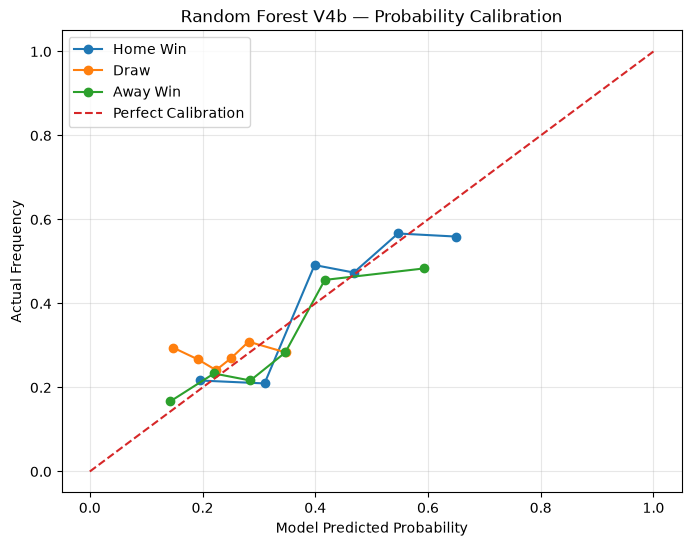

In [89]:
# When the model says something has a 60% chance of happening, does it actually happen roughly 60% of the time?
# Looking to see if our model is good, overconfident, or underconfident

from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

class_names = {
    0: "Home Win",
    1: "Draw",
    2: "Away Win"
}

plt.figure(figsize=(8, 6))

for class_idx, class_name in class_names.items():

    # Convert the actual result into yes/no for this class
    y_binary = (y_test_v4b.to_numpy() == class_idx).astype(int)

    prob_true, prob_pred = calibration_curve(
        y_binary,
        rf_proba_v4b[:, class_idx],
        n_bins=6,
        strategy="quantile"
    )

    plt.plot(
        prob_pred,
        prob_true,
        marker="o",
        label=class_name
    )

# Perfectly calibrated reference line
plt.plot(
    [0, 1],
    [0, 1],
    "--",
    label="Perfect Calibration"
)

plt.xlabel("Model Predicted Probability")
plt.ylabel("Actual Frequency")
plt.title("Random Forest V4b — Probability Calibration")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [90]:
# Perform a Brier scoring test to measure probability alongside log loss
from sklearn.preprocessing import label_binarize
import numpy as np

y_test_onehot_v4b = label_binarize(
    y_test_v4b,
    classes = [0, 1, 2]
)

brier_v4b = np.mean(
    np.sum(
        (rf_proba_v4b - y_test_onehot_v4b) ** 2,
        axis = 1
    )
)

print("V4b Multiclass Brier Score:", brier_v4b)

V4b Multiclass Brier Score: 0.6347309803921568


In [94]:
print(market_proba.shape)

(357, 3)


In [96]:
# Calculate Brier score for Bet365 fair probabilities.

brier_bet365 = np.mean(
    np.sum(
        (market_proba - y_test_onehot_v4b) ** 2,
        axis = 1
    )
)

print("Bet365 Multiclass Brier Score:", brier_bet365)


Bet365 Multiclass Brier Score: 0.6106010079054089


In [97]:
model_ready_df_v4b.groupby("season").size()

season
2023_24    265
2024_25    347
2025_26    357
dtype: int64

In [98]:
# Create a train/test split for calibration
# Train on 2023_24
# Calibrate using 24/25
# Test on 25/26

train_cal_df = model_ready_df_v4b[
    model_ready_df_v4b["season"] == "2023_24"
].copy()

calibration_df = model_ready_df_v4b[
    model_ready_df_v4b["season"] == "2024_25"
].copy()

final_test_df = model_ready_df_v4b[
    model_ready_df_v4b["season"] == "2025_26"
].copy()


X_train_cal = train_cal_df[engineered_features_v4b]
y_train_cal = train_cal_df["target"]

X_calibration = calibration_df[engineered_features_v4b]
y_calibration = calibration_df["target"]

X_final_test = final_test_df[engineered_features_v4b]
y_final_test = final_test_df["target"]


print("RF training:", X_train_cal.shape)
print("Calibration:", X_calibration.shape)
print("Final test:", X_final_test.shape)

RF training: (265, 51)
Calibration: (347, 51)
Final test: (357, 51)


In [100]:
# Train a new RF model only on 2023/24
# Can't be an existing model because it has already seen 2024/25 info during training

rf_cal_base = RandomForestClassifier(
    n_estimators = 500,
    random_state = 42,
    n_jobs = -1
)

rf_cal_base.fit(
    X_train_cal,
    y_train_cal
)

# Get uncalibrated probabilites on the 2024/25 calibration season
calibration_proba = rf_cal_base.predict_proba(
    X_calibration
)

print("Calibration probability shape:", calibration_proba.shape)
print("First 5 probability predictions:")
print(calibration_proba[:5])

Calibration probability shape: (347, 3)
First 5 probability predictions:
[[0.278 0.212 0.51 ]
 [0.412 0.326 0.262]
 [0.466 0.41  0.124]
 [0.342 0.412 0.246]
 [0.734 0.14  0.126]]


In [ ]:
# Perform sigmoid calibration
# Sigmoid calibration is less prone to overfitting with limited calibration data (347 matches)

from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator

In [102]:
calibrated_rf = CalibratedClassifierCV(
    FrozenEstimator(rf_cal_base),
    method = "sigmoid"
)

calibrated_rf.fit(
    X_calibration,
    y_calibration
)

print("Sigmoid calibration fitted successfully.")

Sigmoid calibration fitted successfully.


In [105]:
# Compare calibrated to uncalibrated models

# Calibrated probabilities on the untouched 2025/26 season
calibrated_proba = calibrated_rf.predict_proba(
    X_final_test
)

calibrated_logloss = log_loss(
    y_final_test,
    calibrated_proba
)

# Converting results to one-hot format for Brier scoring
y_final_onehot = label_binarize(
    y_final_test,
    classes = [0, 1, 2]
)

# Calculating multiclass Brier score
calibrated_brier = np.mean(
    np.sum(
        (calibrated_proba - y_final_onehot) **2,
        axis = 1
    )
)

print("Sigmoid Calibrated RF Log Loss:", calibrated_logloss)
print("Sigmoid Calibrated RF Brier Score:", calibrated_brier)

Sigmoid Calibrated RF Log Loss: 1.0409305594426013
Sigmoid Calibrated RF Brier Score: 0.6269225785492699


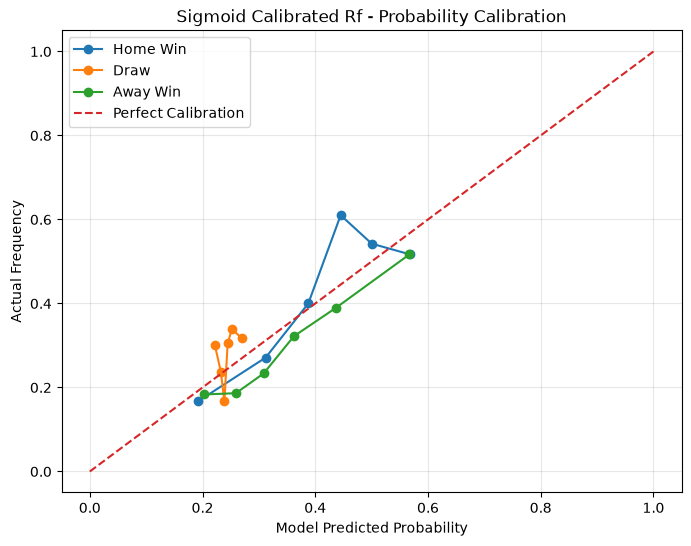

In [ ]:
# Graph the calibrated probabilities using calibration chart to see what the improved scores are telling us

from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

class_names = {
    0: "Home Win",
    1: "Draw",
    2: "Away Win"
}

plt.figure(figsize = (8, 6))

for class_idx, class_name in class_names.items():
    y_binary = (y_final_test.to_numpy() == class_idx).astype(int)

    prob_true, prob_pred = calibration_curve(
        y_binary,
        calibrated_proba[:, class_idx],
        n_bins = 6,
        strategy = "quantile"
    )

    plt.plot(
        prob_pred,
        prob_true,
        marker = "o",
        label = class_name
    )

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    label = "Perfect Calibration"
)

plt.xlabel("Model Predicted Probability")
plt.ylabel("Actual Frequency")
plt.title("Sigmoid Calibrated Rf - Probability Calibration")
plt.legend()
plt.grid(alpha = 0.3)

plt.show()

# Sigmoid calibration has compressed the probabilities towards the middle.

In [ ]:
# Try calibrating again, but with 24/25 being split chronologically

season_2324 = model_ready_df_v4b[
    model_ready_df_v4b["season"] == "2023_24"
].sort_values("date").copy()

season_2425 = model_ready_df_v4b[
    model_ready_df_v4b["season"] == "2024_25"
].sort_values("date").copy()

season_2526 = model_ready_df_v4b[
    model_ready_df_v4b["season"] == "2025_26"
].sort_values("date").copy()


split_index = int(len(season_2425) * 0.70)

season_2425_train = season_2425.iloc[:split_index].copy()
season_2425_cal = season_2425.iloc[split_index:].copy()


expanded_train_df = pd.concat(
    [season_2324, season_2425_train],
    ignore_index=True
)

expanded_calibration_df = season_2425_cal.copy()
expanded_test_df = season_2526.copy()


print("RF training matches:", len(expanded_train_df))
print("Calibration matches:", len(expanded_calibration_df))
print("Final test matches:", len(expanded_test_df))

print("\nLatest RF training date:")
print(expanded_train_df["date"].max())

print("\nEarliest calibration date:")
print(expanded_calibration_df["date"].min())

# Increased RF training from 265 matches to 507 matches

RF training matches: 507
Calibration matches: 105
Final test matches: 357

Latest RF training date:
2025-03-08 15:00:00+00:00

Earliest calibration date:
2025-03-08 17:30:00+00:00


In [108]:
# Train the expanded RF

X_expanded_train = expanded_train_df[engineered_features_v4b]
y_expanded_train = expanded_train_df["target"]

X_expanded_cal = expanded_calibration_df[engineered_features_v4b]
y_expanded_cal = expanded_calibration_df["target"]

X_expanded_test = expanded_test_df[engineered_features_v4b]
y_expanded_test = expanded_test_df["target"]


rf_expanded = RandomForestClassifier(
    n_estimators=500,
    random_state=42,
    n_jobs=-1
)

rf_expanded.fit(
    X_expanded_train,
    y_expanded_train
)

print("Expanded RF trained successfully.")
print("Training shape:", X_expanded_train.shape)
print("Calibration shape:", X_expanded_cal.shape)
print("Test shape:", X_expanded_test.shape)

Expanded RF trained successfully.
Training shape: (507, 51)
Calibration shape: (105, 51)
Test shape: (357, 51)


In [110]:
# Calibrate the 507-match RF using only the later 105 matches

calibrated_rf_expanded = CalibratedClassifierCV(
    FrozenEstimator(rf_expanded),
    method = "sigmoid"
)

calibrated_rf_expanded.fit(
    X_expanded_cal,
    y_expanded_cal
)

print("Expanded sigmoid calibration fitted successfully.")

Expanded sigmoid calibration fitted successfully.


In [111]:
# Evaluate on the 357 matches from 2025/26

expanded_calibrated_proba = calibrated_rf_expanded.predict_proba(
    X_expanded_test
)

# Log loss
expanded_calibrated_logloss = log_loss(
    y_expanded_test,
    expanded_calibrated_proba
)

# One-hot actual outcomes
y_expanded_test_onehot = label_binarize(
    y_expanded_test,
    classes=[0, 1, 2]
)

# Multiclass Brier score
expanded_calibrated_brier = np.mean(
    np.sum(
        (expanded_calibrated_proba - y_expanded_test_onehot) ** 2,
        axis=1
    )
)

print("Expanded Calibrated RF Log Loss:", expanded_calibrated_logloss)
print("Expanded Calibrated RF Brier Score:", expanded_calibrated_brier)

Expanded Calibrated RF Log Loss: 1.0418526841291187
Expanded Calibrated RF Brier Score: 0.625717372964798


In [112]:
# Compare the uncalibrated 507 match RF against its calibrated version
# Important because right now we're comparing the expanded calibrated model to the original 612 match V4b
# Isolate what sigmoid calibration did to the same 507 match model

expanded_uncalibrated_proba = rf_expanded.predict_proba(
    X_expanded_test
)

expanded_uncalibrated_logloss = log_loss(
    y_expanded_test,
    expanded_uncalibrated_proba
)

expanded_uncalibrated_brier = np.mean(
    np.sum(
        (expanded_uncalibrated_proba - y_expanded_test_onehot) ** 2,
        axis=1
    )
)

print("Uncalibrated Expanded RF Log Loss:", expanded_uncalibrated_logloss)
print("Uncalibrated Expanded RF Brier Score:", expanded_uncalibrated_brier)

print("\nAfter Sigmoid Calibration:")
print("Log Loss:", expanded_calibrated_logloss)
print("Brier Score:", expanded_calibrated_brier)

Uncalibrated Expanded RF Log Loss: 1.0525702712032545
Uncalibrated Expanded RF Brier Score: 0.6323111484593837

After Sigmoid Calibration:
Log Loss: 1.0418526841291187
Brier Score: 0.625717372964798


# PERFORM CHRONOLOGICAL BACKTEST
Past Matches Only
     |
Train Model
     |
Calibrate probabilities using recent historical matches
     |
Predict the next group of matches
     |
Those matches become history
     |
Retrain
     |
Predict again
     |
Repeat through 2025/26

In [113]:
# Inspect 2025/26 matchdays

backtest_2526 = model_ready_df_v4b[
    model_ready_df_v4b["season"] == "2025_26"
].copy()

backtest_2526 = backtest_2526.sort_values(
    ["matchday", "date"]
)

matchday_counts = (
    backtest_2526
    .groupby("matchday")
    .size()
)

print("2025/26 usable matches:", len(backtest_2526))
print("Number of matchdays:", backtest_2526["matchday"].nunique())

print("\nMatches per matchday:")
print(matchday_counts)

2025/26 usable matches: 357
Number of matchdays: 38

Matches per matchday:
matchday
1      7
2      8
3      7
4      7
5      8
6      8
7      8
8      8
9      8
10     8
11    10
12    10
13    10
14    10
15    10
16    10
17    10
18    10
19    10
20    10
21    10
22    10
23    10
24    10
25    10
26    10
27    10
28    10
29    10
30    10
31    10
32    10
33    10
34    10
35    10
36    10
37    10
38    10
dtype: int64


In [ ]:
# Set up historical starting pool
# We want backtest to begin 2025/26 by knowing only what would have been known before that season

historical_pool = model_ready_df_v4b[
    model_ready_df_v4b["season"].isin(["2023_24", "2024_25"])
].copy()

historical_pool = historical_pool.sort_values("date")

print("Starting historical matches:", len(historical_pool))
print("First historical match:", historical_pool["date"].min())
print("Last historical match:", historical_pool["date"].max())

print("\n2025/26 backtest matches:", len(backtest_2526))
print("First backtest match:", backtest_2526["date"].min())

# At matchday 1, model can use 2023/24 + 2024/25
# After matchday 1, those results become available
# Matchday 2 can use 2023/24 + 2024/25 + 2025/26 matchday
# Then matchday 3 gets MW1-2 and so on
# Prevents futre info from leaking backward

Starting historical matches: 612
First historical match: 2023-11-04 12:30:00+00:00
Last historical match: 2025-05-25 15:00:00+00:00

2025/26 backtest matches: 357
First backtest match: 2025-08-15 19:00:00+00:00


In [115]:
# Build walk-forward loop
backtest_results = []

training_pool = historical_pool.copy()

for matchday in sorted(backtest_2526["matchday"].unique()):

    # Matches we are predicting this week
    matchday_df = backtest_2526[
        backtest_2526["matchday"] == matchday
    ].copy()

    # Training data = everything available BEFORE this matchday
    X_train_bt = training_pool[engineered_features_v4b]
    y_train_bt = training_pool["target"]

    # Train a fresh RF
    rf_bt = RandomForestClassifier(
        n_estimators=500,
        random_state=42,
        n_jobs=-1
    )

    rf_bt.fit(
        X_train_bt,
        y_train_bt
    )

    # Predict this matchday
    X_matchday = matchday_df[engineered_features_v4b]

    matchday_proba = rf_bt.predict_proba(
        X_matchday
    )

    # Store each prediction
    for i, (_, match) in enumerate(matchday_df.iterrows()):

        backtest_results.append({
            "match_id": match["match_id"],
            "date": match["date"],
            "matchday": matchday,
            "home_team": match["home_team"],
            "away_team": match["away_team"],
            "actual_result": match["target"],

            "home_prob": matchday_proba[i, 0],
            "draw_prob": matchday_proba[i, 1],
            "away_prob": matchday_proba[i, 2],

            "training_matches": len(training_pool)
        })

    # ONLY AFTER predictions are made,
    # add this matchday to the historical training pool
    training_pool = pd.concat(
        [training_pool, matchday_df],
        ignore_index=True
    )


backtest_results_df = pd.DataFrame(
    backtest_results
)

print("Backtest predictions:", len(backtest_results_df))

print(
    backtest_results_df[
        [
            "matchday",
            "home_team",
            "away_team",
            "home_prob",
            "draw_prob",
            "away_prob",
            "training_matches"
        ]
    ].head(15)
)

Backtest predictions: 357
    matchday               home_team               away_team  home_prob  \
0          1               Liverpool             Bournemouth      0.476   
1          1             Aston Villa        Newcastle United      0.272   
2          1  Brighton & Hove Albion                  Fulham      0.462   
3          1           Wolverhampton         Manchester City      0.216   
4          1                 Chelsea          Crystal Palace      0.364   
5          1       Nottingham Forest               Brentford      0.400   
6          1       Manchester United                 Arsenal      0.386   
7          2         West Ham United                 Chelsea      0.248   
8          2         Manchester City       Tottenham Hotspur      0.734   
9          2               Brentford             Aston Villa      0.592   
10         2             Bournemouth           Wolverhampton      0.476   
11         2          Crystal Palace       Nottingham Forest      0.420   

In [116]:
# Score the backtest
# Calculate accuracy, log loss, and Brier score across 357 predictions
# Asking what if my system actually existed during thr 2025/26 season and retrained after each completed matchday, how would it perform?

# Actual results
y_backtest = backtest_results_df["actual_result"].astype(int)

# Predicted probabilities
backtest_proba = backtest_results_df[
    [
        "home_prob",
        "draw_prob",
        "away_prob"
    ]
].values

# Predicted class = highest probability
backtest_pred = np.argmax(
    backtest_proba,
    axis=1
)

# Accuracy
backtest_accuracy = accuracy_score(
    y_backtest,
    backtest_pred
)

# Log loss
backtest_logloss = log_loss(
    y_backtest,
    backtest_proba,
    labels=[0, 1, 2]
)

# One-hot actual results
y_backtest_onehot = label_binarize(
    y_backtest,
    classes=[0, 1, 2]
)

# Multiclass Brier score
backtest_brier = np.mean(
    np.sum(
        (backtest_proba - y_backtest_onehot) ** 2,
        axis=1
    )
)

print("Walk-Forward RF Accuracy:", backtest_accuracy)
print("Walk-Forward RF Log Loss:", backtest_logloss)
print("Walk-Forward RF Brier Score:", backtest_brier)

Walk-Forward RF Accuracy: 0.47058823529411764
Walk-Forward RF Log Loss: 1.059472175397389
Walk-Forward RF Brier Score: 0.6378538263305322


In [117]:
# Walk-forward method performed worse
# Try walk-forward sigmoid calibration

calibrated_backtest_results = []

# Start with only matches known before 2025/26
training_pool_cal = historical_pool.copy()

CALIBRATION_WINDOW = 100

for matchday in sorted(backtest_2526["matchday"].unique()):

    # ---------------------------------------
    # 1. Matches we need to predict
    # ---------------------------------------
    matchday_df = backtest_2526[
        backtest_2526["matchday"] == matchday
    ].copy()

    # Keep everything chronological
    training_pool_cal = training_pool_cal.sort_values("date").reset_index(drop=True)

    # ---------------------------------------
    # 2. Split available history
    # ---------------------------------------
    rf_train_df = training_pool_cal.iloc[:-CALIBRATION_WINDOW].copy()

    calibration_window_df = training_pool_cal.iloc[-CALIBRATION_WINDOW:].copy()

    # ---------------------------------------
    # 3. Train Random Forest on older history
    # ---------------------------------------
    X_rf_train = rf_train_df[engineered_features_v4b]
    y_rf_train = rf_train_df["target"]

    rf_walk_cal = RandomForestClassifier(
        n_estimators=500,
        random_state=42,
        n_jobs=-1
    )

    rf_walk_cal.fit(
        X_rf_train,
        y_rf_train
    )

    # ---------------------------------------
    # 4. Calibrate using recent history
    # ---------------------------------------
    X_cal_window = calibration_window_df[engineered_features_v4b]
    y_cal_window = calibration_window_df["target"]

    calibrated_walk_model = CalibratedClassifierCV(
        FrozenEstimator(rf_walk_cal),
        method="sigmoid"
    )

    calibrated_walk_model.fit(
        X_cal_window,
        y_cal_window
    )

    # ---------------------------------------
    # 5. Predict current matchday
    # ---------------------------------------
    X_matchday = matchday_df[engineered_features_v4b]

    matchday_proba = calibrated_walk_model.predict_proba(
        X_matchday
    )

    # ---------------------------------------
    # 6. Store predictions
    # ---------------------------------------
    for i, (_, match) in enumerate(matchday_df.iterrows()):

        calibrated_backtest_results.append({
            "match_id": match["match_id"],
            "date": match["date"],
            "matchday": matchday,
            "home_team": match["home_team"],
            "away_team": match["away_team"],
            "actual_result": match["target"],

            "home_prob": matchday_proba[i, 0],
            "draw_prob": matchday_proba[i, 1],
            "away_prob": matchday_proba[i, 2],

            "rf_training_matches": len(rf_train_df),
            "calibration_matches": len(calibration_window_df)
        })

    # ---------------------------------------
    # 7. NOW the matchday becomes history
    # ---------------------------------------
    training_pool_cal = pd.concat(
        [training_pool_cal, matchday_df],
        ignore_index=True
    )


calibrated_backtest_df = pd.DataFrame(
    calibrated_backtest_results
)

print("Calibrated backtest predictions:", len(calibrated_backtest_df))

print(
    calibrated_backtest_df[
        [
            "matchday",
            "home_team",
            "away_team",
            "rf_training_matches",
            "calibration_matches"
        ]
    ].head(15)
)

Calibrated backtest predictions: 357
    matchday               home_team               away_team  \
0          1               Liverpool             Bournemouth   
1          1             Aston Villa        Newcastle United   
2          1  Brighton & Hove Albion                  Fulham   
3          1           Wolverhampton         Manchester City   
4          1                 Chelsea          Crystal Palace   
5          1       Nottingham Forest               Brentford   
6          1       Manchester United                 Arsenal   
7          2         West Ham United                 Chelsea   
8          2         Manchester City       Tottenham Hotspur   
9          2               Brentford             Aston Villa   
10         2             Bournemouth           Wolverhampton   
11         2          Crystal Palace       Nottingham Forest   
12         2                 Everton  Brighton & Hove Albion   
13         2                  Fulham       Manchester United   
14 

In [118]:
# Score the calibrated walk-forward model

# Actual results
y_cal_backtest = calibrated_backtest_df[
    "actual_result"
].astype(int)

# Calibrated probabilities
cal_backtest_proba = calibrated_backtest_df[
    [
        "home_prob",
        "draw_prob",
        "away_prob"
    ]
].values

# Highest probability = predicted result
cal_backtest_pred = np.argmax(
    cal_backtest_proba,
    axis=1
)

# Accuracy
cal_backtest_accuracy = accuracy_score(
    y_cal_backtest,
    cal_backtest_pred
)

# Log loss
cal_backtest_logloss = log_loss(
    y_cal_backtest,
    cal_backtest_proba,
    labels=[0, 1, 2]
)

# Actual results to one-hot
y_cal_backtest_onehot = label_binarize(
    y_cal_backtest,
    classes=[0, 1, 2]
)

# Multiclass Brier
cal_backtest_brier = np.mean(
    np.sum(
        (cal_backtest_proba - y_cal_backtest_onehot) ** 2,
        axis=1
    )
)

print("Calibrated Walk-Forward Accuracy:", cal_backtest_accuracy)
print("Calibrated Walk-Forward Log Loss:", cal_backtest_logloss)
print("Calibrated Walk-Forward Brier Score:", cal_backtest_brier)

Calibrated Walk-Forward Accuracy: 0.47058823529411764
Calibrated Walk-Forward Log Loss: 1.0660626312102388
Calibrated Walk-Forward Brier Score: 0.6408604291453176


# MODEL VS MARKET ANALYSIS

In [119]:
market_columns = test_df[
    [
        "match_id",
        "market_home_prob",
        "market_draw_prob",
        "market_away_prob"
    ]
].copy()

walk_forward_market_df = backtest_results_df.merge(
    market_columns,
    on="match_id",
    how="left"
)

print("Matches:", len(walk_forward_market_df))

print("\nMissing Bet365 probabilities:")
print(
    walk_forward_market_df[
        [
            "market_home_prob",
            "market_draw_prob",
            "market_away_prob"
        ]
    ].isna().sum()
)

Matches: 357

Missing Bet365 probabilities:
market_home_prob    0
market_draw_prob    0
market_away_prob    0
dtype: int64


In [120]:
# We have a clean 357 match model vs market dataset
# Score Bet365 on the same walk-forward matches.

market_backtest_proba = walk_forward_market_df[
    [
        "market_home_prob",
        "market_draw_prob",
        "market_away_prob"
    ]
].values

y_market_backtest = walk_forward_market_df[
    "actual_result"
].astype(int)

# Bet365 predicted outcome
market_backtest_pred = np.argmax(
    market_backtest_proba,
    axis=1
)

# Accuracy
market_backtest_accuracy = accuracy_score(
    y_market_backtest,
    market_backtest_pred
)

# Log loss
market_backtest_logloss = log_loss(
    y_market_backtest,
    market_backtest_proba,
    labels=[0, 1, 2]
)

# One-hot actual outcomes
y_market_onehot = label_binarize(
    y_market_backtest,
    classes=[0, 1, 2]
)

# Brier score
market_backtest_brier = np.mean(
    np.sum(
        (market_backtest_proba - y_market_onehot) ** 2,
        axis=1
    )
)

print("Bet365 Accuracy:", market_backtest_accuracy)
print("Bet365 Log Loss:", market_backtest_logloss)
print("Bet365 Brier Score:", market_backtest_brier)

Bet365 Accuracy: 0.49019607843137253
Bet365 Log Loss: 1.0161028468294055
Bet365 Brier Score: 0.610601007905409


In [121]:
# Calculate model vs market edge
# Use the uncalibrated walk-forward RF since it beat the rolling calibrated version

walk_forward_market_df["home_edge"] = (
    walk_forward_market_df["home_prob"]
    - walk_forward_market_df["market_home_prob"]
)

walk_forward_market_df["draw_edge"] = (
    walk_forward_market_df["draw_prob"]
    - walk_forward_market_df["market_draw_prob"]
)

walk_forward_market_df["away_edge"] = (
    walk_forward_market_df["away_prob"]
    - walk_forward_market_df["market_away_prob"]
)

walk_forward_market_df[
    [
        "home_team",
        "away_team",
        "home_prob",
        "market_home_prob",
        "home_edge",
        "draw_prob",
        "market_draw_prob",
        "draw_edge",
        "away_prob",
        "market_away_prob",
        "away_edge"
    ]
].head(10)

,home_team,away_team,home_prob,market_home_prob,home_edge,draw_prob,market_draw_prob,draw_edge,away_prob,market_away_prob,away_edge
0,Liverpool,Bournemouth,0.476,0.736196,-0.260196,0.288,0.158282,0.129718,0.236,0.105521,0.130479
1,Aston Villa,Newcastle United,0.272,0.402938,-0.130938,0.274,0.270544,0.003456,0.454,0.326518,0.127482
2,Brighton & Hove Albion,Fulham,0.462,0.509554,-0.047554,0.236,0.254777,-0.018777,0.302,0.235669,0.066331
3,Wolverhampton,Manchester City,0.216,0.152136,0.063864,0.312,0.226393,0.085607,0.472,0.621471,-0.149471
4,Chelsea,Crystal Palace,0.364,0.512500,-0.148500,0.324,0.256250,0.067750,0.312,0.231250,0.080750
5,Nottingham Forest,Brentford,0.400,0.501193,-0.101193,0.276,0.272076,0.003924,0.324,0.226730,0.097270
6,Manchester United,Arsenal,0.386,0.253989,0.132011,0.240,0.253989,-0.013989,0.374,0.492021,-0.118021
7,West Ham United,Chelsea,0.248,0.199519,0.048481,0.296,0.243003,0.052997,0.456,0.557478,-0.101478
8,Manchester City,Tottenham Hotspur,0.734,0.604885,0.129115,0.164,0.216529,-0.052529,0.102,0.178585,-0.076585
9,Brentford,Aston Villa,0.592,0.294488,0.297512,0.138,0.277165,-0.139165,0.270,0.428346,-0.158346


In [122]:
edge_rows = []

for _, match in walk_forward_market_df.iterrows():

    actual_result = int(match["actual_result"])

    outcomes = [
        (
            0,
            "Home",
            match["home_prob"],
            match["market_home_prob"],
            match["home_edge"]
        ),
        (
            1,
            "Draw",
            match["draw_prob"],
            match["market_draw_prob"],
            match["draw_edge"]
        ),
        (
            2,
            "Away",
            match["away_prob"],
            match["market_away_prob"],
            match["away_edge"]
        )
    ]

    for outcome_code, outcome_name, model_prob, market_prob, edge in outcomes:

        edge_rows.append({
            "match_id": match["match_id"],
            "matchday": match["matchday"],
            "home_team": match["home_team"],
            "away_team": match["away_team"],
            "outcome": outcome_name,

            "model_prob": model_prob,
            "market_prob": market_prob,
            "edge": edge,

            # 1 if this outcome actually happened, otherwise 0
            "won": int(actual_result == outcome_code)
        })


edge_df = pd.DataFrame(edge_rows)

print("Total edge observations:", len(edge_df))

print(
    edge_df[
        [
            "home_team",
            "away_team",
            "outcome",
            "model_prob",
            "market_prob",
            "edge",
            "won"
        ]
    ].head(12)
)

Total edge observations: 1071
                 home_team         away_team outcome  model_prob  market_prob  \
0                Liverpool       Bournemouth    Home       0.476     0.736196   
1                Liverpool       Bournemouth    Draw       0.288     0.158282   
2                Liverpool       Bournemouth    Away       0.236     0.105521   
3              Aston Villa  Newcastle United    Home       0.272     0.402938   
4              Aston Villa  Newcastle United    Draw       0.274     0.270544   
5              Aston Villa  Newcastle United    Away       0.454     0.326518   
6   Brighton & Hove Albion            Fulham    Home       0.462     0.509554   
7   Brighton & Hove Albion            Fulham    Draw       0.236     0.254777   
8   Brighton & Hove Albion            Fulham    Away       0.302     0.235669   
9            Wolverhampton   Manchester City    Home       0.216     0.152136   
10           Wolverhampton   Manchester City    Draw       0.312     0.226393  

In [123]:
edge_df["edge_bin"] = pd.cut(
    edge_df["edge"],
    bins=[
        -float("inf"),
        -0.10,
        -0.05,
        0.00,
        0.05,
        0.10,
        0.15,
        float("inf")
    ],
    labels=[
        "< -10%",
        "-10% to -5%",
        "-5% to 0%",
        "0% to 5%",
        "5% to 10%",
        "10% to 15%",
        "15%+"
    ]
)

edge_summary = (
    edge_df
    .groupby("edge_bin", observed=False)
    .agg(
        observations=("won", "size"),
        actual_win_rate=("won", "mean"),
        avg_model_prob=("model_prob", "mean"),
        avg_market_prob=("market_prob", "mean"),
        avg_edge=("edge", "mean")
    )
    .reset_index()
)

edge_summary["actual_minus_market"] = (
    edge_summary["actual_win_rate"]
    - edge_summary["avg_market_prob"]
)

edge_summary["actual_minus_model"] = (
    edge_summary["actual_win_rate"]
    - edge_summary["avg_model_prob"]
)

edge_summary

,edge_bin,observations,actual_win_rate,avg_model_prob,avg_market_prob,avg_edge,actual_minus_market,actual_minus_model
0,< -10%,155,0.490323,0.333535,0.485707,-0.152171,0.004616,0.156787
1,-10% to -5%,166,0.361446,0.284855,0.358154,-0.073299,0.003291,0.076590
2,-5% to 0%,215,0.283721,0.287126,0.312055,-0.024929,-0.028334,-0.003405
3,0% to 5%,209,0.315789,0.303837,0.280413,0.023424,0.035377,0.011952
4,5% to 10%,169,0.307692,0.358994,0.285438,0.073556,0.022254,-0.051302
5,10% to 15%,90,0.244444,0.416800,0.295551,0.121249,-0.051106,-0.172356
6,15%+,67,0.298507,0.516418,0.324256,0.192162,-0.025749,-0.217910


In [124]:
edge_by_outcome = (
    edge_df
    .groupby(
        ["outcome", "edge_bin"],
        observed=False
    )
    .agg(
        observations=("won", "size"),
        actual_win_rate=("won", "mean"),
        avg_model_prob=("model_prob", "mean"),
        avg_market_prob=("market_prob", "mean"),
        avg_edge=("edge", "mean")
    )
    .reset_index()
)

edge_by_outcome["actual_minus_market"] = (
    edge_by_outcome["actual_win_rate"]
    - edge_by_outcome["avg_market_prob"]
)

edge_by_outcome["actual_minus_model"] = (
    edge_by_outcome["actual_win_rate"]
    - edge_by_outcome["avg_model_prob"]
)

edge_by_outcome

,outcome,edge_bin,observations,actual_win_rate,avg_model_prob,avg_market_prob,avg_edge,actual_minus_market,actual_minus_model
0,Away,< -10%,66,0.469697,0.322879,0.476225,-0.153347,-0.006528,0.146818
1,Away,-10% to -5%,42,0.309524,0.276333,0.353866,-0.077533,-0.044342,0.033190
2,Away,-5% to 0%,57,0.298246,0.263789,0.287957,-0.024167,0.010289,0.034456
3,Away,0% to 5%,71,0.211268,0.275493,0.251750,0.023743,-0.040482,-0.064225
4,Away,5% to 10%,61,0.229508,0.330721,0.256175,0.074546,-0.026667,-0.101213
5,Away,10% to 15%,34,0.264706,0.420588,0.296714,0.123875,-0.032008,-0.155882
6,Away,15%+,26,0.384615,0.533308,0.328333,0.204975,0.056283,-0.148692
7,Draw,< -10%,23,0.260870,0.134783,0.267181,-0.132399,-0.006312,0.126087
8,Draw,-10% to -5%,72,0.291667,0.196083,0.267523,-0.071439,0.024144,0.095583
9,Draw,-5% to 0%,90,0.222222,0.225356,0.251276,-0.025921,-0.029054,-0.003133


In [125]:
positive_edge_summary = edge_by_outcome[
    edge_by_outcome["edge_bin"].isin([
        "0% to 5%",
        "5% to 10%",
        "10% to 15%",
        "15%+"
    ])
][
    [
        "outcome",
        "edge_bin",
        "observations",
        "avg_market_prob",
        "avg_model_prob",
        "actual_win_rate",
        "actual_minus_market"
    ]
].copy()

print(
    positive_edge_summary.to_string(index=False)
)

outcome   edge_bin  observations  avg_market_prob  avg_model_prob  actual_win_rate  actual_minus_market
   Away   0% to 5%            71         0.251750        0.275493         0.211268            -0.040482
   Away  5% to 10%            61         0.256175        0.330721         0.229508            -0.026667
   Away 10% to 15%            34         0.296714        0.420588         0.264706            -0.032008
   Away       15%+            26         0.328333        0.533308         0.384615             0.056283
   Draw   0% to 5%            86         0.239726        0.262256         0.337209             0.097484
   Draw  5% to 10%            53         0.227717        0.299623         0.358491             0.130774
   Draw 10% to 15%            22         0.209780        0.330636         0.136364            -0.073416
   Draw       15%+            11         0.208920        0.381091         0.090909            -0.118011
   Home   0% to 5%            52         0.386840        0.41130

# MODEL TRAINING WITH UPDATED MATCH DATASET

In [126]:
# Load the feature-engineered dataset

import pandas as pd
import numpy as np
from pathlib import Path

PROCESSED_DIR = Path("../data/processed")

model_df = pd.read_csv(
    PROCESSED_DIR / "pl_match_features.csv"
)

model_df["date_home"] = pd.to_datetime(
    model_df["date_home"],
    utc=True
)

print("Shape:", model_df.shape)
print()
print(model_df[[
    "date_home",
    "season_home",
    "team_home",
    "team_away",
    "target"
]].head())

Shape: (2280, 140)

                  date_home season_home team_home         team_away target
0 2020-09-19 19:00:00+00:00     2020_21   Arsenal   West Ham United      H
1 2020-10-04 13:00:00+00:00     2020_21   Arsenal  Sheffield United      H
2 2020-10-25 19:15:00+00:00     2020_21   Arsenal    Leicester City      A
3 2020-11-08 19:15:00+00:00     2020_21   Arsenal       Aston Villa      A
4 2020-11-29 19:15:00+00:00     2020_21   Arsenal     Wolverhampton      A


In [127]:
# Recreate the 31 baseline features

baseline_features = [
    "points_last5_all_home",
    "goal_difference_last5_all_home",
    "win_rate_last5_all_home",
    "shots_on_target_difference_last5_all_home",

    "points_last5_all_away",
    "goal_difference_last5_all_away",
    "win_rate_last5_all_away",
    "shots_on_target_difference_last5_all_away",

    "points_last5_pl_home",
    "goal_difference_last5_pl_home",
    "win_rate_last5_pl_home",
    "shots_on_target_difference_last5_pl_home",
    "points_last10_pl_home",
    "goal_difference_last10_pl_home",
    "win_rate_last10_pl_home",

    "points_last5_pl_away",
    "goal_difference_last5_pl_away",
    "win_rate_last5_pl_away",
    "shots_on_target_difference_last5_pl_away",
    "points_last10_pl_away",
    "goal_difference_last10_pl_away",
    "win_rate_last10_pl_away",

    "days_rest_home",
    "days_rest_away",
    "matches_last_7_days_home",
    "matches_last_7_days_away",
    "matches_last_14_days_home",
    "matches_last_14_days_away",

    "team_elo_home",
    "team_elo_away",
    "team_elo_difference_home"
]

print("Baseline features:", len(baseline_features))

missing_columns = [
    col for col in baseline_features
    if col not in model_df.columns
]

print("Missing columns:", missing_columns)

Baseline features: 31
Missing columns: []


In [128]:
# Start with training from 2020/21 all the wat to 2024/25
# Test on 2025/26

train_df = model_df[
    model_df["season_home"].isin([
        "2020_21",
        "2021_22",
        "2022_23",
        "2023_24",
        "2024_25"
    ])
].copy()

test_df = model_df[
    model_df["season_home"] == "2025_26"
].copy()

print("Training matches:", len(train_df))
print("Test matches:", len(test_df))

print()
print("Training seasons:")
print(train_df["season_home"].value_counts().sort_index())

print()
print("Test seasons:")
print(test_df["season_home"].value_counts().sort_index())

Training matches: 1900
Test matches: 380

Training seasons:
season_home
2020_21    380
2021_22    380
2022_23    380
2023_24    380
2024_25    380
Name: count, dtype: int64

Test seasons:
season_home
2025_26    380
Name: count, dtype: int64


In [129]:
# Separate the features (X) from the result (y)

X_train = train_df[baseline_features]
y_train = train_df["target"]

X_test = test_df[baseline_features]
y_test = test_df["target"]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print()
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print()
print("Training target distribution:")
print(y_train.value_counts())

X_train shape: (1900, 31)
y_train shape: (1900,)

X_test shape: (380, 31)
y_test shape: (380,)

Training target distribution:
target
H    821
A    646
D    433
Name: count, dtype: int64


In [130]:
# Build the first baseline model: Multinomial Log Reg
# Model looks at missing values, does scaling, and outputs its prediction model


from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    (
        "imputer",
        # Learns its median values from X_train only
        # Doesn't look at 2025/26 to decide how to fill anything
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        LogisticRegression(
            max_iter=2000
        )
    )
])

logistic_model.fit(
    X_train,
    y_train
)

print("Logistic regression trained successfully.")

Logistic regression trained successfully.


In [131]:
# Evaluate on completely unseen 2025/26 season

from sklearn.metrics import accuracy_score, log_loss

y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)

accuracy = accuracy_score(
    y_test,
    y_pred
)

logloss = log_loss(
    y_test,
    y_prob,
    labels = logistic_model.classes_
)

print("Classes:", logistic_model.classes_)
print()
print(f"Accuracy: {accuracy:.4f}")
print(f"Log Loss: {logloss:.4f}")

Classes: ['A' 'D' 'H']

Accuracy: 0.4711
Log Loss: 1.0512


In [ ]:
# Before trying Random Forest, compare this against a simple baseline:
# Always predict using the historical H/D/A frequencies from the training set

train_probabilities = (
    y_train.value_counts(normalize = True)
    .reindex(logistic_model.classes_)
    .values
)

baseline_probabilites = np.tile(
    train_probabilities,
    (len(y_test), 1)
)

baseline_logloss = log_loss(
    y_test,
    baseline_probabilites,
    labels = logistic_model.classes_
)

baseline_prediction = y_train.value_counts().idxmax()

baseline_accuracy = (
    y_test == baseline_prediction
).mean()

print("Historical probabilities:")
for label, probability in zip(
    logistic_model.classes_,
    train_probabilities
):
    print(f"{label}: {probability:.4f}")

print()
print(f"Baseline Accuracy: {baseline_accuracy:.4f}")
print(f"Baseline Log Loss: {baseline_logloss:.4f}")

print()
print(f"Logistic Accuracy: {accuracy:.4f}")
print(f"Logistic Log Loss: {logloss:.4f}")

# This means the chosen features are adding predictive information.

Historical probabilities:
A: 0.3400
D: 0.2279
H: 0.4321

Baseline Accuracy: 0.4263
Baseline Log Loss: 1.0861

Logistic Accuracy: 0.4711
Logistic Log Loss: 1.0512


In [133]:
# Test a model that can capture more complicated relationships between features
# Random Forest model

from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy = "median")
    ),
    (
        "model",
        RandomForestClassifier(
            n_estimators = 500,
            max_depth = 8,
            min_samples_leaf = 5,
            random_state = 42,
            n_jobs = -1
        )
    )
])

random_forest_model.fit(
    X_train,
    y_train
)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [134]:
# Evaluate the Random Forest on same 380 unseen 2025/26 matches

rf_pred = random_forest_model.predict(X_test)
rf_prob = random_forest_model.predict_proba(X_test)

rf_accuracy = accuracy_score(
    y_test,
    rf_pred
)

rf_logloss = log_loss(
    y_test,
    rf_prob,
    labels = random_forest_model.classes_
)

print("Classes:", random_forest_model.classes_)

print()
print(f"Random Forest Accuracy: {rf_accuracy:.4f}")
print(f"Random Forest Log Loss: {rf_logloss:.4f}")

print()
print("Comparison:")
print(f"Historical Baseline  | Accuracy: {baseline_accuracy:.4f} | Log Loss: {baseline_logloss:.4f}")
print(f"Logistic Regression | Accuracy: {accuracy:.4f} | Log Loss: {logloss:.4f}")
print(f"Random Forest       | Accuracy: {rf_accuracy:.4f} | Log Loss: {rf_logloss:.4f}")

Classes: ['A' 'D' 'H']

Random Forest Accuracy: 0.4816
Random Forest Log Loss: 1.0433

Comparison:
Historical Baseline  | Accuracy: 0.4263 | Log Loss: 1.0861
Logistic Regression | Accuracy: 0.4711 | Log Loss: 1.0512
Random Forest       | Accuracy: 0.4816 | Log Loss: 1.0433


In [ ]:
# RF performed better than the Log Reg and Baseline models
# Check to see what the RF is actually using to make its predictions

rf_classifier = random_forest_model.named_steps["model"]

feature_importance = pd.DataFrame({
    "feature": baseline_features,
    "importance": rf_classifier.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "importance",
    ascending = False
).reset_index(drop = True)

print(
    feature_importance
    .head(15)
    .to_string(index = False)
)

# team_elo_difference_home makes sense because the relative stength of the two teams should be highly predictive

                                  feature  importance
                 team_elo_difference_home    0.126042
                            team_elo_home    0.088745
 shots_on_target_difference_last5_pl_away    0.055032
                            team_elo_away    0.052872
shots_on_target_difference_last5_all_away    0.051615
 shots_on_target_difference_last5_pl_home    0.048682
           goal_difference_last10_pl_home    0.048231
           goal_difference_last10_pl_away    0.042572
shots_on_target_difference_last5_all_home    0.040631
                    points_last10_pl_home    0.037554
                           days_rest_home    0.036075
                    points_last10_pl_away    0.033629
                           days_rest_away    0.031475
            goal_difference_last5_pl_home    0.030236
           goal_difference_last5_all_away    0.028545


In [136]:
# Check where the RF model struggles

from sklearn.metrics import confusion_matrix, classification_report

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_test,
        rf_pred,
        labels=["H", "D", "A"]
    )
)

print()
print("Classification Report:")
print(
    classification_report(
        y_test,
        rf_pred,
        labels=["H", "D", "A"],
        digits=4
    )
)

Confusion Matrix:
[[128   0  34]
 [ 67   0  37]
 [ 59   0  55]]

Classification Report:
              precision    recall  f1-score   support

           H     0.5039    0.7901    0.6154       162
           D     0.0000    0.0000    0.0000       104
           A     0.4365    0.4825    0.4583       114

    accuracy                         0.4816       380
   macro avg     0.3135    0.4242    0.3579       380
weighted avg     0.3458    0.4816    0.3998       380



c:\Users\luisg\OneDrive\Desktop\Other\Luis Haddad\premier-league-predictor\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\luisg\OneDrive\Desktop\Other\Luis Haddad\premier-league-predictor\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\luisg\OneDrive\Desktop\Other\Luis Haddad\premier-league-predictor\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted sa

In [137]:
# Check if the model is giving draws a reasonable probability or just ignoring them

rf_probability_df = pd.DataFrame(
    rf_prob,
    columns=random_forest_model.classes_
)

print("Average predicted probabilities:")
print(rf_probability_df.mean())

print()
print("Highest draw probability:")
print(rf_probability_df["D"].max())

print()
print("Draw probability percentiles:")
print(
    rf_probability_df["D"].quantile([
        0.10,
        0.25,
        0.50,
        0.75,
        0.90,
        0.95,
        0.99
    ])
)

Average predicted probabilities:
A    0.320178
D    0.221287
H    0.458535
dtype: float64

Highest draw probability:
0.3444865352811906

Draw probability percentiles:
0.10    0.174600
0.25    0.196232
0.50    0.219611
0.75    0.246768
0.90    0.266792
0.95    0.280847
0.99    0.323861
Name: D, dtype: float64


In [138]:
# Check draw calibration, see whether a predicted 28% draw actually occurs around 28% of the time
# Group matches based on the model's predicted draw probability and see how often they actually ended in draws

draw_check = pd.DataFrame({
    "draw_probability": rf_probability_df["D"],
    "actual_draw": (y_test.reset_index(drop=True) == "D").astype(int)
})

draw_check["probability_group"] = pd.qcut(
    draw_check["draw_probability"],
    q=5,
    duplicates="drop"
)

draw_calibration = (
    draw_check
    .groupby(
        "probability_group",
        observed=True
    )
    .agg(
        matches=("actual_draw", "size"),
        avg_predicted_draw_probability=("draw_probability", "mean"),
        actual_draw_rate=("actual_draw", "mean")
    )
)

print(draw_calibration)


                   matches  avg_predicted_draw_probability  actual_draw_rate
probability_group                                                           
(0.123, 0.191]          76                        0.169886          0.263158
(0.191, 0.212]          76                        0.201053          0.223684
(0.212, 0.228]          76                        0.219566          0.289474
(0.228, 0.252]          76                        0.240889          0.315789
(0.252, 0.344]          76                        0.275041          0.276316


In [139]:
# Don't calibrate or tune yet, testing has only been on one season
# We don' want to accidentally fix the model specfically for the 2025/26 season and overfit the test set

# Calculate Brier score, gives another probability-quality metric

from sklearn.metrics import brier_score_loss

brier_scores = {}

for outcome in ["H", "D", "A"]:
    class_index = list(
        random_forest_model.classes_
    ).index(outcome)

    actual = (
        y_test == outcome
    ).astype(int)

    predicted = rf_prob[:, class_index]

    brier_scores[outcome] = brier_score_loss(
        actual,
        predicted
    )

multiclass_brier = sum(
    brier_scores.values()
)

print("Brier Score by outcome:")

for outcome, score in brier_scores.items():
    print(f"{outcome}: {score:.4f}")

print()
print(
    f"Multiclass Brier Score: "
    f"{multiclass_brier:.4f}"
)

Brier Score by outcome:
H: 0.2290
D: 0.2015
A: 0.1979

Multiclass Brier Score: 0.6285


In [140]:
# Before improving the RF model, finish the comparsion between Log Reg and RF

logistic_brier_scores = {}

for outcome in ["H", "D", "A"]:
    class_index = list(
        logistic_model.classes_
    ).index(outcome)

    actual = (
        y_test == outcome
    ).astype(int)

    predicted = y_prob[:, class_index]

    logistic_brier_scores[outcome] = brier_score_loss(
        actual,
        predicted
    )

logistic_multiclass_brier = sum(
    logistic_brier_scores.values()
)

print("Logistic Brier Score by outcome:")

for outcome, score in logistic_brier_scores.items():
    print(f"{outcome}: {score:.4f}")

print()
print(
    f"Logistic Multiclass Brier Score: "
    f"{logistic_multiclass_brier:.4f}"
)

print()
print("Current comparison:")
print(
    f"Logistic Regression | "
    f"Accuracy: {accuracy:.4f} | "
    f"Log Loss: {logloss:.4f} | "
    f"Brier: {logistic_multiclass_brier:.4f}"
)
print(
    f"Random Forest       | "
    f"Accuracy: {rf_accuracy:.4f} | "
    f"Log Loss: {rf_logloss:.4f} | "
    f"Brier: {multiclass_brier:.4f}"
)

Logistic Brier Score by outcome:
H: 0.2270
D: 0.2049
A: 0.2000

Logistic Multiclass Brier Score: 0.6319

Current comparison:
Logistic Regression | Accuracy: 0.4711 | Log Loss: 1.0512 | Brier: 0.6319
Random Forest       | Accuracy: 0.4816 | Log Loss: 1.0433 | Brier: 0.6285


In [141]:
# Make 2024/25 season a validation/model development season
# Don't tune RF model against 2025/26 repeatedly because then it slowly stops being a truly unseen test season

development_train_df = model_df[
    model_df["season_home"].isin([
        "2020_21",
        "2021_22",
        "2022_23",
        "2023_24"
    ])
].copy()

validation_df = model_df[
    model_df["season_home"] == "2024_25"
].copy()

final_test_df = model_df[
    model_df["season_home"] == "2025_26"
].copy()

print(
    "Development training matches:",
    len(development_train_df)
)

print(
    "Validation matches:",
    len(validation_df)
)

print(
    "Final test matches:",
    len(final_test_df)
)

Development training matches: 1520
Validation matches: 380
Final test matches: 380


In [ ]:
# Recreate the RF using only 2020/21 - 2023/24 for training and evaluate on 2024/25 for validation
# Basically asking, if we were sitting at the end of 2023/24, how well would this model have predicted the entire 2024/25 PL season?

X_dev_train = development_train_df[baseline_features]
y_dev_train = development_train_df["target"]

X_validation = validation_df[baseline_features]
y_validation = validation_df["target"]

rf_validation_model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "model",
        RandomForestClassifier(
            n_estimators=500,
            max_depth=8,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        )
    )
])

rf_validation_model.fit(
    X_dev_train,
    y_dev_train
)

validation_pred = rf_validation_model.predict(
    X_validation
)

validation_prob = rf_validation_model.predict_proba(
    X_validation
)

validation_accuracy = accuracy_score(
    y_validation,
    validation_pred
)

validation_logloss = log_loss(
    y_validation,
    validation_prob,
    labels=rf_validation_model.classes_
)

print(f"Validation Accuracy: {validation_accuracy:.4f}")
print(f"Validation Log Loss: {validation_logloss:.4f}")

Validation Accuracy: 0.5132
Validation Log Loss: 1.0196


In [143]:
# Test to see if all-competition data is actually helping
# If model performance gets worse, there is direct evidence that the other competitions context is helping PL predictions

pl_only_features = [
    feature
    for feature in baseline_features
    if "_all_" not in feature
]

print("Full baseline features:", len(baseline_features))
print("Without all-comp form:", len(pl_only_features))

print()
print("Removed features:")

for feature in baseline_features:
    if feature not in pl_only_features:
        print(feature)

Full baseline features: 31
Without all-comp form: 23

Removed features:
points_last5_all_home
goal_difference_last5_all_home
win_rate_last5_all_home
shots_on_target_difference_last5_all_home
points_last5_all_away
goal_difference_last5_all_away
win_rate_last5_all_away
shots_on_target_difference_last5_all_away


In [144]:
# Perform a controlled test: same RF model, same training seasons and validation season, but without the 8 all-competition form features

X_dev_train_pl_only = development_train_df[
    pl_only_features
]

X_validation_pl_only = validation_df[
    pl_only_features
]

rf_pl_only_model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "model",
        RandomForestClassifier(
            n_estimators=500,
            max_depth=8,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        )
    )
])

rf_pl_only_model.fit(
    X_dev_train_pl_only,
    y_dev_train
)

pl_only_pred = rf_pl_only_model.predict(
    X_validation_pl_only
)

pl_only_prob = rf_pl_only_model.predict_proba(
    X_validation_pl_only
)

pl_only_accuracy = accuracy_score(
    y_validation,
    pl_only_pred
)

pl_only_logloss = log_loss(
    y_validation,
    pl_only_prob,
    labels=rf_pl_only_model.classes_
)

print("2024/25 Validation Comparison:")
print()

print(
    f"Full 31 features     | "
    f"Accuracy: {validation_accuracy:.4f} | "
    f"Log Loss: {validation_logloss:.4f}"
)

print(
    f"Without all-comp     | "
    f"Accuracy: {pl_only_accuracy:.4f} | "
    f"Log Loss: {pl_only_logloss:.4f}"
)

2024/25 Validation Comparison:

Full 31 features     | Accuracy: 0.5132 | Log Loss: 1.0196
Without all-comp     | Accuracy: 0.5237 | Log Loss: 1.0180


In [145]:
# Test the value of ELO rating

no_elo_features = [
    feature
    for feature in pl_only_features
    if "elo" not in feature
]

print("Current features:", len(pl_only_features))
print("Without Elo:", len(no_elo_features))

print()
print("Removed features:")

for feature in pl_only_features:
    if feature not in no_elo_features:
        print(feature)

Current features: 23
Without Elo: 20

Removed features:
team_elo_home
team_elo_away
team_elo_difference_home


In [146]:
# Same RF settings, same training/validation seasons

X_dev_train_no_elo = development_train_df[
    no_elo_features
]

X_validation_no_elo = validation_df[
    no_elo_features
]

rf_no_elo_model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "model",
        RandomForestClassifier(
            n_estimators=500,
            max_depth=8,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        )
    )
])

rf_no_elo_model.fit(
    X_dev_train_no_elo,
    y_dev_train
)

no_elo_pred = rf_no_elo_model.predict(
    X_validation_no_elo
)

no_elo_prob = rf_no_elo_model.predict_proba(
    X_validation_no_elo
)

no_elo_accuracy = accuracy_score(
    y_validation,
    no_elo_pred
)

no_elo_logloss = log_loss(
    y_validation,
    no_elo_prob,
    labels=rf_no_elo_model.classes_
)

print("2024/25 Elo Comparison:")
print()

print(
    f"With Elo    | "
    f"Accuracy: {pl_only_accuracy:.4f} | "
    f"Log Loss: {pl_only_logloss:.4f}"
)

print(
    f"Without Elo | "
    f"Accuracy: {no_elo_accuracy:.4f} | "
    f"Log Loss: {no_elo_logloss:.4f}"
)

2024/25 Elo Comparison:

With Elo    | Accuracy: 0.5237 | Log Loss: 1.0180
Without Elo | Accuracy: 0.5263 | Log Loss: 1.0277


In [147]:
# Test the congestion/rest features

no_congestion_features = [
    feature
    for feature in pl_only_features
    if feature not in [
        "days_rest_home",
        "days_rest_away",
        "matches_last_7_days_home",
        "matches_last_7_days_away",
        "matches_last_14_days_home",
        "matches_last_14_days_away"
    ]
]

print("Current features:", len(pl_only_features))
print("Without rest/congestion:", len(no_congestion_features))

print()
print("Removed features:")

for feature in pl_only_features:
    if feature not in no_congestion_features:
        print(feature)

Current features: 23
Without rest/congestion: 17

Removed features:
days_rest_home
days_rest_away
matches_last_7_days_home
matches_last_7_days_away
matches_last_14_days_home
matches_last_14_days_away


In [148]:
# Run a controlled comparison again, same seasons, but removing congestion/rest features

X_dev_train_no_congestion = development_train_df[
    no_congestion_features
]

X_validation_no_congestion = validation_df[
    no_congestion_features
]

rf_no_congestion_model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "model",
        RandomForestClassifier(
            n_estimators=500,
            max_depth=8,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        )
    )
])

rf_no_congestion_model.fit(
    X_dev_train_no_congestion,
    y_dev_train
)

no_congestion_pred = rf_no_congestion_model.predict(
    X_validation_no_congestion
)

no_congestion_prob = rf_no_congestion_model.predict_proba(
    X_validation_no_congestion
)

no_congestion_accuracy = accuracy_score(
    y_validation,
    no_congestion_pred
)

no_congestion_logloss = log_loss(
    y_validation,
    no_congestion_prob,
    labels=rf_no_congestion_model.classes_
)

print("2024/25 Rest & Congestion Comparison:")
print()

print(
    f"With rest/congestion    | "
    f"Accuracy: {pl_only_accuracy:.4f} | "
    f"Log Loss: {pl_only_logloss:.4f}"
)

print(
    f"Without rest/congestion | "
    f"Accuracy: {no_congestion_accuracy:.4f} | "
    f"Log Loss: {no_congestion_logloss:.4f}"
)

2024/25 Rest & Congestion Comparison:

With rest/congestion    | Accuracy: 0.5237 | Log Loss: 1.0180
Without rest/congestion | Accuracy: 0.5211 | Log Loss: 1.0267


In [149]:
# Test redundancy in the ELO features
# Keeping only ELO difference

elo_difference_only_features = [
    feature
    for feature in pl_only_features
    if feature not in [
        "team_elo_home",
        "team_elo_away"
    ]
]

print("Current features:", len(pl_only_features))
print("Elo difference only:", len(elo_difference_only_features))

print()
print("Removed features:")

for feature in pl_only_features:
    if feature not in elo_difference_only_features:
        print(feature)

Current features: 23
Elo difference only: 21

Removed features:
team_elo_home
team_elo_away


In [150]:
# Test using same settings, just removing absolute home and away elo ratings

X_dev_train_elo_diff = development_train_df[
    elo_difference_only_features
]

X_validation_elo_diff = validation_df[
    elo_difference_only_features
]

rf_elo_diff_model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "model",
        RandomForestClassifier(
            n_estimators=500,
            max_depth=8,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        )
    )
])

rf_elo_diff_model.fit(
    X_dev_train_elo_diff,
    y_dev_train
)

elo_diff_pred = rf_elo_diff_model.predict(
    X_validation_elo_diff
)

elo_diff_prob = rf_elo_diff_model.predict_proba(
    X_validation_elo_diff
)

elo_diff_accuracy = accuracy_score(
    y_validation,
    elo_diff_pred
)

elo_diff_logloss = log_loss(
    y_validation,
    elo_diff_prob,
    labels=rf_elo_diff_model.classes_
)

print("2024/25 Elo Feature Comparison:")
print()

print(
    f"All 3 Elo features | "
    f"Accuracy: {pl_only_accuracy:.4f} | "
    f"Log Loss: {pl_only_logloss:.4f}"
)

print(
    f"Elo difference only | "
    f"Accuracy: {elo_diff_accuracy:.4f} | "
    f"Log Loss: {elo_diff_logloss:.4f}"
)

2024/25 Elo Feature Comparison:

All 3 Elo features | Accuracy: 0.5237 | Log Loss: 1.0180
Elo difference only | Accuracy: 0.5342 | Log Loss: 1.0130


In [151]:
# Test missing-value indicators 

rf_missing_indicator_model = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=True
        )
    ),
    (
        "model",
        RandomForestClassifier(
            n_estimators=500,
            max_depth=8,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        )
    )
])

rf_missing_indicator_model.fit(
    development_train_df[elo_difference_only_features],
    y_dev_train
)

indicator_pred = rf_missing_indicator_model.predict(
    validation_df[elo_difference_only_features]
)

indicator_prob = rf_missing_indicator_model.predict_proba(
    validation_df[elo_difference_only_features]
)

indicator_accuracy = accuracy_score(
    y_validation,
    indicator_pred
)

indicator_logloss = log_loss(
    y_validation,
    indicator_prob,
    labels=rf_missing_indicator_model.classes_
)

print("2024/25 Missing Indicator Comparison:")
print()

print(
    f"Median only       | "
    f"Accuracy: {elo_diff_accuracy:.4f} | "
    f"Log Loss: {elo_diff_logloss:.4f}"
)

print(
    f"Median + indicator | "
    f"Accuracy: {indicator_accuracy:.4f} | "
    f"Log Loss: {indicator_logloss:.4f}"
)

2024/25 Missing Indicator Comparison:

Median only       | Accuracy: 0.5342 | Log Loss: 1.0130
Median + indicator | Accuracy: 0.5316 | Log Loss: 1.0089


In [152]:
model_df = model_df.sort_values(
    ["date_home", "match_id"]
).reset_index(drop=True)

walk_forward_seasons = [
    "2021_22",
    "2022_23",
    "2023_24",
    "2024_25"
]

print(
    model_df[
        ["season_home", "date_home"]
    ]
    .groupby("season_home")
    .agg(["min", "max", "count"])
)

                            date_home                                
                                  min                       max count
season_home                                                          
2020_21     2020-09-12 11:30:00+00:00 2021-05-23 15:00:00+00:00   380
2021_22     2021-08-13 19:00:00+00:00 2022-05-22 15:00:00+00:00   380
2022_23     2022-08-05 19:00:00+00:00 2023-05-28 15:30:00+00:00   380
2023_24     2023-08-11 19:00:00+00:00 2024-05-19 15:00:00+00:00   380
2024_25     2024-08-16 19:00:00+00:00 2025-05-25 15:00:00+00:00   380
2025_26     2025-08-15 19:00:00+00:00 2026-05-24 15:00:00+00:00   380


In [153]:
# Build a walk-froward evaluation
# Test the current best setup: 21 features, median imputation + missing indicatiors, same RF settings

walk_forward_results = []

for validation_season in walk_forward_seasons:

    validation_start = model_df.loc[
        model_df["season_home"] == validation_season,
        "date_home"
    ].min()

    train_df = model_df[
        model_df["date_home"] < validation_start
    ]

    val_df = model_df[
        model_df["season_home"] == validation_season
    ]

    X_train_walk = train_df[
        elo_difference_only_features
    ]

    y_train_walk = train_df["target"]

    X_val_walk = val_df[
        elo_difference_only_features
    ]

    y_val_walk = val_df["target"]

    walk_model = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=500,
                max_depth=8,
                min_samples_leaf=5,
                random_state=42,
                n_jobs=-1
            )
        )
    ])

    walk_model.fit(
        X_train_walk,
        y_train_walk
    )

    walk_pred = walk_model.predict(
        X_val_walk
    )

    walk_prob = walk_model.predict_proba(
        X_val_walk
    )

    season_accuracy = accuracy_score(
        y_val_walk,
        walk_pred
    )

    season_logloss = log_loss(
        y_val_walk,
        walk_prob,
        labels=walk_model.classes_
    )

    walk_forward_results.append({
        "season": validation_season,
        "train_matches": len(train_df),
        "validation_matches": len(val_df),
        "accuracy": season_accuracy,
        "log_loss": season_logloss
    })

walk_forward_results_df = pd.DataFrame(
    walk_forward_results
)

print(walk_forward_results_df.to_string(index=False))

 season  train_matches  validation_matches  accuracy  log_loss
2021_22            380                 380  0.500000  1.031247
2022_23            760                 380  0.523684  1.020901
2023_24           1140                 380  0.584211  0.951900
2024_25           1520                 380  0.531579  1.009672


In [154]:
# Walk-forward the original model

baseline_walk_results = []

for validation_season in walk_forward_seasons:

    validation_start = model_df.loc[
        model_df["season_home"] == validation_season,
        "date_home"
    ].min()

    train_df = model_df[
        model_df["date_home"] < validation_start
    ]

    val_df = model_df[
        model_df["season_home"] == validation_season
    ]

    X_train_walk = train_df[
        baseline_features
    ]

    y_train_walk = train_df["target"]

    X_val_walk = val_df[
        baseline_features
    ]

    y_val_walk = val_df["target"]

    baseline_walk_model = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=500,
                max_depth=8,
                min_samples_leaf=5,
                random_state=42,
                n_jobs=-1
            )
        )
    ])

    baseline_walk_model.fit(
        X_train_walk,
        y_train_walk
    )

    baseline_pred = baseline_walk_model.predict(
        X_val_walk
    )

    baseline_prob = baseline_walk_model.predict_proba(
        X_val_walk
    )

    baseline_walk_results.append({
        "season": validation_season,
        "accuracy": accuracy_score(
            y_val_walk,
            baseline_pred
        ),
        "log_loss": log_loss(
            y_val_walk,
            baseline_prob,
            labels=baseline_walk_model.classes_
        )
    })

baseline_walk_df = pd.DataFrame(
    baseline_walk_results
)

comparison_df = baseline_walk_df.merge(
    walk_forward_results_df[
        ["season", "accuracy", "log_loss"]
    ],
    on="season",
    suffixes=("_original", "_current")
)

print(comparison_df.to_string(index=False))

 season  accuracy_original  log_loss_original  accuracy_current  log_loss_current
2021_22           0.507895           1.032339          0.500000          1.031247
2022_23           0.518421           1.006834          0.523684          1.020901
2023_24           0.584211           0.946929          0.584211          0.951900
2024_25           0.513158           1.016407          0.531579          1.009672


In [155]:
original_mean_accuracy = comparison_df[
    "accuracy_original"
].mean()

original_mean_logloss = comparison_df[
    "log_loss_original"
].mean()

current_mean_accuracy = comparison_df[
    "accuracy_current"
].mean()

current_mean_logloss = comparison_df[
    "log_loss_current"
].mean()

print("4-Season Walk-Forward Average:")
print()

print(
    f"Original 31-feature model | "
    f"Accuracy: {original_mean_accuracy:.4f} | "
    f"Log Loss: {original_mean_logloss:.4f}"
)

print(
    f"Current 21-feature model  | "
    f"Accuracy: {current_mean_accuracy:.4f} | "
    f"Log Loss: {current_mean_logloss:.4f}"
)

4-Season Walk-Forward Average:

Original 31-feature model | Accuracy: 0.5309 | Log Loss: 1.0006
Current 21-feature model  | Accuracy: 0.5349 | Log Loss: 1.0034


In [156]:
baseline_indicator_walk_results = []

for validation_season in walk_forward_seasons:

    validation_start = model_df.loc[
        model_df["season_home"] == validation_season,
        "date_home"
    ].min()

    train_df = model_df[
        model_df["date_home"] < validation_start
    ]

    val_df = model_df[
        model_df["season_home"] == validation_season
    ]

    X_train_walk = train_df[baseline_features]
    y_train_walk = train_df["target"]

    X_val_walk = val_df[baseline_features]
    y_val_walk = val_df["target"]

    walk_model = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=500,
                max_depth=8,
                min_samples_leaf=5,
                random_state=42,
                n_jobs=-1
            )
        )
    ])

    walk_model.fit(
        X_train_walk,
        y_train_walk
    )

    walk_pred = walk_model.predict(
        X_val_walk
    )

    walk_prob = walk_model.predict_proba(
        X_val_walk
    )

    baseline_indicator_walk_results.append({
        "season": validation_season,
        "accuracy": accuracy_score(
            y_val_walk,
            walk_pred
        ),
        "log_loss": log_loss(
            y_val_walk,
            walk_prob,
            labels=walk_model.classes_
        )
    })

baseline_indicator_walk_df = pd.DataFrame(
    baseline_indicator_walk_results
)

print(baseline_indicator_walk_df.to_string(index=False))

print()
print(
    "Average Accuracy:",
    round(
        baseline_indicator_walk_df["accuracy"].mean(),
        4
    )
)

print(
    "Average Log Loss:",
    round(
        baseline_indicator_walk_df["log_loss"].mean(),
        4
    )
)

 season  accuracy  log_loss
2021_22  0.502632  1.026331
2022_23  0.515789  1.005968
2023_24  0.576316  0.947252
2024_25  0.513158  1.017414

Average Accuracy: 0.527
Average Log Loss: 0.9992


In [157]:
frequency_baseline_results = []

for validation_season in walk_forward_seasons:

    validation_start = model_df.loc[
        model_df["season_home"] == validation_season,
        "date_home"
    ].min()

    train_df = model_df[
        model_df["date_home"] < validation_start
    ]

    val_df = model_df[
        model_df["season_home"] == validation_season
    ]

    y_train_walk = train_df["target"]
    y_val_walk = val_df["target"]

    class_probs = (
        y_train_walk
        .value_counts(normalize=True)
        .reindex(["A", "D", "H"])
    )

    baseline_prob = np.tile(
        class_probs.values,
        (len(val_df), 1)
    )

    baseline_pred = np.repeat(
        class_probs.idxmax(),
        len(val_df)
    )

    frequency_baseline_results.append({
        "season": validation_season,
        "accuracy": accuracy_score(
            y_val_walk,
            baseline_pred
        ),
        "log_loss": log_loss(
            y_val_walk,
            baseline_prob,
            labels=["A", "D", "H"]
        )
    })

frequency_baseline_df = pd.DataFrame(
    frequency_baseline_results
)

print(frequency_baseline_df.to_string(index=False))

print()
print(
    "Average Accuracy:",
    round(
        frequency_baseline_df["accuracy"].mean(),
        4
    )
)

print(
    "Average Log Loss:",
    round(
        frequency_baseline_df["log_loss"].mean(),
        4
    )
)

 season  accuracy  log_loss
2021_22  0.339474  1.077371
2022_23  0.484211  1.064812
2023_24  0.460526  1.054911
2024_25  0.407895  1.079715

Average Accuracy: 0.423
Average Log Loss: 1.0692


In [158]:
# Verify our log-loss calculations are correct

class_to_index = {
    class_label: i
    for i, class_label
    in enumerate(rf_missing_indicator_model.classes_)
}

true_class_probabilities = np.array([
    indicator_prob[
        row_index,
        class_to_index[actual_result]
    ]
    for row_index, actual_result
    in enumerate(y_validation)
])

manual_match_losses = -np.log(
    true_class_probabilities
)

manual_log_loss = manual_match_losses.mean()

sklearn_log_loss = log_loss(
    y_validation,
    indicator_prob,
    labels=rf_missing_indicator_model.classes_
)

print(
    "Manual Log Loss:",
    manual_log_loss
)

print(
    "Sklearn Log Loss:",
    sklearn_log_loss
)

print(
    "Difference:",
    abs(manual_log_loss - sklearn_log_loss)
)

print()
print(
    "Average probability assigned to actual result:",
    true_class_probabilities.mean()
)

Manual Log Loss: 1.0088564693315791
Sklearn Log Loss: 1.0088564693315791
Difference: 0.0

Average probability assigned to actual result: 0.40382572591353566


In [159]:
# Verify if the RF's improvement over the baseline numbers are statistically convincing

walk_predictions = []

for validation_season in walk_forward_seasons:

    validation_start = model_df.loc[
        model_df["season_home"] == validation_season,
        "date_home"
    ].min()

    train_df = model_df[
        model_df["date_home"] < validation_start
    ]

    val_df = model_df[
        model_df["season_home"] == validation_season
    ]

    X_train_walk = train_df[baseline_features]
    y_train_walk = train_df["target"]

    X_val_walk = val_df[baseline_features]
    y_val_walk = val_df["target"]

    model = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=500,
                max_depth=8,
                min_samples_leaf=5,
                random_state=42,
                n_jobs=-1
            )
        )
    ])

    model.fit(
        X_train_walk,
        y_train_walk
    )

    probabilities = model.predict_proba(
        X_val_walk
    )

    for i in range(len(val_df)):
        walk_predictions.append({
            "season": validation_season,
            "actual": y_val_walk.iloc[i],
            "prob_A": probabilities[
                i,
                list(model.classes_).index("A")
            ],
            "prob_D": probabilities[
                i,
                list(model.classes_).index("D")
            ],
            "prob_H": probabilities[
                i,
                list(model.classes_).index("H")
            ]
        })

walk_predictions_df = pd.DataFrame(
    walk_predictions
)

print(walk_predictions_df.shape)
print()
print(walk_predictions_df.head())

(1520, 5)

    season actual    prob_A    prob_D    prob_H
0  2021_22      H  0.340513  0.277834  0.381653
1  2021_22      H  0.384266  0.213673  0.402061
2  2021_22      H  0.418084  0.156750  0.425166
3  2021_22      H  0.290517  0.161105  0.548378
4  2021_22      H  0.285915  0.203326  0.510758


In [160]:
# Calculate each match's model loss

prob_columns = {
    "A": "prob_A",
    "D": "prob_D",
    "H": "prob_H"
}

walk_predictions_df["model_loss"] = [
    -np.log(
        row[prob_columns[row["actual"]]]
    )
    for _, row in walk_predictions_df.iterrows()
]

print(
    "Walk-forward model log loss:",
    walk_predictions_df["model_loss"].mean()
)

print()
print(
    walk_predictions_df["model_loss"].describe()
)

Walk-forward model log loss: 0.9992411250901075

count    1520.000000
mean        0.999241
std         0.474484
min         0.137787
25%         0.596877
50%         0.907683
75%         1.394316
max         2.696197
Name: model_loss, dtype: float64


In [161]:
baseline_losses = []

for validation_season in walk_forward_seasons:

    validation_start = model_df.loc[
        model_df["season_home"] == validation_season,
        "date_home"
    ].min()

    train_df = model_df[
        model_df["date_home"] < validation_start
    ]

    class_probs = (
        train_df["target"]
        .value_counts(normalize=True)
        .reindex(["A", "D", "H"])
    )

    season_predictions = walk_predictions_df[
        walk_predictions_df["season"] == validation_season
    ]

    for actual_result in season_predictions["actual"]:

        actual_probability = class_probs[
            actual_result
        ]

        baseline_losses.append(
            -np.log(actual_probability)
        )

walk_predictions_df["baseline_loss"] = baseline_losses

walk_predictions_df["loss_improvement"] = (
    walk_predictions_df["baseline_loss"]
    - walk_predictions_df["model_loss"]
)

print(
    "Model Log Loss:",
    walk_predictions_df["model_loss"].mean()
)

print(
    "Baseline Log Loss:",
    walk_predictions_df["baseline_loss"].mean()
)

print(
    "Model Improvement:",
    walk_predictions_df["loss_improvement"].mean()
)

Model Log Loss: 0.9992411250901075
Baseline Log Loss: 1.0692022303744915
Model Improvement: 0.06996110528438405


In [162]:
# Check to see if that 0.07 improvement is statistically convincing
# Boostrap a 95% confidence Interval
# Repeatedly resample the 1,520 match-level improvements and see how much the average improvement varies

rng = np.random.default_rng(42)

loss_improvements = (
    walk_predictions_df["loss_improvement"]
    .to_numpy()
)

n_bootstraps = 10000

bootstrap_improvements = []

for _ in range(n_bootstraps):

    bootstrap_sample = rng.choice(
        loss_improvements,
        size=len(loss_improvements),
        replace=True
    )

    bootstrap_improvements.append(
        bootstrap_sample.mean()
    )

bootstrap_improvements = np.array(
    bootstrap_improvements
)

lower_bound = np.percentile(
    bootstrap_improvements,
    2.5
)

upper_bound = np.percentile(
    bootstrap_improvements,
    97.5
)

print(
    "Observed Improvement:",
    loss_improvements.mean()
)

print(
    "95% Bootstrap CI:",
    (lower_bound, upper_bound)
)

print(
    "Probability improvement <= 0:",
    np.mean(
        bootstrap_improvements <= 0
    )
)

Observed Improvement: 0.06996110528438405
95% Bootstrap CI: (np.float64(0.05145214274369955), np.float64(0.08828459106450418))
Probability improvement <= 0: 0.0


In [164]:
# Match Bet365 to the 1,520 walk-forward predictions

# Load Bet365 odds
bet365_df = pd.read_csv(
    PROCESSED_DIR / "bet365_pl_odds.csv"
)

print(bet365_df.shape)
print(bet365_df.columns.tolist())

(2280, 12)
['match_id', 'bet365_home_odds', 'bet365_draw_odds', 'bet365_away_odds', 'season', 'raw_prob_H', 'raw_prob_D', 'raw_prob_A', 'overround', 'fair_prob_H', 'fair_prob_D', 'fair_prob_A']


In [167]:
walk_match_ids = []

for season in walk_forward_seasons:

    season_match_ids = (
        model_df[
            model_df["season_home"] == season
        ]
        .sort_values(
            ["date_home", "match_id"]
        )["match_id"]
        .tolist()
    )

    walk_match_ids.extend(
        season_match_ids
    )

print(
    "Prediction rows:",
    len(walk_predictions_df)
)

print(
    "Match IDs:",
    len(walk_match_ids)
)

Prediction rows: 1520
Match IDs: 1520


In [168]:
# Verify that the season ordering also lines up before attaching IDs

print("Prediction seasons:")
print(
    walk_predictions_df["season"]
    .value_counts(sort=False)
)

print()

print("Match ID seasons:")
print(
    model_df[
        model_df["match_id"].isin(walk_match_ids)
    ]["season_home"]
    .value_counts(sort=False)
)

Prediction seasons:
season
2021_22    380
2022_23    380
2023_24    380
2024_25    380
Name: count, dtype: int64

Match ID seasons:
season_home
2021_22    380
2022_23    380
2023_24    380
2024_25    380
Name: count, dtype: int64


In [169]:
# Attach IDs to walk_predictions_df

walk_predictions_df = (
    walk_predictions_df
    .copy()
)

walk_predictions_df["match_id"] = (
    walk_match_ids
)

print(
    walk_predictions_df[
        [
            "match_id",
            "season",
            "actual",
            "prob_H",
            "prob_D",
            "prob_A"
        ]
    ].head()
)

print()

print(
    "Duplicate match IDs:",
    walk_predictions_df["match_id"]
    .duplicated()
    .sum()
)

       match_id   season actual    prob_H    prob_D    prob_A
0  mt_253397331  2021_22      H  0.381653  0.277834  0.340513
1  mt_253396253  2021_22      H  0.402061  0.213673  0.384266
2  mt_194436438  2021_22      H  0.425166  0.156750  0.418084
3  mt_586674179  2021_22      H  0.548378  0.161105  0.290517
4  mt_741125115  2021_22      H  0.510758  0.203326  0.285915

Duplicate match IDs: 0


In [170]:
# Merge Bet365 onto the exact 1,520 walk-forward matches

walk_market_df = (
    walk_predictions_df
    .merge(
        bet365_df[
            [
                "match_id",
                "fair_prob_H",
                "fair_prob_D",
                "fair_prob_A"
            ]
        ],
        on="match_id",
        how="left"
    )
)

print(walk_market_df.shape)

print()

print(
    walk_market_df[
        [
            "match_id",
            "season",
            "actual",
            "prob_H",
            "prob_D",
            "prob_A",
            "fair_prob_H",
            "fair_prob_D",
            "fair_prob_A"
        ]
    ].head()
)

print()

print(
    "Missing Bet365 rows:",
    walk_market_df[
        [
            "fair_prob_H",
            "fair_prob_D",
            "fair_prob_A"
        ]
    ]
    .isna()
    .any(axis=1)
    .sum()
)

(1520, 12)

       match_id   season actual    prob_H    prob_D    prob_A  fair_prob_H  \
0  mt_253397331  2021_22      H  0.381653  0.277834  0.340513     0.248578   
1  mt_253396253  2021_22      H  0.402061  0.213673  0.384266     0.590219   
2  mt_194436438  2021_22      H  0.425166  0.156750  0.418084     0.279661   
3  mt_586674179  2021_22      H  0.548378  0.161105  0.290517     0.557621   
4  mt_741125115  2021_22      H  0.510758  0.203326  0.285915     0.475951   

   fair_prob_D  fair_prob_A  
0     0.290645     0.460778  
1     0.227656     0.182125  
2     0.288136     0.432203  
3     0.252788     0.189591  
4     0.279971     0.244078  

Missing Bet365 rows: 0


In [171]:
# Compare our model's log loss to Bet365 market log loss

from sklearn.metrics import log_loss

model_probs = walk_market_df[
    ["prob_A", "prob_D", "prob_H"]
].to_numpy()

bet365_probs = walk_market_df[
    ["fair_prob_A", "fair_prob_D", "fair_prob_H"]
].to_numpy()

actual_results = walk_market_df[
    "actual"
]

model_log_loss = log_loss(
    actual_results,
    model_probs,
    labels=["A", "D", "H"]
)

bet365_log_loss = log_loss(
    actual_results,
    bet365_probs,
    labels=["A", "D", "H"]
)

print(
    "Our Model Log Loss:",
    model_log_loss
)

print(
    "Bet365 Fair Market Log Loss:",
    bet365_log_loss
)

print(
    "Difference (Model - Bet365):",
    model_log_loss - bet365_log_loss
)

Our Model Log Loss: 0.9992411250901075
Bet365 Fair Market Log Loss: 0.9422102646523615
Difference (Model - Bet365): 0.05703086043774608


In [172]:
# Perform a Brier score and compare between both models

# Create one-hot encoded actual outcomes
actual_one_hot = pd.get_dummies(
    walk_market_df["actual"]
)[["A", "D", "H"]].to_numpy()

# Brier score for our model
model_brier = np.mean(
    np.sum(
        (model_probs - actual_one_hot) ** 2,
        axis=1
    )
)

# Brier score for Bet365
bet365_brier = np.mean(
    np.sum(
        (bet365_probs - actual_one_hot) ** 2,
        axis=1
    )
)

print(
    "Our Model Brier Score:",
    model_brier
)

print(
    "Bet365 Fair Market Brier Score:",
    bet365_brier
)

print(
    "Difference (Model - Bet365):",
    model_brier - bet365_brier
)

Our Model Brier Score: 0.5952673595377415
Bet365 Fair Market Brier Score: 0.5571252437941826
Difference (Model - Bet365): 0.03814211574355886


In [173]:
# Calculate the probability difference between our model and Bet365 for each outcome.

walk_market_df["edge_H"] = (
    walk_market_df["prob_H"]
    - walk_market_df["fair_prob_H"]
)

walk_market_df["edge_D"] = (
    walk_market_df["prob_D"]
    - walk_market_df["fair_prob_D"]
)

walk_market_df["edge_A"] = (
    walk_market_df["prob_A"]
    - walk_market_df["fair_prob_A"]
)

print(
    walk_market_df[
        [
            "match_id",
            "actual",
            "edge_H",
            "edge_D",
            "edge_A"
        ]
    ].head(10)
)

       match_id actual    edge_H    edge_D    edge_A
0  mt_253397331      H  0.133076 -0.012811 -0.120265
1  mt_253396253      H -0.188159 -0.013983  0.202141
2  mt_194436438      H  0.145505 -0.131385 -0.014119
3  mt_586674179      H -0.009242 -0.091683  0.100926
4  mt_741125115      H  0.034807 -0.076645  0.041838
5  mt_741125236      H -0.125983 -0.045092  0.171075
6  mt_970062070      A  0.010132 -0.088547  0.078415
7  mt_586674642      A  0.187658  0.008388 -0.196046
8  mt_017783227      A -0.056984  0.034461  0.022524
9  mt_832240258      H  0.179117  0.048207 -0.227324


In [174]:
print("Home edge:")
print(walk_market_df["edge_H"].describe())

print()

print("Draw edge:")
print(walk_market_df["edge_D"].describe())

print()

print("Away edge:")
print(walk_market_df["edge_A"].describe())

Home edge:
count    1520.000000
mean       -0.012454
std         0.106444
min        -0.417772
25%        -0.077066
50%        -0.005503
75%         0.056183
max         0.346643
Name: edge_H, dtype: float64

Draw edge:
count    1520.000000
mean       -0.021008
std         0.056002
min        -0.167915
25%        -0.059516
50%        -0.027866
75%         0.008944
max         0.196323
Name: edge_D, dtype: float64

Away edge:
count    1520.000000
mean        0.033461
std         0.103193
min        -0.303976
25%        -0.029512
50%         0.036362
75%         0.094851
max         0.416912
Name: edge_A, dtype: float64


In [176]:
# Test disagreement size between both models
# How often does the model meaninguflly disagree with the market?

walk_market_df["max_abs_edge"] = (
    walk_market_df[
        [
            "edge_H",
            "edge_D",
            "edge_A"
        ]
    ]
    .abs()
    .max(axis=1)
)

print(
    walk_market_df["max_abs_edge"]
    .describe()
)

print()

print(
    "Matches with 5%+ disagreement:",
    (walk_market_df["max_abs_edge"] >= 0.05).sum()
)

print(
    "Matches with 10%+ disagreement:",
    (walk_market_df["max_abs_edge"] >= 0.10).sum()
)

print(
    "Matches with 15%+ disagreement:",
    (walk_market_df["max_abs_edge"] >= 0.15).sum()
)

print(
    "Matches with 20%+ disagreement:",
    (walk_market_df["max_abs_edge"] >= 0.20).sum()
)

count    1520.000000
mean        0.108705
std         0.065758
min         0.003900
25%         0.061543
50%         0.095651
75%         0.142399
max         0.417772
Name: max_abs_edge, dtype: float64

Matches with 5%+ disagreement: 1250
Matches with 10%+ disagreement: 715
Matches with 15%+ disagreement: 338
Matches with 20%+ disagreement: 145


In [177]:
# See if this is signal or model error

thresholds = [
    0.00,
    0.05,
    0.10,
    0.15,
    0.20
]

comparison_rows = []

for threshold in thresholds:

    subset = walk_market_df[
        walk_market_df["max_abs_edge"] >= threshold
    ].copy()

    subset_model_probs = subset[
        ["prob_A", "prob_D", "prob_H"]
    ].to_numpy()

    subset_market_probs = subset[
        ["fair_prob_A", "fair_prob_D", "fair_prob_H"]
    ].to_numpy()

    subset_actual = subset["actual"]

    model_loss = log_loss(
        subset_actual,
        subset_model_probs,
        labels=["A", "D", "H"]
    )

    market_loss = log_loss(
        subset_actual,
        subset_market_probs,
        labels=["A", "D", "H"]
    )

    comparison_rows.append({
        "threshold": threshold,
        "matches": len(subset),
        "model_log_loss": model_loss,
        "bet365_log_loss": market_loss,
        "model_minus_bet365": model_loss - market_loss
    })

disagreement_comparison = pd.DataFrame(
    comparison_rows
)

print(disagreement_comparison)

   threshold  matches  model_log_loss  bet365_log_loss  model_minus_bet365
0       0.00     1520        0.999241         0.942210            0.057031
1       0.05     1250        1.006468         0.937654            0.068814
2       0.10      715        1.001494         0.901252            0.100241
3       0.15      338        1.032199         0.838379            0.193820
4       0.20      145        1.038078         0.729606            0.308472


In [178]:
walk_market_df["disagreement_bucket"] = pd.cut(
    walk_market_df["max_abs_edge"],
    bins=[
        0,
        0.05,
        0.10,
        0.15,
        0.20,
        np.inf
    ],
    labels=[
        "0-5%",
        "5-10%",
        "10-15%",
        "15-20%",
        "20%+"
    ],
    include_lowest=True
)

bucket_rows = []

for bucket, subset in walk_market_df.groupby(
    "disagreement_bucket",
    observed=True
):

    model_loss = log_loss(
        subset["actual"],
        subset[
            ["prob_A", "prob_D", "prob_H"]
        ],
        labels=["A", "D", "H"]
    )

    market_loss = log_loss(
        subset["actual"],
        subset[
            [
                "fair_prob_A",
                "fair_prob_D",
                "fair_prob_H"
            ]
        ],
        labels=["A", "D", "H"]
    )

    bucket_rows.append({
        "disagreement": bucket,
        "matches": len(subset),
        "model_log_loss": model_loss,
        "bet365_log_loss": market_loss,
        "model_minus_bet365": (
            model_loss - market_loss
        )
    })

bucket_comparison = pd.DataFrame(
    bucket_rows
)

print(bucket_comparison)

  disagreement  matches  model_log_loss  bet365_log_loss  model_minus_bet365
0         0-5%      270        0.965783         0.963303            0.002480
1        5-10%      535        1.013116         0.986303            0.026812
2       10-15%      377        0.973965         0.957622            0.016343
3       15-20%      193        1.027782         0.920099            0.107683
4         20%+      145        1.038078         0.729606            0.308472


In [179]:
# Split the models' disagreement by outcome first and look at cases where our model gives an outcome a higher probability than Bet365

outcome_edge_rows = []

for outcome in ["H", "D", "A"]:

    edge_col = f"edge_{outcome}"

    # Only cases where our model is more optimistic
    # about this outcome than Bet365
    subset = walk_market_df[
        walk_market_df[edge_col] > 0
    ].copy()

    outcome_edge_rows.append({
        "outcome": outcome,
        "matches": len(subset),
        "average_edge": subset[edge_col].mean(),
        "actual_win_rate": (
            subset["actual"] == outcome
        ).mean(),
        "average_model_prob": subset[
            f"prob_{outcome}"
        ].mean(),
        "average_bet365_prob": subset[
            f"fair_prob_{outcome}"
        ].mean()
    })

outcome_edge_summary = pd.DataFrame(
    outcome_edge_rows
)

print(outcome_edge_summary)

  outcome  matches  average_edge  actual_win_rate  average_model_prob  \
0       H      720      0.074678         0.368056            0.444547   
1       D      460      0.046269         0.193478            0.249543   
2       A      991      0.090999         0.243189            0.345416   

   average_bet365_prob  
0             0.369870  
1             0.203273  
2             0.254417  


In [180]:
# Check if smaller positive disagreements behave differently
# Maybe a + 15% model disagreemnent is meaningless, but +2-5% contain some useful signal.

positive_edge_rows = []

for outcome in ["H", "D", "A"]:

    edge_col = f"edge_{outcome}"

    for lower, upper, label in [
        (0.00, 0.05, "0-5%"),
        (0.05, 0.10, "5-10%"),
        (0.10, 0.15, "10-15%"),
        (0.15, np.inf, "15%+")
    ]:

        subset = walk_market_df[
            (walk_market_df[edge_col] > lower)
            & (walk_market_df[edge_col] <= upper)
        ]

        if len(subset) == 0:
            continue

        positive_edge_rows.append({
            "outcome": outcome,
            "edge_range": label,
            "matches": len(subset),

            "model_prob": subset[
                f"prob_{outcome}"
            ].mean(),

            "bet365_prob": subset[
                f"fair_prob_{outcome}"
            ].mean(),

            "actual_rate": (
                subset["actual"] == outcome
            ).mean()
        })

positive_edge_summary = pd.DataFrame(
    positive_edge_rows
)

print(positive_edge_summary)

   outcome edge_range  matches  model_prob  bet365_prob  actual_rate
0        H       0-5%      299    0.436122     0.413088     0.418060
1        H      5-10%      217    0.422750     0.350019     0.359447
2        H     10-15%      120    0.475215     0.353180     0.333333
3        H       15%+       84    0.487037     0.291157     0.261905
4        D       0-5%      284    0.235232     0.214263     0.214789
5        D      5-10%      123    0.260426     0.189850     0.178862
6        D     10-15%       45    0.290836     0.173653     0.111111
7        D       15%+        8    0.357959     0.186149     0.125000
8        A       0-5%      320    0.315627     0.289949     0.271875
9        A      5-10%      317    0.328700     0.254994     0.246057
10       A     10-15%      177    0.357192     0.235450     0.265537
11       A       15%+      177    0.417434     0.208115     0.163842


In [181]:
# Run Log Reg through the same four-season walk-forward setup as the RF

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistic_walk_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=True
        )
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        LogisticRegression(
            max_iter=2000,
            random_state=42
        )
    )
])

In [182]:
logistic_walk_results = []

for validation_season in walk_forward_seasons:

    validation_start = (
        model_df.loc[
            model_df["season_home"]
            == validation_season,
            "date_home"
        ]
        .min()
    )

    train_df = model_df[
        model_df["date_home"]
        < validation_start
    ].copy()

    validation_df = model_df[
        model_df["season_home"]
        == validation_season
    ].copy()

    X_train = train_df[
        baseline_features
    ]

    y_train = train_df[
        "target"
    ]

    X_validation = validation_df[
        baseline_features
    ]

    y_validation = validation_df[
        "target"
    ]

    logistic_walk_pipeline.fit(
        X_train,
        y_train
    )

    probabilities = (
        logistic_walk_pipeline
        .predict_proba(X_validation)
    )

    predictions = (
        logistic_walk_pipeline
        .predict(X_validation)
    )

    accuracy = (
        predictions == y_validation
    ).mean()

    loss = log_loss(
        y_validation,
        probabilities,
        labels=logistic_walk_pipeline[
            "model"
        ].classes_
    )

    logistic_walk_results.append({
        "season": validation_season,
        "train_matches": len(train_df),
        "validation_matches": len(validation_df),
        "accuracy": accuracy,
        "log_loss": loss
    })

logistic_walk_results_df = pd.DataFrame(
    logistic_walk_results
)

print(logistic_walk_results_df)

print()

print(
    "Average Accuracy:",
    logistic_walk_results_df[
        "accuracy"
    ].mean()
)

print(
    "Average Log Loss:",
    logistic_walk_results_df[
        "log_loss"
    ].mean()
)

    season  train_matches  validation_matches  accuracy  log_loss
0  2021_22            380                 380  0.476316  1.118133
1  2022_23            760                 380  0.510526  1.031352
2  2023_24           1140                 380  0.576316  0.937718
3  2024_25           1520                 380  0.526316  1.029957

Average Accuracy: 0.5223684210526316
Average Log Loss: 1.0292901325367487


In [183]:
# Collect match-level Log Reg probabilities using same walk-forward splits

logistic_walk_predictions = []

for validation_season in walk_forward_seasons:

    validation_start = (
        model_df.loc[
            model_df["season_home"] == validation_season,
            "date_home"
        ]
        .min()
    )

    train_df = model_df[
        model_df["date_home"] < validation_start
    ].copy()

    validation_df = (
        model_df[
            model_df["season_home"] == validation_season
        ]
        .copy()
        .sort_values(["date_home", "match_id"])
    )

    X_train = train_df[baseline_features]
    y_train = train_df["target"]

    X_validation = validation_df[
        baseline_features
    ]

    logistic_walk_pipeline.fit(
        X_train,
        y_train
    )

    probabilities = (
        logistic_walk_pipeline
        .predict_proba(X_validation)
    )

    classes = (
        logistic_walk_pipeline[
            "model"
        ].classes_
    )

    class_to_index = {
        label: i
        for i, label in enumerate(classes)
    }

    for i, (_, row) in enumerate(
        validation_df.iterrows()
    ):

        logistic_walk_predictions.append({
            "match_id": row["match_id"],
            "season": validation_season,
            "actual": row["target"],
            "log_prob_A": probabilities[
                i, class_to_index["A"]
            ],
            "log_prob_D": probabilities[
                i, class_to_index["D"]
            ],
            "log_prob_H": probabilities[
                i, class_to_index["H"]
            ]
        })

logistic_predictions_df = pd.DataFrame(
    logistic_walk_predictions
)

print(logistic_predictions_df.shape)
print()
print(logistic_predictions_df.head())
print()
print(
    "Duplicate IDs:",
    logistic_predictions_df[
        "match_id"
    ].duplicated().sum()
)

(1520, 6)

       match_id   season actual  log_prob_A  log_prob_D  log_prob_H
0  mt_253397331  2021_22      H    0.006060    0.291959    0.701980
1  mt_253396253  2021_22      H    0.016563    0.957281    0.026155
2  mt_194436438  2021_22      H    0.003113    0.425557    0.571330
3  mt_586674179  2021_22      H    0.013005    0.962233    0.024762
4  mt_741125115  2021_22      H    0.006354    0.971220    0.022426

Duplicate IDs: 0


In [184]:
# Merge RF and Logistic predictions

rf_logistic_comparison = (
    walk_predictions_df[
        [
            "match_id",
            "season",
            "actual",
            "prob_A",
            "prob_D",
            "prob_H"
        ]
    ]
    .merge(
        logistic_predictions_df[
            [
                "match_id",
                "log_prob_A",
                "log_prob_D",
                "log_prob_H"
            ]
        ],
        on="match_id",
        how="inner"
    )
)

print(
    rf_logistic_comparison.shape
)

print()

print(
    "Actual outcome mismatches:",
    (
        rf_logistic_comparison["actual"]
        != logistic_predictions_df.set_index(
            "match_id"
        ).loc[
            rf_logistic_comparison["match_id"],
            "actual"
        ].to_numpy()
    ).sum()
)

print()

print(
    rf_logistic_comparison.head()
)

(1520, 9)

Actual outcome mismatches: 0

       match_id   season actual    prob_A    prob_D    prob_H  log_prob_A  \
0  mt_253397331  2021_22      H  0.340513  0.277834  0.381653    0.006060   
1  mt_253396253  2021_22      H  0.384266  0.213673  0.402061    0.016563   
2  mt_194436438  2021_22      H  0.418084  0.156750  0.425166    0.003113   
3  mt_586674179  2021_22      H  0.290517  0.161105  0.548378    0.013005   
4  mt_741125115  2021_22      H  0.285915  0.203326  0.510758    0.006354   

   log_prob_D  log_prob_H  
0    0.291959    0.701980  
1    0.957281    0.026155  
2    0.425557    0.571330  
3    0.962233    0.024762  
4    0.971220    0.022426  


In [185]:
# Perform paired bootstrap
# Logistic Loss - RF Loss
# Positive = RF better

prob_columns_rf = {
    "A": "prob_A",
    "D": "prob_D",
    "H": "prob_H"
}

prob_columns_logistic = {
    "A": "log_prob_A",
    "D": "log_prob_D",
    "H": "log_prob_H"
}

rf_logistic_comparison["rf_loss"] = [
    -np.log(
        row[
            prob_columns_rf[
                row["actual"]
            ]
        ]
    )
    for _, row
    in rf_logistic_comparison.iterrows()
]

rf_logistic_comparison["logistic_loss"] = [
    -np.log(
        row[
            prob_columns_logistic[
                row["actual"]
            ]
        ]
    )
    for _, row
    in rf_logistic_comparison.iterrows()
]

rf_logistic_comparison["rf_improvement"] = (
    rf_logistic_comparison["logistic_loss"]
    - rf_logistic_comparison["rf_loss"]
)

print(
    "RF Log Loss:",
    rf_logistic_comparison[
        "rf_loss"
    ].mean()
)

print(
    "Logistic Log Loss:",
    rf_logistic_comparison[
        "logistic_loss"
    ].mean()
)

print(
    "Observed RF Improvement:",
    rf_logistic_comparison[
        "rf_improvement"
    ].mean()
)

RF Log Loss: 0.9992411250901075
Logistic Log Loss: 1.029290132536749
Observed RF Improvement: 0.030049007446641397


In [186]:
# Test whether that difference is statistically convincing or just sampling noise

rng = np.random.default_rng(42)

rf_improvements = (
    rf_logistic_comparison[
        "rf_improvement"
    ].to_numpy()
)

n_bootstraps = 10000

bootstrap_rf_improvements = []

for _ in range(n_bootstraps):

    bootstrap_sample = rng.choice(
        rf_improvements,
        size=len(rf_improvements),
        replace=True
    )

    bootstrap_rf_improvements.append(
        bootstrap_sample.mean()
    )

bootstrap_rf_improvements = np.array(
    bootstrap_rf_improvements
)

lower_bound = np.percentile(
    bootstrap_rf_improvements,
    2.5
)

upper_bound = np.percentile(
    bootstrap_rf_improvements,
    97.5
)

print(
    "Observed RF Improvement:",
    rf_improvements.mean()
)

print(
    "95% Bootstrap CI:",
    (lower_bound, upper_bound)
)

print(
    "Probability RF improvement <= 0:",
    np.mean(
        bootstrap_rf_improvements <= 0
    )
)

Observed RF Improvement: 0.030049007446641397
95% Bootstrap CI: (np.float64(0.01027769382524021), np.float64(0.051165431227115934))
Probability RF improvement <= 0: 0.0014


# IMPROVING/TUNING OUR CHAMPION RANDOM FOREST MODEL

In [ ]:
# Step 1: Test tree depth
# max_depth controls how complex each decision tree is allowed to become.
# If trees are too shallow, RF may miss useful relationships between features
# If trees are too deep, they can memorize noise and produce worse probabilities on new matches.
# Trying to find the best balance between underfitting and overfitting

from sklearn.ensemble import RandomForestClassifier

depth_values = [
    4,
    6,
    8,
    10,
    12,
    None
]

depth_results = []

for depth in depth_values:

    season_losses = []
    season_accuracies = []

    for validation_season in walk_forward_seasons:

        validation_start = (
            model_df.loc[
                model_df["season_home"] == validation_season,
                "date_home"
            ]
            .min()
        )

        train_df = model_df[
            model_df["date_home"] < validation_start
        ].copy()

        validation_df = model_df[
            model_df["season_home"] == validation_season
        ].copy()

        X_train = train_df[baseline_features]
        y_train = train_df["target"]

        X_validation = validation_df[
            baseline_features
        ]

        y_validation = validation_df["target"]

        rf_pipeline = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median",
                    add_indicator=True
                )
            ),
            (
                "model",
                RandomForestClassifier(
                    n_estimators=500,
                    max_depth=depth,
                    min_samples_leaf=5,
                    random_state=42,
                    n_jobs=-1
                )
            )
        ])

        rf_pipeline.fit(
            X_train,
            y_train
        )

        probabilities = rf_pipeline.predict_proba(
            X_validation
        )

        predictions = rf_pipeline.predict(
            X_validation
        )

        season_losses.append(
            log_loss(
                y_validation,
                probabilities,
                labels=rf_pipeline[
                    "model"
                ].classes_
            )
        )

        season_accuracies.append(
            (
                predictions
                == y_validation
            ).mean()
        )

    depth_results.append({
        "max_depth": str(depth),
        "avg_accuracy": np.mean(
            season_accuracies
        ),
        "avg_log_loss": np.mean(
            season_losses
        )
    })

depth_results_df = pd.DataFrame(
    depth_results
)

print(
    depth_results_df.sort_values(
        "avg_log_loss"
    )
)

# As the tree gets deeper than 6, probability performance gets worse.
# Suggests that the RF benefits from being somewhat constrained.
# Football results can contain a lot of randomness, so allowing individual trees learn specific patterns can make them fit noise rather than relationships that generalize to future seasons

  max_depth  avg_accuracy  avg_log_loss
1         6      0.532895      0.998203
0         4      0.532237      0.998590
2         8      0.526974      0.999241
4        12      0.528289      1.000649
5      None      0.528947      1.001387
3        10      0.526316      1.001416


In [188]:
# Step 2: Change minimum number of training matches that must end up in a leaf of each tree
# A very small value allows the RF to create predictions based on tiny groups of historically similar matches, which can make probabilities unstable.
# A larger value forces the model to base predictions on broader groups of matches, which can improve generalization and probability quality

leaf_values = [
    2,
    5,
    10,
    15,
    20,
    30
]

leaf_results = []

for leaf_size in leaf_values:

    season_losses = []
    season_accuracies = []

    for validation_season in walk_forward_seasons:

        validation_start = (
            model_df.loc[
                model_df["season_home"] == validation_season,
                "date_home"
            ]
            .min()
        )

        train_df = model_df[
            model_df["date_home"] < validation_start
        ].copy()

        validation_df = model_df[
            model_df["season_home"] == validation_season
        ].copy()

        X_train = train_df[
            baseline_features
        ]

        y_train = train_df[
            "target"
        ]

        X_validation = validation_df[
            baseline_features
        ]

        y_validation = validation_df[
            "target"
        ]

        rf_pipeline = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median",
                    add_indicator=True
                )
            ),
            (
                "model",
                RandomForestClassifier(
                    n_estimators=500,
                    max_depth=6,
                    min_samples_leaf=leaf_size,
                    random_state=42,
                    n_jobs=-1
                )
            )
        ])

        rf_pipeline.fit(
            X_train,
            y_train
        )

        probabilities = rf_pipeline.predict_proba(
            X_validation
        )

        predictions = rf_pipeline.predict(
            X_validation
        )

        season_losses.append(
            log_loss(
                y_validation,
                probabilities,
                labels=rf_pipeline[
                    "model"
                ].classes_
            )
        )

        season_accuracies.append(
            (
                predictions
                == y_validation
            ).mean()
        )

    leaf_results.append({
        "min_samples_leaf": leaf_size,
        "avg_accuracy": np.mean(
            season_accuracies
        ),
        "avg_log_loss": np.mean(
            season_losses
        )
    })


leaf_results_df = pd.DataFrame(
    leaf_results
)

print(
    leaf_results_df.sort_values(
        "avg_log_loss"
    )
)

   min_samples_leaf  avg_accuracy  avg_log_loss
2                10      0.529605      0.996862
3                15      0.526974      0.997407
4                20      0.526316      0.997988
1                 5      0.532895      0.998203
0                 2      0.530921      0.998789
5                30      0.525658      0.999480


In [189]:
# Step 3: Test Max Features
# Each tree in a RF doesn't necessarily consider every feature when deciding where to split
# max_features controls how many features each tree gets to consider at each split.
# Using fewer features make the individual trees more different from each other
# Using more features lets each tree consistently choose from the strongest predictors
# The right balance can make the overall forest generalize better.

max_feature_values = [
    "sqrt",
    "log2",
    0.3,
    0.5,
    0.7,
    1.0
]

max_feature_results = []

for max_features_value in max_feature_values:

    season_losses = []
    season_accuracies = []

    for validation_season in walk_forward_seasons:

        validation_start = (
            model_df.loc[
                model_df["season_home"] == validation_season,
                "date_home"
            ]
            .min()
        )

        train_df = model_df[
            model_df["date_home"] < validation_start
        ].copy()

        validation_df = model_df[
            model_df["season_home"] == validation_season
        ].copy()

        X_train = train_df[
            baseline_features
        ]

        y_train = train_df[
            "target"
        ]

        X_validation = validation_df[
            baseline_features
        ]

        y_validation = validation_df[
            "target"
        ]

        rf_pipeline = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median",
                    add_indicator=True
                )
            ),
            (
                "model",
                RandomForestClassifier(
                    n_estimators=500,
                    max_depth=6,
                    min_samples_leaf=10,
                    max_features=max_features_value,
                    random_state=42,
                    n_jobs=-1
                )
            )
        ])

        rf_pipeline.fit(
            X_train,
            y_train
        )

        probabilities = rf_pipeline.predict_proba(
            X_validation
        )

        predictions = rf_pipeline.predict(
            X_validation
        )

        season_losses.append(
            log_loss(
                y_validation,
                probabilities,
                labels=rf_pipeline[
                    "model"
                ].classes_
            )
        )

        season_accuracies.append(
            (
                predictions
                == y_validation
            ).mean()
        )

    max_feature_results.append({
        "max_features": str(
            max_features_value
        ),
        "avg_accuracy": np.mean(
            season_accuracies
        ),
        "avg_log_loss": np.mean(
            season_losses
        )
    })


max_feature_results_df = pd.DataFrame(
    max_feature_results
)

print(
    max_feature_results_df.sort_values(
        "avg_log_loss"
    )
)

  max_features  avg_accuracy  avg_log_loss
0         sqrt      0.529605      0.996862
2          0.3      0.528289      0.998007
1         log2      0.528289      0.999141
3          0.5      0.530921      1.000899
4          0.7      0.534211      1.001689
5          1.0      0.530263      1.002646


In [ ]:
# Step 4: Test number of estimators
# n_estimators is the number of decision trees in that RF
# More trees make the model's probabiltiies more stable because we're averaging across more individual trees
# But eventually the improvement levels off.
# Unlike depth, adding trees usualyl doesn't cause overfitting, it mainly costs more computation

estimator_values = [
    100,
    250,
    500,
    750,
    1000
]

estimator_results = []

for n_estimators_value in estimator_values:

    season_losses = []
    season_accuracies = []

    for validation_season in walk_forward_seasons:

        validation_start = (
            model_df.loc[
                model_df["season_home"] == validation_season,
                "date_home"
            ]
            .min()
        )

        train_df = model_df[
            model_df["date_home"] < validation_start
        ].copy()

        validation_df = model_df[
            model_df["season_home"] == validation_season
        ].copy()

        X_train = train_df[
            baseline_features
        ]

        y_train = train_df[
            "target"
        ]

        X_validation = validation_df[
            baseline_features
        ]

        y_validation = validation_df[
            "target"
        ]

        rf_pipeline = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median",
                    add_indicator=True
                )
            ),
            (
                "model",
                RandomForestClassifier(
                    n_estimators=n_estimators_value,
                    max_depth=6,
                    min_samples_leaf=10,
                    max_features="sqrt",
                    random_state=42,
                    n_jobs=-1
                )
            )
        ])

        rf_pipeline.fit(
            X_train,
            y_train
        )

        probabilities = rf_pipeline.predict_proba(
            X_validation
        )

        predictions = rf_pipeline.predict(
            X_validation
        )

        season_losses.append(
            log_loss(
                y_validation,
                probabilities,
                labels=rf_pipeline[
                    "model"
                ].classes_
            )
        )

        season_accuracies.append(
            (
                predictions
                == y_validation
            ).mean()
        )

    estimator_results.append({
        "n_estimators": n_estimators_value,
        "avg_accuracy": np.mean(
            season_accuracies
        ),
        "avg_log_loss": np.mean(
            season_losses
        )
    })


estimator_results_df = pd.DataFrame(
    estimator_results
)

print(
    estimator_results_df.sort_values(
        "avg_log_loss"
    )
)

# Adding more than 500 would mainly increase computation without helping predictions

   n_estimators  avg_accuracy  avg_log_loss
2           500      0.529605      0.996862
3           750      0.528947      0.997062
0           100      0.523684      0.997138
1           250      0.528289      0.997153
4          1000      0.528947      0.997483


In [191]:
# Step 5: Test class weight
# PL outcomes aren't evenly distributed between home wins, draws, and away wins.
# A RF can naturally favor the more common outcomes, mainly home wins, and struggle with the less common class, draws.
# class_weight lets us tell the model to give more improtance to less-common outcoms during training.

class_weight_values = [
    None,
    "balanced",
    "balanced_subsample"
]

class_weight_results = []

for class_weight_value in class_weight_values:

    season_losses = []
    season_accuracies = []

    for validation_season in walk_forward_seasons:

        validation_start = (
            model_df.loc[
                model_df["season_home"] == validation_season,
                "date_home"
            ]
            .min()
        )

        train_df = model_df[
            model_df["date_home"] < validation_start
        ].copy()

        validation_df = model_df[
            model_df["season_home"] == validation_season
        ].copy()

        X_train = train_df[
            baseline_features
        ]

        y_train = train_df[
            "target"
        ]

        X_validation = validation_df[
            baseline_features
        ]

        y_validation = validation_df[
            "target"
        ]

        rf_pipeline = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median",
                    add_indicator=True
                )
            ),
            (
                "model",
                RandomForestClassifier(
                    n_estimators=500,
                    max_depth=6,
                    min_samples_leaf=10,
                    max_features="sqrt",
                    class_weight=class_weight_value,
                    random_state=42,
                    n_jobs=-1
                )
            )
        ])

        rf_pipeline.fit(
            X_train,
            y_train
        )

        probabilities = rf_pipeline.predict_proba(
            X_validation
        )

        predictions = rf_pipeline.predict(
            X_validation
        )

        season_losses.append(
            log_loss(
                y_validation,
                probabilities,
                labels=rf_pipeline[
                    "model"
                ].classes_
            )
        )

        season_accuracies.append(
            (
                predictions
                == y_validation
            ).mean()
        )

    class_weight_results.append({
        "class_weight": str(
            class_weight_value
        ),
        "avg_accuracy": np.mean(
            season_accuracies
        ),
        "avg_log_loss": np.mean(
            season_losses
        )
    })


class_weight_results_df = pd.DataFrame(
    class_weight_results
)

print(
    class_weight_results_df.sort_values(
        "avg_log_loss"
    )
)

         class_weight  avg_accuracy  avg_log_loss
0                None      0.529605      0.996862
2  balanced_subsample      0.509868      1.010730
1            balanced      0.503289      1.013775


In [192]:
# Test criterion
# Determines how much each decision tree decides which feature and split is best
# Ultimate goal is good probabilities, rather than classification accuracy, it's worth seeing whether a different splitting rule produces better out-of-sample probabiltiies.

criterion_values = [
    "gini",
    "entropy",
    "log_loss"
]

criterion_results = []

for criterion_value in criterion_values:

    season_losses = []
    season_accuracies = []

    for validation_season in walk_forward_seasons:

        validation_start = (
            model_df.loc[
                model_df["season_home"] == validation_season,
                "date_home"
            ]
            .min()
        )

        train_df = model_df[
            model_df["date_home"] < validation_start
        ].copy()

        validation_df = model_df[
            model_df["season_home"] == validation_season
        ].copy()

        X_train = train_df[
            baseline_features
        ]

        y_train = train_df[
            "target"
        ]

        X_validation = validation_df[
            baseline_features
        ]

        y_validation = validation_df[
            "target"
        ]

        rf_pipeline = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median",
                    add_indicator=True
                )
            ),
            (
                "model",
                RandomForestClassifier(
                    n_estimators=500,
                    max_depth=6,
                    min_samples_leaf=10,
                    max_features="sqrt",
                    class_weight=None,
                    criterion=criterion_value,
                    random_state=42,
                    n_jobs=-1
                )
            )
        ])

        rf_pipeline.fit(
            X_train,
            y_train
        )

        probabilities = rf_pipeline.predict_proba(
            X_validation
        )

        predictions = rf_pipeline.predict(
            X_validation
        )

        season_losses.append(
            log_loss(
                y_validation,
                probabilities,
                labels=rf_pipeline[
                    "model"
                ].classes_
            )
        )

        season_accuracies.append(
            (
                predictions
                == y_validation
            ).mean()
        )

    criterion_results.append({
        "criterion": criterion_value,
        "avg_accuracy": np.mean(
            season_accuracies
        ),
        "avg_log_loss": np.mean(
            season_losses
        )
    })


criterion_results_df = pd.DataFrame(
    criterion_results
)

print(
    criterion_results_df.sort_values(
        "avg_log_loss"
    )
)

  criterion  avg_accuracy  avg_log_loss
0      gini      0.529605      0.996862
1   entropy      0.526974      0.997344
2  log_loss      0.526974      0.997344


In [193]:
# Step 6: Calibration
# A RF can be good at ranking which outcome is most likely while still producing probabilites that are slightly too confident or too conservative.
# Calibration adjusts the probabiltiies so that outcomes predicted around 60% actually happen 60% of them time
# Log loss directly rewards accurate probabilities, but calibration could improve the model without changing the underlying RF predictions

# Recreate walk-forward predictions using our tuned RF

tuned_rf_predictions = []

for validation_season in walk_forward_seasons:

    validation_start = (
        model_df.loc[
            model_df["season_home"] == validation_season,
            "date_home"
        ]
        .min()
    )

    train_df = model_df[
        model_df["date_home"] < validation_start
    ].copy()

    validation_df = model_df[
        model_df["season_home"] == validation_season
    ].copy()

    X_train = train_df[
        baseline_features
    ]

    y_train = train_df[
        "target"
    ]

    X_validation = validation_df[
        baseline_features
    ]

    y_validation = validation_df[
        "target"
    ]

    rf_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=500,
                max_depth=6,
                min_samples_leaf=10,
                max_features="sqrt",
                criterion="gini",
                class_weight=None,
                random_state=42,
                n_jobs=-1
            )
        )
    ])

    rf_pipeline.fit(
        X_train,
        y_train
    )

    probabilities = rf_pipeline.predict_proba(
        X_validation
    )

    classes = rf_pipeline[
        "model"
    ].classes_

    for i, (_, row) in enumerate(
        validation_df.iterrows()
    ):

        probability_dict = dict(
            zip(
                classes,
                probabilities[i]
            )
        )

        tuned_rf_predictions.append({
            "match_id": row["match_id"],
            "season": validation_season,
            "actual": row["target"],
            "prob_A": probability_dict["A"],
            "prob_D": probability_dict["D"],
            "prob_H": probability_dict["H"]
        })


tuned_rf_predictions_df = pd.DataFrame(
    tuned_rf_predictions
)

print(tuned_rf_predictions_df.shape)

print()

print(
    tuned_rf_predictions_df.head()
)

(1520, 6)

       match_id   season actual    prob_A    prob_D    prob_H
0  mt_253397331  2021_22      H  0.364488  0.250660  0.384852
1  mt_253396253  2021_22      H  0.420763  0.214368  0.364869
2  mt_194436438  2021_22      H  0.415706  0.151216  0.433078
3  mt_586674179  2021_22      H  0.292550  0.171975  0.535476
4  mt_741125115  2021_22      H  0.290612  0.188635  0.520753


In [194]:
# Measure calibration

calibration_results = []

outcome_columns = {
    "H": "prob_H",
    "D": "prob_D",
    "A": "prob_A"
}

for outcome, probability_column in outcome_columns.items():

    temp_df = tuned_rf_predictions_df[
        ["actual", probability_column]
    ].copy()

    temp_df["actual_binary"] = (
        temp_df["actual"] == outcome
    ).astype(int)

    temp_df["probability_bin"] = pd.cut(
        temp_df[probability_column],
        bins=np.arange(0, 1.1, 0.1),
        include_lowest=True
    )

    grouped = (
        temp_df
        .groupby(
            "probability_bin",
            observed=True
        )
        .agg(
            matches=("actual_binary", "size"),
            avg_predicted_probability=(
                probability_column,
                "mean"
            ),
            actual_rate=(
                "actual_binary",
                "mean"
            )
        )
        .reset_index()
    )

    grouped["outcome"] = outcome

    calibration_results.append(
        grouped
    )


calibration_df = pd.concat(
    calibration_results,
    ignore_index=True
)

calibration_df[
    "calibration_difference"
] = (
    calibration_df[
        "actual_rate"
    ]
    - calibration_df[
        "avg_predicted_probability"
    ]
)

print(
    calibration_df[
        [
            "outcome",
            "probability_bin",
            "matches",
            "avg_predicted_probability",
            "actual_rate",
            "calibration_difference"
        ]
    ].to_string(index=False)
)

outcome probability_bin  matches  avg_predicted_probability  actual_rate  calibration_difference
      H   (-0.001, 0.1]       12                   0.086592     0.083333               -0.003259
      H      (0.1, 0.2]      132                   0.156728     0.113636               -0.043092
      H      (0.2, 0.3]      251                   0.254074     0.274900                0.020827
      H      (0.3, 0.4]      287                   0.350106     0.383275                0.033169
      H      (0.4, 0.5]      295                   0.447545     0.481356                0.033811
      H      (0.5, 0.6]      277                   0.551587     0.570397                0.018810
      H      (0.6, 0.7]      202                   0.644178     0.653465                0.009288
      H      (0.7, 0.8]       62                   0.738264     0.774194                0.035930
      H      (0.8, 0.9]        2                   0.818799     1.000000                0.181201
      D   (-0.001, 0.1]       

In [196]:
# Test sigmoid calibration
# Learns a relatively simple adjustment between RF's raw probabilities and raw outcomes

# When predicting 2024/25, the calibration process can use earlier seasons, but nothing from 2024/25 itself
# The calibration table showed that the RF probabilities aren't terrible but there are systematic differences, especially with away wins
# Sigmoid calibration learns a correction to RF probabilities

# For the first test, evaluate 2022/23. 2023/24, and 2024/25. 
# Don't use 2021/22 because we need 2020/21 both to train the RF and provide a separate calibration period.
# Starting in 2022/23 gives enough historical data to separate

from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator

calibration_test_seasons = [
    "2022_23",
    "2023_24",
    "2024_25"
]

previous_season = {
    "2022_23": "2021_22",
    "2023_24": "2022_23",
    "2024_25": "2023_24"
}

calibration_results = []

for validation_season in calibration_test_seasons:

    calibration_season = previous_season[
        validation_season
    ]

    calibration_start = (
        model_df.loc[
            model_df["season_home"]
            == calibration_season,
            "date_home"
        ]
        .min()
    )

    train_df = model_df[
        model_df["date_home"] < calibration_start
    ].copy()

    calibration_df = model_df[
        model_df["season_home"]
        == calibration_season
    ].copy()

    validation_df = model_df[
        model_df["season_home"]
        == validation_season
    ].copy()

    X_train = train_df[
        baseline_features
    ]

    y_train = train_df[
        "target"
    ]

    X_calibration = calibration_df[
        baseline_features
    ]

    y_calibration = calibration_df[
        "target"
    ]

    X_validation = validation_df[
        baseline_features
    ]

    y_validation = validation_df[
        "target"
    ]

    # -----------------------------
    # Train the tuned RF
    # -----------------------------

    rf_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=500,
                max_depth=6,
                min_samples_leaf=10,
                max_features="sqrt",
                criterion="gini",
                class_weight=None,
                random_state=42,
                n_jobs=-1
            )
        )
    ])

    rf_pipeline.fit(
        X_train,
        y_train
    )

    # -----------------------------
    # Uncalibrated probabilities
    # -----------------------------

    raw_probabilities = (
        rf_pipeline.predict_proba(
            X_validation
        )
    )

    raw_log_loss = log_loss(
        y_validation,
        raw_probabilities,
        labels=rf_pipeline.classes_
    )

    # -----------------------------
    # Sigmoid calibration
    # -----------------------------

    calibrated_rf = CalibratedClassifierCV(
        estimator = FrozenEstimator(
            rf_pipeline
        ),
        method = "sigmoid"
    )

    calibrated_rf.fit(
        X_calibration,
        y_calibration
    )

    calibrated_probabilities = (
        calibrated_rf.predict_proba(
            X_validation
        )
    )

    calibrated_log_loss = log_loss(
        y_validation,
        calibrated_probabilities,
        labels=calibrated_rf.classes_
    )

    calibration_results.append({
        "validation_season":
            validation_season,

        "training_matches":
            len(train_df),

        "calibration_matches":
            len(calibration_df),

        "validation_matches":
            len(validation_df),

        "raw_log_loss":
            raw_log_loss,

        "calibrated_log_loss":
            calibrated_log_loss,

        "improvement":
            raw_log_loss
            - calibrated_log_loss
    })


calibration_test_df = pd.DataFrame(
    calibration_results
)

print(
    calibration_test_df.to_string(
        index=False
    )
)

print()

print(
    "Average Raw Log Loss:",
    calibration_test_df[
        "raw_log_loss"
    ].mean()
)

print(
    "Average Calibrated Log Loss:",
    calibration_test_df[
        "calibrated_log_loss"
    ].mean()
)

print(
    "Average Improvement:",
    calibration_test_df[
        "improvement"
    ].mean()
)

validation_season  training_matches  calibration_matches  validation_matches  raw_log_loss  calibrated_log_loss  improvement
          2022_23               380                  380                 380      1.028697             0.995721     0.032976
          2023_24               760                  380                 380      0.963416             0.963249     0.000167
          2024_25              1140                  380                 380      1.026327             1.026213     0.000115

Average Raw Log Loss: 1.006147048187745
Average Calibrated Log Loss: 0.9950610343838471
Average Improvement: 0.011086013803897917


In [197]:
# Train the RF on as much historical data as possible while still generating leakage-safe calibration predictions from the past
# Lets us have more RF training data + time-safe probability calibration

# Step 1: Generate historical out-of-fold predictions
# Previously we had to sacrifice an entire season to calibrate the RF
# Instead we create predictions for older matches using models that had not seen those matches yet.
# The historical predictions can later teach the calibrator how the RF probabilites tend to behave
# The final RF can still train on all available past data

calibration_oof_seasons = [
    "2021_22",
    "2022_23",
    "2023_24"
]

calibration_oof_predictions = []

for prediction_season in calibration_oof_seasons:

    prediction_start = (
        model_df.loc[
            model_df["season_home"] == prediction_season,
            "date_home"
        ]
        .min()
    )

    train_df = model_df[
        model_df["date_home"] < prediction_start
    ].copy()

    prediction_df = model_df[
        model_df["season_home"] == prediction_season
    ].copy()

    X_train = train_df[
        baseline_features
    ]

    y_train = train_df[
        "target"
    ]

    X_prediction = prediction_df[
        baseline_features
    ]

    rf_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=500,
                max_depth=6,
                min_samples_leaf=10,
                max_features="sqrt",
                criterion="gini",
                class_weight=None,
                random_state=42,
                n_jobs=-1
            )
        )
    ])

    rf_pipeline.fit(
        X_train,
        y_train
    )

    probabilities = rf_pipeline.predict_proba(
        X_prediction
    )

    classes = rf_pipeline[
        "model"
    ].classes_

    for i, (_, row) in enumerate(
        prediction_df.iterrows()
    ):

        probability_dict = dict(
            zip(
                classes,
                probabilities[i]
            )
        )

        calibration_oof_predictions.append({
            "match_id": row["match_id"],
            "season": prediction_season,
            "actual": row["target"],
            "prob_A": probability_dict["A"],
            "prob_D": probability_dict["D"],
            "prob_H": probability_dict["H"]
        })


calibration_oof_df = pd.DataFrame(
    calibration_oof_predictions
)

print(
    calibration_oof_df.shape
)

print()

print(
    calibration_oof_df[
        "season"
    ].value_counts().sort_index()
)

print()

print(
    calibration_oof_df.head()
)

(1140, 6)

season
2021_22    380
2022_23    380
2023_24    380
Name: count, dtype: int64

       match_id   season actual    prob_A    prob_D    prob_H
0  mt_253397331  2021_22      H  0.364488  0.250660  0.384852
1  mt_253396253  2021_22      H  0.420763  0.214368  0.364869
2  mt_194436438  2021_22      H  0.415706  0.151216  0.433078
3  mt_586674179  2021_22      H  0.292550  0.171975  0.535476
4  mt_741125115  2021_22      H  0.290612  0.188635  0.520753


In [198]:
# Step 2: Properly test calibration on 2024/25

# Use the 1,140 historical out-of-sample predictions to learn the calibrationa adjustment.
# The RF that predicts 2024/25 can still train on every match through 2023/24.
# Unlike previous experiments, no need to sacrifice an entire recent season of RF training data just to calibrate

from sklearn.linear_model import LogisticRegression

# --------------------------------------------------
# 1. Train the probability calibrator using
#    historical out-of-sample RF predictions
# --------------------------------------------------

X_calibrator = calibration_oof_df[
    [
        "prob_A",
        "prob_D",
        "prob_H"
    ]
]

y_calibrator = calibration_oof_df[
    "actual"
]

probability_calibrator = LogisticRegression(
    max_iter=2000,
    random_state=42
)

probability_calibrator.fit(
    X_calibrator,
    y_calibrator
)


# --------------------------------------------------
# 2. Train our tuned RF on ALL data before 2024/25
# --------------------------------------------------

validation_season = "2024_25"

validation_start = (
    model_df.loc[
        model_df["season_home"]
        == validation_season,
        "date_home"
    ]
    .min()
)

train_df = model_df[
    model_df["date_home"]
    < validation_start
].copy()

validation_df = model_df[
    model_df["season_home"]
    == validation_season
].copy()

X_train = train_df[
    baseline_features
]

y_train = train_df[
    "target"
]

X_validation = validation_df[
    baseline_features
]

y_validation = validation_df[
    "target"
]


tuned_rf = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=True
        )
    ),
    (
        "model",
        RandomForestClassifier(
            n_estimators=500,
            max_depth=6,
            min_samples_leaf=10,
            max_features="sqrt",
            criterion="gini",
            class_weight=None,
            random_state=42,
            n_jobs=-1
        )
    )
])

tuned_rf.fit(
    X_train,
    y_train
)


# --------------------------------------------------
# 3. Get raw RF probabilities for 2024/25
# --------------------------------------------------

raw_probabilities = (
    tuned_rf.predict_proba(
        X_validation
    )
)

rf_classes = tuned_rf[
    "model"
].classes_

raw_probability_df = pd.DataFrame(
    raw_probabilities,
    columns=rf_classes
)

raw_probability_df = (
    raw_probability_df[
        ["A", "D", "H"]
    ]
)

raw_probability_df.columns = [
    "prob_A",
    "prob_D",
    "prob_H"
]


# --------------------------------------------------
# 4. Apply our historical calibrator
# --------------------------------------------------

calibrated_probabilities = (
    probability_calibrator.predict_proba(
        raw_probability_df
    )
)

calibrator_classes = (
    probability_calibrator.classes_
)


# --------------------------------------------------
# 5. Compare raw vs calibrated log loss
# --------------------------------------------------

raw_log_loss = log_loss(
    y_validation,
    raw_probabilities,
    labels=rf_classes
)

calibrated_log_loss = log_loss(
    y_validation,
    calibrated_probabilities,
    labels=calibrator_classes
)


print(
    "RF training matches:",
    len(train_df)
)

print(
    "Calibration predictions:",
    len(calibration_oof_df)
)

print(
    "2024/25 validation matches:",
    len(validation_df)
)

print()

print(
    "Raw RF Log Loss:",
    raw_log_loss
)

print(
    "Calibrated RF Log Loss:",
    calibrated_log_loss
)

print(
    "Improvement:",
    raw_log_loss
    - calibrated_log_loss
)

RF training matches: 1520
Calibration predictions: 1140
2024/25 validation matches: 380

Raw RF Log Loss: 1.0129161225219967
Calibrated RF Log Loss: 1.025438270106626
Improvement: -0.012522147584629328


In [199]:
# Improve the actual football information

feature_importance_train = model_df[
    model_df["season_home"].isin([
        "2020_21",
        "2021_22",
        "2022_23",
        "2023_24",
        "2024_25"
    ])
].copy()

X_feature_train = feature_importance_train[
    baseline_features
]

y_feature_train = feature_importance_train[
    "target"
]


importance_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=True
        )
    ),
    (
        "model",
        RandomForestClassifier(
            n_estimators=500,
            max_depth=6,
            min_samples_leaf=10,
            max_features="sqrt",
            criterion="gini",
            class_weight=None,
            random_state=42,
            n_jobs=-1
        )
    )
])

importance_pipeline.fit(
    X_feature_train,
    y_feature_train
)


# Get names after missing-value indicators
feature_names = (
    importance_pipeline[
        "imputer"
    ].get_feature_names_out(
        baseline_features
    )
)

feature_importances = (
    importance_pipeline[
        "model"
    ].feature_importances_
)


feature_importance_df = (
    pd.DataFrame({
        "feature": feature_names,
        "importance": feature_importances
    })
    .sort_values(
        "importance",
        ascending=False
    )
    .reset_index(drop=True)
)


print(
    feature_importance_df.to_string(
        index=False
    )
)

                                                   feature  importance
                                  team_elo_difference_home    0.143664
                                             team_elo_home    0.098715
                  shots_on_target_difference_last5_pl_away    0.063479
                 shots_on_target_difference_last5_all_away    0.056637
                  shots_on_target_difference_last5_pl_home    0.051616
                            goal_difference_last10_pl_home    0.051034
                                             team_elo_away    0.048785
                            goal_difference_last10_pl_away    0.045125
                                     points_last10_pl_home    0.038245
                 shots_on_target_difference_last5_all_home    0.036797
                                     points_last10_pl_away    0.035857
                             goal_difference_last5_pl_home    0.028933
                                            days_rest_home    0.026174
      

In [200]:
# Create matchup-difference features

model_df[
    "points_last5_pl_difference"
] = (
    model_df["points_last5_pl_home"]
    - model_df["points_last5_pl_away"]
)

model_df[
    "goal_difference_last5_pl_difference"
] = (
    model_df["goal_difference_last5_pl_home"]
    - model_df["goal_difference_last5_pl_away"]
)

model_df[
    "shots_on_target_last5_pl_difference"
] = (
    model_df[
        "shots_on_target_difference_last5_pl_home"
    ]
    - model_df[
        "shots_on_target_difference_last5_pl_away"
    ]
)

model_df[
    "win_rate_last5_pl_difference"
] = (
    model_df["win_rate_last5_pl_home"]
    - model_df["win_rate_last5_pl_away"]
)

model_df[
    "points_last10_pl_difference"
] = (
    model_df["points_last10_pl_home"]
    - model_df["points_last10_pl_away"]
)

model_df[
    "goal_difference_last10_pl_difference"
] = (
    model_df["goal_difference_last10_pl_home"]
    - model_df["goal_difference_last10_pl_away"]
)

model_df[
    "win_rate_last10_pl_difference"
] = (
    model_df["win_rate_last10_pl_home"]
    - model_df["win_rate_last10_pl_away"]
)

model_df[
    "days_rest_difference"
] = (
    model_df["days_rest_home"]
    - model_df["days_rest_away"]
)

model_df[
    "matches_last_7_days_difference"
] = (
    model_df["matches_last_7_days_home"]
    - model_df["matches_last_7_days_away"]
)

model_df[
    "matches_last_14_days_difference"
] = (
    model_df["matches_last_14_days_home"]
    - model_df["matches_last_14_days_away"]
)


matchup_difference_features = [
    "points_last5_pl_difference",
    "goal_difference_last5_pl_difference",
    "shots_on_target_last5_pl_difference",
    "win_rate_last5_pl_difference",
    "points_last10_pl_difference",
    "goal_difference_last10_pl_difference",
    "win_rate_last10_pl_difference",
    "days_rest_difference",
    "matches_last_7_days_difference",
    "matches_last_14_days_difference"
]


print(
    model_df[
        matchup_difference_features
    ].head()
)

print()

print(
    "New matchup features:",
    len(matchup_difference_features)
)

   points_last5_pl_difference  goal_difference_last5_pl_difference  \
0                         NaN                                  NaN   
1                         NaN                                  NaN   
2                         NaN                                  NaN   
3                         NaN                                  NaN   
4                         NaN                                  NaN   

   shots_on_target_last5_pl_difference  win_rate_last5_pl_difference  \
0                                  NaN                           NaN   
1                                  NaN                           NaN   
2                                  NaN                           NaN   
3                                  NaN                           NaN   
4                                  NaN                           NaN   

   points_last10_pl_difference  goal_difference_last10_pl_difference  \
0                          NaN                                   NaN   
1 

C:\Users\luisg\AppData\Local\Temp\ipykernel_32004\473761912.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  model_df[
C:\Users\luisg\AppData\Local\Temp\ipykernel_32004\473761912.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  model_df[
C:\Users\luisg\AppData\Local\Temp\ipykernel_32004\473761912.py:17: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To ge

In [202]:
# Clean up DataFrame fragmentation warning
model_df = model_df.copy()


# Original features + new matchup difference features
matchup_feature_set = (
    baseline_features
    + matchup_difference_features
)


feature_set_results = []

feature_sets = {
    "Original 31": baseline_features,
    "Original 31 + Matchup Differences": matchup_feature_set
}


for feature_set_name, feature_list in feature_sets.items():

    season_losses = []
    season_accuracies = []

    for validation_season in walk_forward_seasons:

        validation_start = (
            model_df.loc[
                model_df["season_home"]
                == validation_season,
                "date_home"
            ]
            .min()
        )

        train_df = model_df[
            model_df["date_home"]
            < validation_start
        ].copy()

        validation_df = model_df[
            model_df["season_home"]
            == validation_season
        ].copy()


        X_train = train_df[
            feature_list
        ]

        y_train = train_df[
            "target"
        ]

        X_validation = validation_df[
            feature_list
        ]

        y_validation = validation_df[
            "target"
        ]


        rf_pipeline = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median",
                    add_indicator=True
                )
            ),
            (
                "model",
                RandomForestClassifier(
                    n_estimators=500,
                    max_depth=6,
                    min_samples_leaf=10,
                    max_features="sqrt",
                    criterion="gini",
                    class_weight=None,
                    random_state=42,
                    n_jobs=-1
                )
            )
        ])


        rf_pipeline.fit(
            X_train,
            y_train
        )


        probabilities = (
            rf_pipeline.predict_proba(
                X_validation
            )
        )

        predictions = (
            rf_pipeline.predict(
                X_validation
            )
        )


        season_loss = log_loss(
            y_validation,
            probabilities,
            labels=rf_pipeline[
                "model"
            ].classes_
        )

        season_accuracy = (
            predictions
            == y_validation
        ).mean()


        season_losses.append(
            season_loss
        )

        season_accuracies.append(
            season_accuracy
        )


        feature_set_results.append({
            "feature_set": feature_set_name,
            "season": validation_season,
            "accuracy": season_accuracy,
            "log_loss": season_loss
        })


feature_set_results_df = pd.DataFrame(
    feature_set_results
)


print("RESULTS BY SEASON")
print()

print(
    feature_set_results_df.to_string(
        index=False
    )
)


print()
print("AVERAGE RESULTS")
print()


feature_set_average_df = (
    feature_set_results_df
    .groupby("feature_set")
    .agg(
        avg_accuracy=(
            "accuracy",
            "mean"
        ),
        avg_log_loss=(
            "log_loss",
            "mean"
        )
    )
    .sort_values(
        "avg_log_loss"
    )
)


print(
    feature_set_average_df
)

RESULTS BY SEASON

                      feature_set  season  accuracy  log_loss
                      Original 31 2021_22  0.515789  1.022540
                      Original 31 2022_23  0.526316  1.001239
                      Original 31 2023_24  0.568421  0.950752
                      Original 31 2024_25  0.507895  1.012916
Original 31 + Matchup Differences 2021_22  0.497368  1.023069
Original 31 + Matchup Differences 2022_23  0.526316  1.005288
Original 31 + Matchup Differences 2023_24  0.576316  0.949236
Original 31 + Matchup Differences 2024_25  0.523684  1.013644

AVERAGE RESULTS

                                   avg_accuracy  avg_log_loss
feature_set                                                  
Original 31                            0.529605      0.996862
Original 31 + Matchup Differences      0.530921      0.997809


In [203]:
# Separate attacking and defensive form

goal_columns = [
    column
    for column in model_df.columns
    if (
        "goals_for" in column
        or "goals_against" in column
    )
]

print(goal_columns)

['goals_for_home', 'goals_against_home', 'goals_for_last5_all_home', 'goals_against_last5_all_home', 'goals_for_last5_pl_home', 'goals_against_last5_pl_home', 'goals_for_away', 'goals_against_away', 'goals_for_last5_all_away', 'goals_against_last5_all_away', 'goals_for_last5_pl_away', 'goals_against_last5_pl_away']


In [204]:
attack_defense_features = [
    "goals_for_last5_pl_home",
    "goals_against_last5_pl_home",
    "goals_for_last5_pl_away",
    "goals_against_last5_pl_away"
]


attack_defense_feature_set = (
    baseline_features
    + attack_defense_features
)


attack_defense_results = []

feature_sets = {
    "Original 31": baseline_features,
    "Original 31 + Attack/Defense": attack_defense_feature_set
}


for feature_set_name, feature_list in feature_sets.items():

    for validation_season in walk_forward_seasons:

        validation_start = (
            model_df.loc[
                model_df["season_home"]
                == validation_season,
                "date_home"
            ]
            .min()
        )

        train_df = model_df[
            model_df["date_home"]
            < validation_start
        ].copy()

        validation_df = model_df[
            model_df["season_home"]
            == validation_season
        ].copy()


        X_train = train_df[
            feature_list
        ]

        y_train = train_df[
            "target"
        ]

        X_validation = validation_df[
            feature_list
        ]

        y_validation = validation_df[
            "target"
        ]


        rf_pipeline = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median",
                    add_indicator=True
                )
            ),
            (
                "model",
                RandomForestClassifier(
                    n_estimators=500,
                    max_depth=6,
                    min_samples_leaf=10,
                    max_features="sqrt",
                    criterion="gini",
                    class_weight=None,
                    random_state=42,
                    n_jobs=-1
                )
            )
        ])


        rf_pipeline.fit(
            X_train,
            y_train
        )


        probabilities = (
            rf_pipeline.predict_proba(
                X_validation
            )
        )

        predictions = (
            rf_pipeline.predict(
                X_validation
            )
        )


        season_loss = log_loss(
            y_validation,
            probabilities,
            labels=rf_pipeline[
                "model"
            ].classes_
        )

        season_accuracy = (
            predictions
            == y_validation
        ).mean()


        attack_defense_results.append({
            "feature_set": feature_set_name,
            "season": validation_season,
            "accuracy": season_accuracy,
            "log_loss": season_loss
        })


attack_defense_results_df = pd.DataFrame(
    attack_defense_results
)


print("RESULTS BY SEASON")
print()

print(
    attack_defense_results_df.to_string(
        index=False
    )
)


print()
print("AVERAGE RESULTS")
print()


attack_defense_average_df = (
    attack_defense_results_df
    .groupby("feature_set")
    .agg(
        avg_accuracy=(
            "accuracy",
            "mean"
        ),
        avg_log_loss=(
            "log_loss",
            "mean"
        )
    )
    .sort_values(
        "avg_log_loss"
    )
)


print(
    attack_defense_average_df
)

RESULTS BY SEASON

                 feature_set  season  accuracy  log_loss
                 Original 31 2021_22  0.515789  1.022540
                 Original 31 2022_23  0.526316  1.001239
                 Original 31 2023_24  0.568421  0.950752
                 Original 31 2024_25  0.507895  1.012916
Original 31 + Attack/Defense 2021_22  0.502632  1.024293
Original 31 + Attack/Defense 2022_23  0.523684  1.007053
Original 31 + Attack/Defense 2023_24  0.563158  0.950941
Original 31 + Attack/Defense 2024_25  0.507895  1.013063

AVERAGE RESULTS

                              avg_accuracy  avg_log_loss
feature_set                                             
Original 31                       0.529605      0.996862
Original 31 + Attack/Defense      0.524342      0.998838


In [205]:
feature_groups_to_remove = {
    "Original 31": [],

    "Remove All-Competition Form": [
        "points_last5_all_home",
        "goal_difference_last5_all_home",
        "win_rate_last5_all_home",
        "shots_on_target_difference_last5_all_home",

        "points_last5_all_away",
        "goal_difference_last5_all_away",
        "win_rate_last5_all_away",
        "shots_on_target_difference_last5_all_away"
    ],

    "Remove PL Last-5 Form": [
        "points_last5_pl_home",
        "goal_difference_last5_pl_home",
        "win_rate_last5_pl_home",
        "shots_on_target_difference_last5_pl_home",

        "points_last5_pl_away",
        "goal_difference_last5_pl_away",
        "win_rate_last5_pl_away",
        "shots_on_target_difference_last5_pl_away"
    ],

    "Remove PL Last-10 Form": [
        "points_last10_pl_home",
        "goal_difference_last10_pl_home",
        "win_rate_last10_pl_home",

        "points_last10_pl_away",
        "goal_difference_last10_pl_away",
        "win_rate_last10_pl_away"
    ],

    "Remove Rest/Congestion": [
        "days_rest_home",
        "days_rest_away",
        "matches_last_7_days_home",
        "matches_last_7_days_away",
        "matches_last_14_days_home",
        "matches_last_14_days_away"
    ],

    "Remove Elo Home/Away, Keep Difference": [
        "team_elo_home",
        "team_elo_away"
    ]
}


ablation_results = []


for test_name, remove_features in feature_groups_to_remove.items():

    test_features = [
        feature
        for feature in baseline_features
        if feature not in remove_features
    ]

    for validation_season in walk_forward_seasons:

        validation_start = (
            model_df.loc[
                model_df["season_home"]
                == validation_season,
                "date_home"
            ]
            .min()
        )

        train_df = model_df[
            model_df["date_home"]
            < validation_start
        ].copy()

        validation_df = model_df[
            model_df["season_home"]
            == validation_season
        ].copy()


        X_train = train_df[
            test_features
        ]

        y_train = train_df[
            "target"
        ]

        X_validation = validation_df[
            test_features
        ]

        y_validation = validation_df[
            "target"
        ]


        rf_pipeline = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median",
                    add_indicator=True
                )
            ),
            (
                "model",
                RandomForestClassifier(
                    n_estimators=500,
                    max_depth=6,
                    min_samples_leaf=10,
                    max_features="sqrt",
                    criterion="gini",
                    class_weight=None,
                    random_state=42,
                    n_jobs=-1
                )
            )
        ])


        rf_pipeline.fit(
            X_train,
            y_train
        )


        probabilities = (
            rf_pipeline.predict_proba(
                X_validation
            )
        )

        predictions = (
            rf_pipeline.predict(
                X_validation
            )
        )


        season_loss = log_loss(
            y_validation,
            probabilities,
            labels=rf_pipeline[
                "model"
            ].classes_
        )

        season_accuracy = (
            predictions
            == y_validation
        ).mean()


        ablation_results.append({
            "feature_set": test_name,
            "feature_count": len(test_features),
            "season": validation_season,
            "accuracy": season_accuracy,
            "log_loss": season_loss
        })


ablation_results_df = pd.DataFrame(
    ablation_results
)


ablation_average_df = (
    ablation_results_df
    .groupby(
        [
            "feature_set",
            "feature_count"
        ]
    )
    .agg(
        avg_accuracy=(
            "accuracy",
            "mean"
        ),
        avg_log_loss=(
            "log_loss",
            "mean"
        )
    )
    .reset_index()
    .sort_values(
        "avg_log_loss"
    )
)


print("AVERAGE RESULTS")
print()

print(
    ablation_average_df.to_string(
        index=False
    )
)

print()
print("RESULTS BY SEASON")
print()

print(
    ablation_results_df[
        [
            "feature_set",
            "season",
            "log_loss"
        ]
    ].to_string(
        index=False
    )
)

AVERAGE RESULTS

                          feature_set  feature_count  avg_accuracy  avg_log_loss
                          Original 31             31      0.529605      0.996862
               Remove Rest/Congestion             25      0.530921      0.997283
               Remove PL Last-10 Form             25      0.525000      0.998846
                Remove PL Last-5 Form             23      0.528289      0.999756
Remove Elo Home/Away, Keep Difference             29      0.525000      1.000181
          Remove All-Competition Form             23      0.530921      1.001159

RESULTS BY SEASON

                          feature_set  season  log_loss
                          Original 31 2021_22  1.022540
                          Original 31 2022_23  1.001239
                          Original 31 2023_24  0.950752
                          Original 31 2024_25  1.012916
          Remove All-Competition Form 2021_22  1.031500
          Remove All-Competition Form 2022_23  1.010571
    

In [206]:
# Measure home advantage in our data

home_advantage_summary = (
    model_df["target"]
    .value_counts()
    .reindex(["H", "D", "A"])
)

home_advantage_pct = (
    home_advantage_summary
    / len(model_df)
)

home_advantage_df = pd.DataFrame({
    "result": [
        "Home Win",
        "Draw",
        "Away Win"
    ],
    "matches": home_advantage_summary.values,
    "percentage": (
        home_advantage_pct.values * 100
    )
})


print(
    home_advantage_df.to_string(
        index=False
    )
)

print()

print(
    "Total matches:",
    len(model_df)
)

  result  matches  percentage
Home Win      983   43.114035
    Draw      537   23.552632
Away Win      760   33.333333

Total matches: 2280


In [207]:
# Provide and ELO boost to teams with home-field advantage

elo_home_advantage_tests = []


# Actual Elo-style result:
# Home win = 1
# Draw = 0.5
# Away win = 0
elo_actual_result = (
    model_df["target"]
    .map({
        "H": 1.0,
        "D": 0.5,
        "A": 0.0
    })
)


for home_advantage in range(
    0,
    151,
    10
):

    expected_home_score = (
        1
        / (
            1
            + 10 ** (
                (
                    model_df["team_elo_away"]
                    - (
                        model_df["team_elo_home"]
                        + home_advantage
                    )
                )
                / 400
            )
        )
    )


    mean_squared_error = (
        (
            elo_actual_result
            - expected_home_score
        ) ** 2
    ).mean()


    mean_expected_home_score = (
        expected_home_score.mean()
    )


    elo_home_advantage_tests.append({
        "home_advantage_elo": home_advantage,
        "mse": mean_squared_error,
        "mean_expected_home_score": mean_expected_home_score
    })


elo_home_advantage_df = (
    pd.DataFrame(
        elo_home_advantage_tests
    )
    .sort_values(
        "mse"
    )
    .reset_index(drop=True)
)


print(
    elo_home_advantage_df.to_string(
        index=False
    )
)

print()

print(
    "Best home advantage:",
    elo_home_advantage_df.loc[
        0,
        "home_advantage_elo"
    ]
)


 home_advantage_elo      mse  mean_expected_home_score
                 40 0.163693                  0.551147
                 30 0.163795                  0.538177
                 50 0.163936                  0.564053
                 20 0.164244                  0.525158
                 60 0.164516                  0.576878
                 10 0.165042                  0.512108
                 70 0.165428                  0.589608
                  0 0.166191                  0.499041
                 80 0.166663                  0.602226
                 90 0.168212                  0.614719
                100 0.170064                  0.627072
                110 0.172206                  0.639273
                120 0.174626                  0.651307
                130 0.177311                  0.663164
                140 0.180245                  0.674832
                150 0.183412                  0.686300

Best home advantage: 40


In [209]:
historical_df = pd.read_csv(
    "../data/processed/historical_matches.csv"
)

historical_df["date"] = pd.to_datetime(
    historical_df["date"],
    utc=True
)

print(
    "Historical matches:",
    len(historical_df)
)

print(
    "Competitions:",
    historical_df["competition"].nunique()
)

print()

print(
    historical_df[
        [
            "match_id",
            "date",
            "competition",
            "home_team",
            "away_team",
            "home_goals",
            "away_goals"
        ]
    ].head()
)

Historical matches: 10653
Competitions: 7

       match_id                      date     competition          home_team  \
0  mt_085997104 2020-12-16 18:00:00+00:00  premier_league     Leicester City   
1  mt_085997110 2020-10-04 15:30:00+00:00  premier_league  Manchester United   
2  mt_085997138 2020-09-20 11:00:00+00:00  premier_league        Southampton   
3  mt_085997147 2020-12-27 12:00:00+00:00  premier_league       Leeds United   
4  mt_085997152 2020-09-12 16:30:00+00:00  premier_league          Liverpool   

           away_team  home_goals  away_goals  
0            Everton           0           2  
1  Tottenham Hotspur           1           6  
2  Tottenham Hotspur           2           5  
3            Burnley           1           0  
4       Leeds United           4           3  


In [210]:
# Rebuild ELO with +40 home advantage

HOME_ELO_ADVANTAGE = 40
ELO_K = 20
STARTING_ELO = 1500


# Use the full historical match dataset so Elo still
# learns from all competitions, just like our original Elo.
elo_source_df = historical_df.copy()

elo_source_df["date"] = pd.to_datetime(
    elo_source_df["date"],
    utc=True
)

elo_source_df = (
    elo_source_df
    .sort_values(
        ["date", "match_id"]
    )
    .reset_index(drop=True)
)


home_adjusted_ratings = {}

home_adjusted_elo_history = []


for _, row in elo_source_df.iterrows():

    home_team = row["home_team"]
    away_team = row["away_team"]

    home_rating = (
        home_adjusted_ratings.get(
            home_team,
            STARTING_ELO
        )
    )

    away_rating = (
        home_adjusted_ratings.get(
            away_team,
            STARTING_ELO
        )
    )


    # Home advantage is used ONLY when calculating
    # the expected result of this particular match.
    expected_home = (
        1
        / (
            1
            + 10 ** (
                (
                    away_rating
                    - (
                        home_rating
                        + HOME_ELO_ADVANTAGE
                    )
                )
                / 400
            )
        )
    )

    expected_away = (
        1
        - expected_home
    )


    if row["home_goals"] > row["away_goals"]:
        actual_home = 1.0
        actual_away = 0.0

    elif row["home_goals"] < row["away_goals"]:
        actual_home = 0.0
        actual_away = 1.0

    else:
        actual_home = 0.5
        actual_away = 0.5


    # Store PRE-MATCH ratings.
    # These are leakage-safe.
    home_adjusted_elo_history.append({
        "match_id": row["match_id"],
        "home_elo_ha": home_rating,
        "away_elo_ha": away_rating,
        "elo_difference_ha": (
            home_rating
            + HOME_ELO_ADVANTAGE
            - away_rating
        )
    })


    # Update ratings AFTER the result.
    new_home_rating = (
        home_rating
        + ELO_K
        * (
            actual_home
            - expected_home
        )
    )

    new_away_rating = (
        away_rating
        + ELO_K
        * (
            actual_away
            - expected_away
        )
    )


    home_adjusted_ratings[
        home_team
    ] = new_home_rating

    home_adjusted_ratings[
        away_team
    ] = new_away_rating


home_adjusted_elo_df = pd.DataFrame(
    home_adjusted_elo_history
)


print(
    home_adjusted_elo_df.shape
)

print()

print(
    home_adjusted_elo_df.head()
)

print()

print(
    "Teams rated:",
    len(home_adjusted_ratings)
)

(10653, 4)

       match_id  home_elo_ha  away_elo_ha  elo_difference_ha
0  mt_304172028  1500.000000  1500.000000          40.000000
1  mt_847096460  1500.000000  1500.000000          40.000000
2  mt_138668638  1508.853767  1511.146233          37.707535
3  mt_304127364  1500.000000  1500.000000          40.000000
4  mt_579499767  1500.000000  1500.000000          40.000000

Teams rated: 522


In [211]:
# Remove these columns first if this cell has already
# been run before, so we don't create duplicate columns.
columns_to_remove = [
    "home_elo_ha",
    "away_elo_ha",
    "elo_difference_ha"
]

model_df = model_df.drop(
    columns=[
        column
        for column in columns_to_remove
        if column in model_df.columns
    ]
)


# Merge the new home-adjusted Elo ratings
model_df = model_df.merge(
    home_adjusted_elo_df,
    on="match_id",
    how="left"
)


print(
    model_df[
        [
            "match_id",
            "team_elo_home",
            "team_elo_away",
            "team_elo_difference_home",
            "home_elo_ha",
            "away_elo_ha",
            "elo_difference_ha"
        ]
    ].head(10)
)

print()

print(
    "Missing home-adjusted Elo rows:",
    model_df[
        "home_elo_ha"
    ].isna().sum()
)

print(
    "Total PL matches:",
    len(model_df)
)

       match_id  team_elo_home  team_elo_away  team_elo_difference_home  \
0  mt_304225753    1500.000000    1500.000000                  0.000000   
1  mt_847662993    1500.000000    1500.000000                  0.000000   
2  mt_085997152    1500.000000    1500.000000                  0.000000   
3  mt_726001467    1500.000000    1500.000000                  0.000000   
4  mt_579336162    1500.000000    1500.000000                  0.000000   
5  mt_963440884    1500.000000    1500.000000                  0.000000   
6  mt_610558448    1500.000000    1500.000000                  0.000000   
7  mt_847662959    1500.000000    1500.000000                  0.000000   
8  mt_138774539    1519.712256    1500.287744                 19.424513   
9  mt_452119075    1490.287744    1500.575011                -10.287268   

   home_elo_ha  away_elo_ha  elo_difference_ha  
0  1500.000000  1500.000000          40.000000  
1  1500.000000  1500.000000          40.000000  
2  1500.000000  1500.000000

In [212]:
# Compare original ELO vs home-adjusted ELO

original_elo_features = baseline_features.copy()


home_adjusted_features = [
    feature
    for feature in baseline_features
    if feature not in [
        "team_elo_home",
        "team_elo_away",
        "team_elo_difference_home"
    ]
]

home_adjusted_features += [
    "home_elo_ha",
    "away_elo_ha",
    "elo_difference_ha"
]


elo_comparison_results = []


feature_sets = {
    "Original Elo": original_elo_features,
    "Home-Adjusted Elo": home_adjusted_features
}


for feature_set_name, feature_list in feature_sets.items():

    for validation_season in walk_forward_seasons:

        validation_start = (
            model_df.loc[
                model_df["season_home"]
                == validation_season,
                "date_home"
            ]
            .min()
        )

        train_df = model_df[
            model_df["date_home"]
            < validation_start
        ].copy()

        validation_df = model_df[
            model_df["season_home"]
            == validation_season
        ].copy()


        X_train = train_df[
            feature_list
        ]

        y_train = train_df[
            "target"
        ]

        X_validation = validation_df[
            feature_list
        ]

        y_validation = validation_df[
            "target"
        ]


        rf_pipeline = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median",
                    add_indicator=True
                )
            ),
            (
                "model",
                RandomForestClassifier(
                    n_estimators=500,
                    max_depth=6,
                    min_samples_leaf=10,
                    max_features="sqrt",
                    criterion="gini",
                    class_weight=None,
                    random_state=42,
                    n_jobs=-1
                )
            )
        ])


        rf_pipeline.fit(
            X_train,
            y_train
        )


        probabilities = (
            rf_pipeline.predict_proba(
                X_validation
            )
        )

        predictions = (
            rf_pipeline.predict(
                X_validation
            )
        )


        season_loss = log_loss(
            y_validation,
            probabilities,
            labels=rf_pipeline[
                "model"
            ].classes_
        )

        season_accuracy = (
            predictions
            == y_validation
        ).mean()


        elo_comparison_results.append({
            "feature_set": feature_set_name,
            "season": validation_season,
            "accuracy": season_accuracy,
            "log_loss": season_loss
        })


elo_comparison_df = pd.DataFrame(
    elo_comparison_results
)


print("RESULTS BY SEASON")
print()

print(
    elo_comparison_df.to_string(
        index=False
    )
)


print()
print("AVERAGE RESULTS")
print()


elo_comparison_average_df = (
    elo_comparison_df
    .groupby("feature_set")
    .agg(
        avg_accuracy=(
            "accuracy",
            "mean"
        ),
        avg_log_loss=(
            "log_loss",
            "mean"
        )
    )
    .sort_values(
        "avg_log_loss"
    )
)


print(
    elo_comparison_average_df
)

RESULTS BY SEASON

      feature_set  season  accuracy  log_loss
     Original Elo 2021_22  0.515789  1.022540
     Original Elo 2022_23  0.526316  1.001239
     Original Elo 2023_24  0.568421  0.950752
     Original Elo 2024_25  0.507895  1.012916
Home-Adjusted Elo 2021_22  0.507895  1.024363
Home-Adjusted Elo 2022_23  0.526316  1.002851
Home-Adjusted Elo 2023_24  0.576316  0.951022
Home-Adjusted Elo 2024_25  0.510526  1.012390

AVERAGE RESULTS

                   avg_accuracy  avg_log_loss
feature_set                                  
Original Elo           0.529605      0.996862
Home-Adjusted Elo      0.530263      0.997656


In [213]:
print(
    "pl_team_matches exists:",
    "pl_team_matches" in globals()
)

if "pl_team_matches" in globals():

    print(
        "Shape:",
        pl_team_matches.shape
    )

    print()

    print(
        [
            column
            for column in pl_team_matches.columns
            if (
                "elo" in column.lower()
                or column in [
                    "team",
                    "opponent",
                    "match_id",
                    "date",
                    "venue"
                ]
            )
        ]
    )

pl_team_matches exists: False


In [215]:
opponent_strength_features = pd.read_csv(
    "../data/processed/opponent_strength_features.csv"
)


# Prevent duplicate columns if we rerun this cell
model_df = model_df.drop(
    columns=[
        column
        for column in [
            "opponent_elo_last5_pl_home",
            "opponent_elo_last5_pl_away"
        ]
        if column in model_df.columns
    ]
)


model_df = model_df.merge(
    opponent_strength_features,
    on="match_id",
    how="left"
)


print(
    model_df[
        [
            "match_id",
            "opponent_elo_last5_pl_home",
            "opponent_elo_last5_pl_away"
        ]
    ].head()
)

print()

print(
    "Total matches:",
    len(model_df)
)

print(
    "Missing home:",
    model_df[
        "opponent_elo_last5_pl_home"
    ].isna().sum()
)

print(
    "Missing away:",
    model_df[
        "opponent_elo_last5_pl_away"
    ].isna().sum()
)

       match_id  opponent_elo_last5_pl_home  opponent_elo_last5_pl_away
0  mt_304225753                         NaN                         NaN
1  mt_847662993                         NaN                         NaN
2  mt_085997152                         NaN                         NaN
3  mt_726001467                         NaN                         NaN
4  mt_579336162                         NaN                         NaN

Total matches: 2280
Missing home: 16
Missing away: 12


In [216]:
opponent_strength_feature_list = (
    baseline_features
    + [
        "opponent_elo_last5_pl_home",
        "opponent_elo_last5_pl_away"
    ]
)


opponent_strength_results = []


feature_sets = {
    "Original 31": baseline_features,
    "Original 31 + Opponent Strength": opponent_strength_feature_list
}


for feature_set_name, feature_list in feature_sets.items():

    for validation_season in walk_forward_seasons:

        validation_start = (
            model_df.loc[
                model_df["season_home"]
                == validation_season,
                "date_home"
            ]
            .min()
        )

        train_df = model_df[
            model_df["date_home"]
            < validation_start
        ].copy()

        validation_df = model_df[
            model_df["season_home"]
            == validation_season
        ].copy()


        X_train = train_df[
            feature_list
        ]

        y_train = train_df[
            "target"
        ]

        X_validation = validation_df[
            feature_list
        ]

        y_validation = validation_df[
            "target"
        ]


        rf_pipeline = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median",
                    add_indicator=True
                )
            ),
            (
                "model",
                RandomForestClassifier(
                    n_estimators=500,
                    max_depth=6,
                    min_samples_leaf=10,
                    max_features="sqrt",
                    criterion="gini",
                    class_weight=None,
                    random_state=42,
                    n_jobs=-1
                )
            )
        ])


        rf_pipeline.fit(
            X_train,
            y_train
        )


        probabilities = (
            rf_pipeline.predict_proba(
                X_validation
            )
        )

        predictions = (
            rf_pipeline.predict(
                X_validation
            )
        )


        season_loss = log_loss(
            y_validation,
            probabilities,
            labels=rf_pipeline[
                "model"
            ].classes_
        )

        season_accuracy = (
            predictions
            == y_validation
        ).mean()


        opponent_strength_results.append({
            "feature_set": feature_set_name,
            "season": validation_season,
            "accuracy": season_accuracy,
            "log_loss": season_loss
        })


opponent_strength_results_df = pd.DataFrame(
    opponent_strength_results
)


print("RESULTS BY SEASON")
print()

print(
    opponent_strength_results_df.to_string(
        index=False
    )
)


print()
print("AVERAGE RESULTS")
print()


opponent_strength_average_df = (
    opponent_strength_results_df
    .groupby("feature_set")
    .agg(
        avg_accuracy=(
            "accuracy",
            "mean"
        ),
        avg_log_loss=(
            "log_loss",
            "mean"
        )
    )
    .sort_values(
        "avg_log_loss"
    )
)


print(
    opponent_strength_average_df
)

RESULTS BY SEASON

                    feature_set  season  accuracy  log_loss
                    Original 31 2021_22  0.515789  1.022540
                    Original 31 2022_23  0.526316  1.001239
                    Original 31 2023_24  0.568421  0.950752
                    Original 31 2024_25  0.507895  1.012916
Original 31 + Opponent Strength 2021_22  0.513158  1.023987
Original 31 + Opponent Strength 2022_23  0.521053  1.000541
Original 31 + Opponent Strength 2023_24  0.573684  0.950166
Original 31 + Opponent Strength 2024_25  0.510526  1.018706

AVERAGE RESULTS

                                 avg_accuracy  avg_log_loss
feature_set                                                
Original 31                          0.529605      0.996862
Original 31 + Opponent Strength      0.529605      0.998350


In [219]:
# Check how ELO behaves across seasons
# ELO currently carries a team's rating forward indefinitely.
# But teams can change between seasons through transfer, managers, aging, injuries.
# We want to see whether pullign ratings partially back toward 1500 at each new season could make them more realistic

elo_season_check = (
    model_df
    .groupby("season_home")
    .agg(
        avg_home_elo=("team_elo_home", "mean"),
        avg_away_elo=("team_elo_away", "mean"),
        min_elo=("team_elo_home", "min"),
        max_elo=("team_elo_home", "max"),
        std_elo=("team_elo_home", "std")
    )
)

print("ELO DISTRIBUTION BY SEASON")
print()
print(elo_season_check)


print()
print("FIRST MATCH ELO BY TEAM AND SEASON")
print()

first_team_elo = (
    model_df[
        [
            "season_home",
            "date_home",
            "team_home",
            "team_elo_home"
        ]
    ]
    .sort_values(
        [
            "season_home",
            "team_home",
            "date_home"
        ]
    )
    .groupby(
        [
            "season_home",
            "team_home"
        ],
        as_index=False
    )
    .first()
)

first_team_elo_summary = (
    first_team_elo
    .groupby("season_home")["team_elo_home"]
    .agg(
        ["mean", "std", "min", "max"]
    )
)

print(first_team_elo_summary)

ELO DISTRIBUTION BY SEASON

             avg_home_elo  avg_away_elo      min_elo      max_elo    std_elo
season_home                                                                 
2020_21       1522.639448   1521.736917  1394.877652  1733.829026  58.709810
2021_22       1567.390187   1568.731915  1438.792816  1791.591056  80.286940
2022_23       1594.502453   1595.527520  1447.416462  1840.190129  83.823587
2023_24       1619.422939   1620.039072  1461.726149  1882.427960  87.269656
2024_25       1639.199093   1640.015299  1445.117814  1882.642269  88.146741
2025_26       1662.227451   1663.913347  1496.141983  1859.973722  78.473714

FIRST MATCH ELO BY TEAM AND SEASON

                    mean        std          min          max
season_home                                                  
2020_21      1503.526892   9.796355  1479.991718  1519.983220
2021_22      1558.992171  68.644241  1456.178716  1689.099487
2022_23      1586.230992  82.797517  1485.094783  1773.674653
2023_24  

In [220]:
# Test season regression strengths
# Preserves most of what ELO learned about team quality while gradually forgetting older information and controlling the rating drift we see.
# Too much regression could erase real differences between Man City and a newly promoted team

print("SEASONS BY COMPETITION")
print()

season_competition_check = (
    historical_df
    .groupby("competition")["season"]
    .unique()
)

for competition, seasons in season_competition_check.items():
    print(competition)
    print(sorted(seasons))
    print()

SEASONS BY COMPETITION

champions_league
['2020_21', '2021_22', '2022_23', '2023_24', '2024_25', '2025_26']

championship
['2020_21', '2021_22', '2022_23', '2023_24', '2024_25', '2025_26']

conference_league
['2021_22', '2022_23', '2023_24', '2024_25', '2025_26']

efl_cup
['2020_21', '2021_22', '2022_23', '2023_24', '2024_25', '2025_26']

europa_league
['2020_21', '2021_22', '2022_23', '2023_24', '2024_25', '2025_26']

fa_cup
['2020_21', '2021_22', '2022_23', '2023_24', '2024_25', '2025_26']

premier_league
['2020_21', '2021_22', '2022_23', '2023_24', '2024_25', '2025_26']



In [221]:
def build_season_regressed_elo(
    historical_data,
    regression_strength=0.0,
    initial_rating=1500,
    k_factor=20
):

    matches = (
        historical_data
        .copy()
        .sort_values(
            ["date", "match_id"]
        )
        .reset_index(drop=True)
    )

    ratings = {}

    elo_rows = []

    current_season = None


    for _, row in matches.iterrows():

        season = row["season"]

        home_team = row["home_team"]
        away_team = row["away_team"]


        # ---------------------------------------
        # NEW SEASON
        # ---------------------------------------

        if season != current_season:

            if current_season is not None:

                for team in ratings:

                    ratings[team] = (
                        initial_rating
                        + (
                            ratings[team]
                            - initial_rating
                        )
                        * (
                            1
                            - regression_strength
                        )
                    )

            current_season = season


        # ---------------------------------------
        # CURRENT PRE-MATCH RATINGS
        # ---------------------------------------

        home_rating = ratings.get(
            home_team,
            initial_rating
        )

        away_rating = ratings.get(
            away_team,
            initial_rating
        )


        elo_rows.append({
            "match_id": row["match_id"],
            "home_elo": home_rating,
            "away_elo": away_rating,
            "elo_difference": (
                home_rating
                - away_rating
            )
        })


        # ---------------------------------------
        # EXPECTED RESULT
        # ---------------------------------------

        expected_home = (
            1
            / (
                1
                + 10 ** (
                    (
                        away_rating
                        - home_rating
                    )
                    / 400
                )
            )
        )


        # ---------------------------------------
        # ACTUAL RESULT
        # ---------------------------------------

        if row["home_goals"] > row["away_goals"]:
            actual_home = 1.0

        elif row["home_goals"] < row["away_goals"]:
            actual_home = 0.0

        else:
            actual_home = 0.5


        # ---------------------------------------
        # UPDATE RATINGS
        # ---------------------------------------

        rating_change = (
            k_factor
            * (
                actual_home
                - expected_home
            )
        )


        ratings[home_team] = (
            home_rating
            + rating_change
        )

        ratings[away_team] = (
            away_rating
            - rating_change
        )


    return pd.DataFrame(elo_rows)


regression_strengths = [
    0.0,
    0.1,
    0.2,
    0.3,
    0.4,
    0.5
]


regressed_elo_versions = {}


for strength in regression_strengths:

    elo_version = build_season_regressed_elo(
        historical_data=historical_df,
        regression_strength=strength,
        initial_rating=1500,
        k_factor=20
    )

    regressed_elo_versions[
        strength
    ] = elo_version


    print(
        f"Regression {strength:.0%}:",
        elo_version.shape
    )

Regression 0%: (10653, 4)
Regression 10%: (10653, 4)
Regression 20%: (10653, 4)
Regression 30%: (10653, 4)
Regression 40%: (10653, 4)
Regression 50%: (10653, 4)


In [223]:
# Sanity check ELO regression
# Make sure 0% reproduces the original ELO and that increasing regression actually pulls ratings towards 1500 at season boundaries.

# ---------------------------------------------------------
# 1. CHECK THAT 0% REGRESSION MATCHES ORIGINAL PL ELO
# ---------------------------------------------------------

original_elo_check = (
    model_df[
        [
            "match_id",
            "season_home",
            "team_elo_home",
            "team_elo_away"
        ]
    ]
    .merge(
        regressed_elo_versions[0.0][
            [
                "match_id",
                "home_elo",
                "away_elo"
            ]
        ],
        on="match_id",
        how="left"
    )
)


original_elo_check[
    "home_difference"
] = (
    original_elo_check["team_elo_home"]
    - original_elo_check["home_elo"]
)

original_elo_check[
    "away_difference"
] = (
    original_elo_check["team_elo_away"]
    - original_elo_check["away_elo"]
)


print("0% REGRESSION SANITY CHECK")
print()

print(
    "Maximum home Elo difference:",
    original_elo_check[
        "home_difference"
    ].abs().max()
)

print(
    "Maximum away Elo difference:",
    original_elo_check[
        "away_difference"
    ].abs().max()
)


# ---------------------------------------------------------
# 2. COMPARE START-OF-SEASON PL ELO DISTRIBUTIONS
# ---------------------------------------------------------

comparison_rows = []


for strength in [
    0.0,
    0.2,
    0.5
]:

    elo_version = (
        historical_df[
            [
                "match_id",
                "date",
                "season",
                "competition",
                "home_team"
            ]
        ]
        .merge(
            regressed_elo_versions[strength][
                [
                    "match_id",
                    "home_elo"
                ]
            ],
            on="match_id",
            how="left"
        )
    )


    pl_elo = elo_version[
        elo_version["competition"]
        == "premier_league"
    ].copy()


    first_team_rating = (
        pl_elo
        .sort_values(
            [
                "season",
                "home_team",
                "date"
            ]
        )
        .groupby(
            [
                "season",
                "home_team"
            ],
            as_index=False
        )
        .first()
    )


    summary = (
        first_team_rating
        .groupby("season")["home_elo"]
        .agg(
            [
                "mean",
                "std",
                "min",
                "max"
            ]
        )
        .reset_index()
    )


    summary[
        "regression"
    ] = f"{strength:.0%}"


    comparison_rows.append(
        summary
    )


season_regression_check = pd.concat(
    comparison_rows,
    ignore_index=True
)


print()
print("START-OF-SEASON PL ELO")
print()

print(
    season_regression_check[
        [
            "regression",
            "season",
            "mean",
            "std",
            "min",
            "max"
        ]
    ].to_string(
        index=False
    )
)

0% REGRESSION SANITY CHECK

Maximum home Elo difference: 6.821210263296962e-13
Maximum away Elo difference: 4.547473508864641e-13

START-OF-SEASON PL ELO

regression  season        mean       std         min         max
        0% 2020_21 1503.526892  9.796355 1479.991718 1519.983220
        0% 2021_22 1558.992171 68.644241 1456.178716 1689.099487
        0% 2022_23 1586.230992 82.797517 1485.094783 1773.674653
        0% 2023_24 1616.170102 79.819605 1508.641840 1838.696970
        0% 2024_25 1631.893291 90.001794 1512.630434 1875.460184
        0% 2025_26 1659.927539 75.614156 1496.141983 1775.993455
       20% 2020_21 1503.526892  9.796355 1479.991718 1519.983220
       20% 2021_22 1546.799594 55.259178 1464.942973 1649.243024
       20% 2022_23 1562.602433 65.012264 1481.567108 1709.112984
       20% 2023_24 1579.073752 61.798276 1494.186332 1747.736838
       20% 2024_25 1583.281288 66.812307 1488.883242 1760.708993
       20% 2025_26 1598.681933 53.793423 1503.161074 1677.802335


In [224]:
# Test all ELO regression strengths
# Lower regression preserves long-term team strength
# Higher regression adapts faster to season-to-season changes

season_regression_results = []


for strength in regression_strengths:

    # -------------------------------------------
    # GET THIS VERSION OF ELO
    # -------------------------------------------

    elo_version = (
        regressed_elo_versions[strength]
        .rename(
            columns={
                "home_elo": "reg_home_elo",
                "away_elo": "reg_away_elo",
                "elo_difference": "reg_elo_difference"
            }
        )
    )


    # -------------------------------------------
    # MERGE INTO MODEL DATA
    # -------------------------------------------

    experiment_df = (
        model_df
        .drop(
            columns=[
                column
                for column in [
                    "reg_home_elo",
                    "reg_away_elo",
                    "reg_elo_difference"
                ]
                if column in model_df.columns
            ]
        )
        .merge(
            elo_version[
                [
                    "match_id",
                    "reg_home_elo",
                    "reg_away_elo",
                    "reg_elo_difference"
                ]
            ],
            on="match_id",
            how="left"
        )
    )


    # -------------------------------------------
    # REPLACE ORIGINAL ELO FEATURES
    # -------------------------------------------

    regression_features = [
        feature
        for feature in baseline_features
        if feature not in [
            "team_elo_home",
            "team_elo_away",
            "team_elo_difference_home"
        ]
    ]


    regression_features += [
        "reg_home_elo",
        "reg_away_elo",
        "reg_elo_difference"
    ]


    # -------------------------------------------
    # WALK-FORWARD VALIDATION
    # -------------------------------------------

    for validation_season in walk_forward_seasons:

        validation_start = (
            experiment_df.loc[
                experiment_df["season_home"]
                == validation_season,
                "date_home"
            ]
            .min()
        )


        train_df = experiment_df[
            experiment_df["date_home"]
            < validation_start
        ].copy()


        validation_df = experiment_df[
            experiment_df["season_home"]
            == validation_season
        ].copy()


        X_train = train_df[
            regression_features
        ]

        y_train = train_df[
            "target"
        ]


        X_validation = validation_df[
            regression_features
        ]

        y_validation = validation_df[
            "target"
        ]


        rf_pipeline = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median",
                    add_indicator=True
                )
            ),
            (
                "model",
                RandomForestClassifier(
                    n_estimators=500,
                    max_depth=6,
                    min_samples_leaf=10,
                    max_features="sqrt",
                    criterion="gini",
                    class_weight=None,
                    random_state=42,
                    n_jobs=-1
                )
            )
        ])


        rf_pipeline.fit(
            X_train,
            y_train
        )


        probabilities = rf_pipeline.predict_proba(
            X_validation
        )

        predictions = rf_pipeline.predict(
            X_validation
        )


        season_loss = log_loss(
            y_validation,
            probabilities,
            labels=rf_pipeline[
                "model"
            ].classes_
        )


        season_accuracy = (
            predictions
            == y_validation
        ).mean()


        season_regression_results.append({
            "regression": f"{strength:.0%}",
            "strength": strength,
            "season": validation_season,
            "accuracy": season_accuracy,
            "log_loss": season_loss
        })


# -------------------------------------------
# RESULTS
# -------------------------------------------

season_regression_results_df = pd.DataFrame(
    season_regression_results
)


print("RESULTS BY SEASON")
print()

print(
    season_regression_results_df[
        [
            "regression",
            "season",
            "accuracy",
            "log_loss"
        ]
    ].to_string(
        index=False
    )
)


print()
print("AVERAGE RESULTS")
print()


season_regression_average_df = (
    season_regression_results_df
    .groupby(
        [
            "regression",
            "strength"
        ],
        as_index=False
    )
    .agg(
        avg_accuracy=(
            "accuracy",
            "mean"
        ),
        avg_log_loss=(
            "log_loss",
            "mean"
        )
    )
    .sort_values(
        "avg_log_loss"
    )
)


print(
    season_regression_average_df.to_string(
        index=False
    )
)

RESULTS BY SEASON

regression  season  accuracy  log_loss
        0% 2021_22  0.515789  1.022540
        0% 2022_23  0.526316  1.001239
        0% 2023_24  0.568421  0.950752
        0% 2024_25  0.507895  1.012916
       10% 2021_22  0.510526  1.022170
       10% 2022_23  0.528947  1.000445
       10% 2023_24  0.568421  0.950389
       10% 2024_25  0.521053  1.015996
       20% 2021_22  0.510526  1.022316
       20% 2022_23  0.523684  1.000138
       20% 2023_24  0.560526  0.953720
       20% 2024_25  0.523684  1.014915
       30% 2021_22  0.510526  1.023353
       30% 2022_23  0.528947  1.000422
       30% 2023_24  0.563158  0.952698
       30% 2024_25  0.518421  1.015157
       40% 2021_22  0.502632  1.023142
       40% 2022_23  0.534211  1.003152
       40% 2023_24  0.565789  0.953900
       40% 2024_25  0.515789  1.013342
       50% 2021_22  0.492105  1.023748
       50% 2022_23  0.526316  1.001605
       50% 2023_24  0.552632  0.957394
       50% 2024_25  0.518421  1.012076

AVERA

In [225]:
# Merge and walk-forward test
# points_lat5_pl tells us what happened, this feature tells us whether the results were better or worse than we'd expect given the teams' relative strength

# ---------------------------------------------------------
# LOAD AND MERGE ELO PERFORMANCE FEATURES
# ---------------------------------------------------------

elo_performance_features = pd.read_csv(
    "../data/processed/elo_performance_features.csv"
)


model_df = model_df.drop(
    columns=[
        column
        for column in [
            "elo_performance_last5_pl_home",
            "elo_performance_last5_pl_away"
        ]
        if column in model_df.columns
    ]
)


model_df = model_df.merge(
    elo_performance_features,
    on="match_id",
    how="left"
)


print(
    "Missing home:",
    model_df[
        "elo_performance_last5_pl_home"
    ].isna().sum()
)

print(
    "Missing away:",
    model_df[
        "elo_performance_last5_pl_away"
    ].isna().sum()
)


# ---------------------------------------------------------
# FEATURE SETS
# ---------------------------------------------------------

elo_performance_feature_list = (
    baseline_features
    + [
        "elo_performance_last5_pl_home",
        "elo_performance_last5_pl_away"
    ]
)


feature_sets = {
    "Original 31": baseline_features,

    "Original 31 + Elo Performance":
        elo_performance_feature_list
}


# ---------------------------------------------------------
# WALK-FORWARD TEST
# ---------------------------------------------------------

elo_performance_results = []


for feature_set_name, feature_list in feature_sets.items():

    for validation_season in walk_forward_seasons:

        validation_start = (
            model_df.loc[
                model_df["season_home"]
                == validation_season,
                "date_home"
            ]
            .min()
        )


        train_df = model_df[
            model_df["date_home"]
            < validation_start
        ].copy()


        validation_df = model_df[
            model_df["season_home"]
            == validation_season
        ].copy()


        X_train = train_df[
            feature_list
        ]

        y_train = train_df[
            "target"
        ]


        X_validation = validation_df[
            feature_list
        ]

        y_validation = validation_df[
            "target"
        ]


        rf_pipeline = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median",
                    add_indicator=True
                )
            ),
            (
                "model",
                RandomForestClassifier(
                    n_estimators=500,
                    max_depth=6,
                    min_samples_leaf=10,
                    max_features="sqrt",
                    criterion="gini",
                    class_weight=None,
                    random_state=42,
                    n_jobs=-1
                )
            )
        ])


        rf_pipeline.fit(
            X_train,
            y_train
        )


        probabilities = (
            rf_pipeline.predict_proba(
                X_validation
            )
        )


        predictions = (
            rf_pipeline.predict(
                X_validation
            )
        )


        season_loss = log_loss(
            y_validation,
            probabilities,
            labels=rf_pipeline[
                "model"
            ].classes_
        )


        season_accuracy = (
            predictions
            == y_validation
        ).mean()


        elo_performance_results.append({
            "feature_set": feature_set_name,
            "season": validation_season,
            "accuracy": season_accuracy,
            "log_loss": season_loss
        })


# ---------------------------------------------------------
# RESULTS
# ---------------------------------------------------------

elo_performance_results_df = pd.DataFrame(
    elo_performance_results
)


print()
print("RESULTS BY SEASON")
print()

print(
    elo_performance_results_df.to_string(
        index=False
    )
)


print()
print("AVERAGE RESULTS")
print()


elo_performance_average_df = (
    elo_performance_results_df
    .groupby("feature_set")
    .agg(
        avg_accuracy=(
            "accuracy",
            "mean"
        ),
        avg_log_loss=(
            "log_loss",
            "mean"
        )
    )
    .sort_values(
        "avg_log_loss"
    )
)


print(
    elo_performance_average_df
)

Missing home: 16
Missing away: 12

RESULTS BY SEASON

                  feature_set  season  accuracy  log_loss
                  Original 31 2021_22  0.515789  1.022540
                  Original 31 2022_23  0.526316  1.001239
                  Original 31 2023_24  0.568421  0.950752
                  Original 31 2024_25  0.507895  1.012916
Original 31 + Elo Performance 2021_22  0.497368  1.023152
Original 31 + Elo Performance 2022_23  0.521053  1.000589
Original 31 + Elo Performance 2023_24  0.568421  0.952859
Original 31 + Elo Performance 2024_25  0.518421  1.015317

AVERAGE RESULTS

                               avg_accuracy  avg_log_loss
feature_set                                              
Original 31                        0.529605      0.996862
Original 31 + Elo Performance      0.526316      0.997979


# A missing piece is goals-based team strength. 
# Build a separate attacking and defensive strength ratings that update sequentially

In [226]:
# Inspect goal distributions
# Before designing attack/defense ratings, we need to understand the distribution we're trying to model

pl_goal_check = (
    historical_df[
        historical_df["competition"]
        == "premier_league"
    ]
    .copy()
)


print("PREMIER LEAGUE GOAL SUMMARY")
print()

print(
    "Matches:",
    len(pl_goal_check)
)

print(
    "Average home goals:",
    pl_goal_check[
        "home_goals"
    ].mean()
)

print(
    "Average away goals:",
    pl_goal_check[
        "away_goals"
    ].mean()
)

print(
    "Average total goals:",
    (
        pl_goal_check["home_goals"]
        + pl_goal_check["away_goals"]
    ).mean()
)


print()
print("BY SEASON")
print()

goal_by_season = (
    pl_goal_check
    .groupby("season")
    .agg(
        matches=(
            "match_id",
            "count"
        ),
        avg_home_goals=(
            "home_goals",
            "mean"
        ),
        avg_away_goals=(
            "away_goals",
            "mean"
        )
    )
)

goal_by_season[
    "avg_total_goals"
] = (
    goal_by_season["avg_home_goals"]
    + goal_by_season["avg_away_goals"]
)

print(goal_by_season)


print()
print("HOME GOAL FREQUENCIES")
print()

print(
    pl_goal_check[
        "home_goals"
    ]
    .value_counts()
    .sort_index()
)


print()
print("AWAY GOAL FREQUENCIES")
print()

print(
    pl_goal_check[
        "away_goals"
    ]
    .value_counts()
    .sort_index()
)

PREMIER LEAGUE GOAL SUMMARY

Matches: 2280
Average home goals: 1.555263157894737
Average away goals: 1.331140350877193
Average total goals: 2.88640350877193

BY SEASON

         matches  avg_home_goals  avg_away_goals  avg_total_goals
season                                                           
2020_21      380        1.344737        1.339474         2.684211
2021_22      380        1.513158        1.305263         2.818421
2022_23      380        1.634211        1.218421         2.852632
2023_24      380        1.800000        1.478947         3.278947
2024_25      380        1.513158        1.421053         2.934211
2025_26      380        1.526316        1.223684         2.750000

HOME GOAL FREQUENCIES

home_goals
0    532
1    714
2    546
3    302
4    125
5     43
6     11
7      5
9      2
Name: count, dtype: int64

AWAY GOAL FREQUENCIES

away_goals
0    641
1    776
2    508
3    230
4     85
5     30
6      8
7      1
8      1
Name: count, dtype: int64


In [227]:
# Build towards a Poisson-based model
# A Poisson regression works more naturally with one row representing one team's goal count.
# Each PL match becomes 2 observations: one for the home team's goals and one for the away team's goals.
# This way the model can learn team-specfici attack and defensive effects

poisson_rows = []


for _, row in pl_goal_check.iterrows():

    # Home team's scoring observation
    poisson_rows.append({
        "match_id": row["match_id"],
        "date": row["date"],
        "season": row["season"],
        "team": row["home_team"],
        "opponent": row["away_team"],
        "is_home": 1,
        "goals": row["home_goals"]
    })


    # Away team's scoring observation
    poisson_rows.append({
        "match_id": row["match_id"],
        "date": row["date"],
        "season": row["season"],
        "team": row["away_team"],
        "opponent": row["home_team"],
        "is_home": 0,
        "goals": row["away_goals"]
    })


poisson_df = pd.DataFrame(
    poisson_rows
)


poisson_df["date"] = pd.to_datetime(
    poisson_df["date"],
    utc=True
)


poisson_df = (
    poisson_df
    .sort_values(
        [
            "date",
            "match_id",
            "is_home"
        ]
    )
    .reset_index(drop=True)
)


print(
    "Shape:",
    poisson_df.shape
)

print()

print(
    poisson_df.head(10)
)

print()

print(
    "Missing goals:",
    poisson_df["goals"].isna().sum()
)

print(
    "Unique matches:",
    poisson_df["match_id"].nunique()
)

print(
    "Unique teams:",
    poisson_df["team"].nunique()
)

print()

print(
    poisson_df.groupby(
        "is_home"
    )["goals"].agg(
        [
            "count",
            "mean",
            "std"
        ]
    )
)

Shape: (4560, 7)

       match_id                      date   season                  team  \
0  mt_304225753 2020-09-12 11:30:00+00:00  2020_21               Arsenal   
1  mt_304225753 2020-09-12 11:30:00+00:00  2020_21                Fulham   
2  mt_847662993 2020-09-12 14:00:00+00:00  2020_21           Southampton   
3  mt_847662993 2020-09-12 14:00:00+00:00  2020_21        Crystal Palace   
4  mt_085997152 2020-09-12 16:30:00+00:00  2020_21          Leeds United   
5  mt_085997152 2020-09-12 16:30:00+00:00  2020_21             Liverpool   
6  mt_726001467 2020-09-12 19:00:00+00:00  2020_21      Newcastle United   
7  mt_726001467 2020-09-12 19:00:00+00:00  2020_21       West Ham United   
8  mt_579336162 2020-09-13 13:00:00+00:00  2020_21        Leicester City   
9  mt_579336162 2020-09-13 13:00:00+00:00  2020_21  West Bromwich Albion   

               opponent  is_home  goals  
0                Fulham        0      3  
1               Arsenal        1      0  
2        Crystal Pa

In [230]:
# Fit the Poisson goal model
# Confirm the model can learn separate attacking strength, defensive strength, and home advantage using only past data
# Train on 2020/21 and validate on 2021/22 

import statsmodels.api as sm
import statsmodels.formula.api as smf


# ---------------------------------------------------------
# FIRST POISSON TEST
# Train: 2020/21
# Validate: 2021/22
# ---------------------------------------------------------

poisson_train = poisson_df[
    poisson_df["season"] == "2020_21"
].copy()


poisson_validation = poisson_df[
    poisson_df["season"] == "2021_22"
].copy()


print(
    "Training observations:",
    len(poisson_train)
)

print(
    "Validation observations:",
    len(poisson_validation)
)


# ---------------------------------------------------------
# FIT POISSON MODEL
# ---------------------------------------------------------

poisson_model = smf.glm(
    formula=(
        "goals ~ is_home "
        "+ C(team) "
        "+ C(opponent)"
    ),
    data=poisson_train,
    family=sm.families.Poisson()
).fit()


print()
print(
    "Model fitted successfully."
)

print(
    "Training mean goals:",
    poisson_train["goals"].mean()
)

print(
    "Training predicted mean:",
    poisson_model.predict(
        poisson_train
    ).mean()
)


print()
print(
    poisson_model.params[
        ["Intercept", "is_home"]
    ]
)

Training observations: 760
Validation observations: 760

Model fitted successfully.
Training mean goals: 1.3421052631578947
Training predicted mean: 1.3421052631578931

Intercept    0.092968
is_home      0.003922
dtype: float64


In [231]:
# ---------------------------------------------------------
# POISSON DIAGNOSTIC
# Train: everything before 2024/25
# Validate: 2024/25
# ---------------------------------------------------------

validation_season = "2024_25"


validation_start = (
    poisson_df.loc[
        poisson_df["season"] == validation_season,
        "date"
    ]
    .min()
)


poisson_train_2024 = (
    poisson_df[
        poisson_df["date"] < validation_start
    ]
    .copy()
)


poisson_validation_2024 = (
    poisson_df[
        poisson_df["season"] == validation_season
    ]
    .copy()
)


# ---------------------------------------------------------
# CHECK TEAM COVERAGE
# ---------------------------------------------------------

training_teams_2024 = set(
    poisson_train_2024["team"].unique()
)


validation_teams_2024 = set(
    poisson_validation_2024["team"].unique()
)


unseen_teams_2024 = sorted(
    validation_teams_2024
    - training_teams_2024
)


print(
    "Training observations:",
    len(poisson_train_2024)
)

print(
    "Training matches:",
    poisson_train_2024["match_id"].nunique()
)

print(
    "Validation matches:",
    poisson_validation_2024["match_id"].nunique()
)

print()

print(
    "Unseen teams:",
    unseen_teams_2024
)


# ---------------------------------------------------------
# FIT MODEL
# ---------------------------------------------------------

poisson_model_2024 = smf.glm(
    formula=(
        "goals ~ is_home "
        "+ C(team) "
        "+ C(opponent)"
    ),
    data=poisson_train_2024,
    family=sm.families.Poisson()
).fit()


print()
print("MODEL FITTED")

print(
    "Training mean goals:",
    poisson_train_2024["goals"].mean()
)

print(
    "Training predicted mean:",
    poisson_model_2024.predict(
        poisson_train_2024
    ).mean()
)

print()

print(
    poisson_model_2024.params[
        ["Intercept", "is_home"]
    ]
)


# ---------------------------------------------------------
# COUNT USABLE VALIDATION MATCHES
# ---------------------------------------------------------

known_validation_2024 = (
    poisson_validation_2024[
        poisson_validation_2024["team"].isin(
            training_teams_2024
        )
        &
        poisson_validation_2024["opponent"].isin(
            training_teams_2024
        )
    ]
    .copy()
)


usable_match_ids = (
    known_validation_2024[
        "match_id"
    ]
    .value_counts()
)


usable_match_ids = (
    usable_match_ids[
        usable_match_ids == 2
    ]
    .index
)


print()
print(
    "Usable validation matches:",
    len(usable_match_ids)
)

print(
    "Temporarily excluded matches:",
    380 - len(usable_match_ids)
)

Training observations: 3040
Training matches: 1520
Validation matches: 380

Unseen teams: ['Ipswich Town']

MODEL FITTED
Training mean goals: 1.4542763157894736
Training predicted mean: 1.4542763157894736

Intercept    0.253510
is_home      0.163676
dtype: float64

Usable validation matches: 342
Temporarily excluded matches: 38


In [232]:
# Turn expected goals into match probabilities
# Poisson model predicts an expected number of goals (lambda) for each team, not directly H/D/A.
# We can use those two expected-goals values to calculate the probabiliy of every possible scoreline, sum them into home-win, draw, and away-win probabiltiies.

from scipy.stats import poisson


# ---------------------------------------------------------
# KEEP ONLY THE 342 USABLE MATCHES
# ---------------------------------------------------------

poisson_validation_usable = (
    known_validation_2024[
        known_validation_2024["match_id"].isin(
            usable_match_ids
        )
    ]
    .copy()
)


# ---------------------------------------------------------
# PREDICT EXPECTED GOALS
# ---------------------------------------------------------

poisson_validation_usable[
    "expected_goals"
] = poisson_model_2024.predict(
    poisson_validation_usable
)


# ---------------------------------------------------------
# SPLIT HOME AND AWAY ROWS
# ---------------------------------------------------------

poisson_home_predictions = (
    poisson_validation_usable[
        poisson_validation_usable["is_home"] == 1
    ][
        [
            "match_id",
            "team",
            "opponent",
            "goals",
            "expected_goals"
        ]
    ]
    .rename(
        columns={
            "team": "home_team",
            "opponent": "away_team",
            "goals": "home_goals",
            "expected_goals": "expected_home_goals"
        }
    )
)


poisson_away_predictions = (
    poisson_validation_usable[
        poisson_validation_usable["is_home"] == 0
    ][
        [
            "match_id",
            "team",
            "opponent",
            "goals",
            "expected_goals"
        ]
    ]
    .rename(
        columns={
            "team": "away_team",
            "opponent": "home_team",
            "goals": "away_goals",
            "expected_goals": "expected_away_goals"
        }
    )
)


poisson_match_predictions = (
    poisson_home_predictions
    .merge(
        poisson_away_predictions,
        on=[
            "match_id",
            "home_team",
            "away_team"
        ],
        how="inner"
    )
)


# ---------------------------------------------------------
# CONVERT EXPECTED GOALS INTO H/D/A PROBABILITIES
# ---------------------------------------------------------

probability_rows = []


for _, row in poisson_match_predictions.iterrows():

    home_lambda = row[
        "expected_home_goals"
    ]

    away_lambda = row[
        "expected_away_goals"
    ]


    home_goal_probs = poisson.pmf(
        np.arange(0, 11),
        home_lambda
    )

    away_goal_probs = poisson.pmf(
        np.arange(0, 11),
        away_lambda
    )


    score_matrix = np.outer(
        home_goal_probs,
        away_goal_probs
    )


    prob_home = np.tril(
        score_matrix,
        -1
    ).sum()

    prob_draw = np.trace(
        score_matrix
    )

    prob_away = np.triu(
        score_matrix,
        1
    ).sum()


    total_probability = (
        prob_home
        + prob_draw
        + prob_away
    )


    # Normalize the tiny amount of probability
    # beyond 10 goals per team.
    prob_home /= total_probability
    prob_draw /= total_probability
    prob_away /= total_probability


    if row["home_goals"] > row["away_goals"]:
        actual = "H"

    elif row["home_goals"] < row["away_goals"]:
        actual = "A"

    else:
        actual = "D"


    probability_rows.append({
        "match_id": row["match_id"],
        "home_team": row["home_team"],
        "away_team": row["away_team"],
        "expected_home_goals": home_lambda,
        "expected_away_goals": away_lambda,
        "actual": actual,
        "prob_H": prob_home,
        "prob_D": prob_draw,
        "prob_A": prob_away
    })


poisson_predictions_2024 = pd.DataFrame(
    probability_rows
)


# ---------------------------------------------------------
# EVALUATE
# ---------------------------------------------------------

probability_matrix = (
    poisson_predictions_2024[
        [
            "prob_A",
            "prob_D",
            "prob_H"
        ]
    ]
    .values
)


poisson_logloss = log_loss(
    poisson_predictions_2024["actual"],
    probability_matrix,
    labels=[
        "A",
        "D",
        "H"
    ]
)


poisson_predicted_result = (
    poisson_predictions_2024[
        [
            "prob_A",
            "prob_D",
            "prob_H"
        ]
    ]
    .idxmax(
        axis=1
    )
    .str.replace(
        "prob_",
        "",
        regex=False
    )
)


poisson_accuracy = (
    poisson_predicted_result
    == poisson_predictions_2024["actual"]
).mean()


print(
    "Matches evaluated:",
    len(poisson_predictions_2024)
)

print(
    "Accuracy:",
    poisson_accuracy
)

print(
    "Log loss:",
    poisson_logloss
)


print()
print("AVERAGE EXPECTED GOALS")
print()

print(
    "Home:",
    poisson_predictions_2024[
        "expected_home_goals"
    ].mean()
)

print(
    "Away:",
    poisson_predictions_2024[
        "expected_away_goals"
    ].mean()
)


print()
print("AVERAGE PREDICTED PROBABILITIES")
print()

print(
    poisson_predictions_2024[
        [
            "prob_H",
            "prob_D",
            "prob_A"
        ]
    ].mean()
)

Matches evaluated: 342
Accuracy: 0.4473684210526316
Log loss: 1.0410396687963483

AVERAGE EXPECTED GOALS

Home: 1.5654507269570799
Away: 1.3290945109673231

AVERAGE PREDICTED PROBABILITIES

prob_H    0.432759
prob_D    0.229398
prob_A    0.337843
dtype: float64


In [233]:
# Compare the RF model against Poisson model on the exact same matches

# ---------------------------------------------------------
# TRAIN RF FOR 2024/25
# ---------------------------------------------------------

validation_start = (
    model_df.loc[
        model_df["season_home"] == "2024_25",
        "date_home"
    ]
    .min()
)


rf_train_2024 = (
    model_df[
        model_df["date_home"] < validation_start
    ]
    .copy()
)


rf_validation_2024 = (
    model_df[
        model_df["season_home"] == "2024_25"
    ]
    .copy()
)


rf_pipeline_2024 = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=True
        )
    ),
    (
        "model",
        RandomForestClassifier(
            n_estimators=500,
            max_depth=6,
            min_samples_leaf=10,
            max_features="sqrt",
            criterion="gini",
            class_weight=None,
            random_state=42,
            n_jobs=-1
        )
    )
])


rf_pipeline_2024.fit(
    rf_train_2024[baseline_features],
    rf_train_2024["target"]
)


rf_probabilities_2024 = (
    rf_pipeline_2024.predict_proba(
        rf_validation_2024[baseline_features]
    )
)


rf_classes = (
    rf_pipeline_2024[
        "model"
    ].classes_
)


rf_predictions_2024 = pd.DataFrame({
    "match_id": rf_validation_2024["match_id"].values
})


for class_index, class_name in enumerate(rf_classes):

    rf_predictions_2024[
        f"rf_prob_{class_name}"
    ] = (
        rf_probabilities_2024[
            :,
            class_index
        ]
    )


# ---------------------------------------------------------
# MERGE RF AND POISSON
# ---------------------------------------------------------

comparison_2024 = (
    poisson_predictions_2024
    .merge(
        rf_predictions_2024,
        on="match_id",
        how="inner"
    )
)


# ---------------------------------------------------------
# RF LOG LOSS ON EXACT SAME 342 MATCHES
# ---------------------------------------------------------

rf_probability_matrix = (
    comparison_2024[
        [
            "rf_prob_A",
            "rf_prob_D",
            "rf_prob_H"
        ]
    ]
    .values
)


rf_same_matches_loss = log_loss(
    comparison_2024["actual"],
    rf_probability_matrix,
    labels=[
        "A",
        "D",
        "H"
    ]
)


rf_predicted_result = (
    comparison_2024[
        [
            "rf_prob_A",
            "rf_prob_D",
            "rf_prob_H"
        ]
    ]
    .idxmax(
        axis=1
    )
    .str.replace(
        "rf_prob_",
        "",
        regex=False
    )
)


rf_same_matches_accuracy = (
    rf_predicted_result
    == comparison_2024["actual"]
).mean()


# ---------------------------------------------------------
# SIMPLE 50/50 ENSEMBLE
# ---------------------------------------------------------

for result in [
    "H",
    "D",
    "A"
]:

    comparison_2024[
        f"ensemble_prob_{result}"
    ] = (
        0.5
        * comparison_2024[
            f"rf_prob_{result}"
        ]
        +
        0.5
        * comparison_2024[
            f"prob_{result}"
        ]
    )


ensemble_probability_matrix = (
    comparison_2024[
        [
            "ensemble_prob_A",
            "ensemble_prob_D",
            "ensemble_prob_H"
        ]
    ]
    .values
)


ensemble_loss = log_loss(
    comparison_2024["actual"],
    ensemble_probability_matrix,
    labels=[
        "A",
        "D",
        "H"
    ]
)


ensemble_predicted_result = (
    comparison_2024[
        [
            "ensemble_prob_A",
            "ensemble_prob_D",
            "ensemble_prob_H"
        ]
    ]
    .idxmax(
        axis=1
    )
    .str.replace(
        "ensemble_prob_",
        "",
        regex=False
    )
)


ensemble_accuracy = (
    ensemble_predicted_result
    == comparison_2024["actual"]
).mean()


# ---------------------------------------------------------
# RESULTS
# ---------------------------------------------------------

print(
    "Matches:",
    len(comparison_2024)
)

print()

print("RANDOM FOREST")
print(
    "Accuracy:",
    rf_same_matches_accuracy
)
print(
    "Log loss:",
    rf_same_matches_loss
)

print()

print("POISSON")
print(
    "Accuracy:",
    poisson_accuracy
)
print(
    "Log loss:",
    poisson_logloss
)

print()

print("50/50 ENSEMBLE")
print(
    "Accuracy:",
    ensemble_accuracy
)
print(
    "Log loss:",
    ensemble_loss
)

Matches: 342

RANDOM FOREST
Accuracy: 0.5029239766081871
Log loss: 1.0114670934226646

POISSON
Accuracy: 0.4473684210526316
Log loss: 1.0410396687963483

50/50 ENSEMBLE
Accuracy: 0.5087719298245614
Log loss: 1.014406605138577


In [234]:
# ---------------------------------------------------------
# LOAD EUROPEAN PERFORMANCE FEATURES
# ---------------------------------------------------------

europe_features_df = pd.read_csv(
    "../data/processed/european_performance_features.csv"
)


print(
    "European feature shape:",
    europe_features_df.shape
)

print(
    "Duplicate match IDs:",
    europe_features_df[
        "match_id"
    ].duplicated().sum()
)


# ---------------------------------------------------------
# KEEP ONLY THE FEATURES WE WANT TO TEST
# ---------------------------------------------------------

europe_features_to_merge = (
    europe_features_df[
        [
            "match_id",
            "recent_europe_home",
            "recent_europe_away",
            "european_performance_recent_home",
            "european_performance_recent_away"
        ]
    ]
    .copy()
)


# ---------------------------------------------------------
# MERGE INTO MODEL DATA
# ---------------------------------------------------------

# Remove these columns first if this cell is rerun
existing_europe_cols = [
    col
    for col in europe_features_to_merge.columns
    if (
        col != "match_id"
        and col in model_df.columns
    )
]


if existing_europe_cols:

    model_df = model_df.drop(
        columns=existing_europe_cols
    )


model_df = model_df.merge(
    europe_features_to_merge,
    on="match_id",
    how="left"
)


# ---------------------------------------------------------
# CHECK MERGE
# ---------------------------------------------------------

print()
print(
    "Model shape after merge:",
    model_df.shape
)

print(
    "Unique matches:",
    model_df[
        "match_id"
    ].nunique()
)

print()

print("MISSING VALUES")
print()

print(
    model_df[
        [
            "recent_europe_home",
            "recent_europe_away",
            "european_performance_recent_home",
            "european_performance_recent_away"
        ]
    ]
    .isna()
    .sum()
)

European feature shape: (2280, 7)
Duplicate match IDs: 0

Model shape after merge: (2280, 161)
Unique matches: 2280

MISSING VALUES

recent_europe_home                     0
recent_europe_away                     0
european_performance_recent_home    1722
european_performance_recent_away    1725
dtype: int64


In [235]:
# ---------------------------------------------------------
# EUROPEAN FEATURES
# ---------------------------------------------------------

european_features = [
    "recent_europe_home",
    "recent_europe_away",
    "european_performance_recent_home",
    "european_performance_recent_away"
]


features_with_europe = (
    baseline_features
    + european_features
)


# ---------------------------------------------------------
# WALK-FORWARD COMPARISON
# ---------------------------------------------------------

comparison_results = []


for feature_name, feature_set in [
    (
        "Original 31",
        baseline_features
    ),
    (
        "Original 31 + Europe",
        features_with_europe
    )
]:

    season_results = []


    for validation_season in [
        "2021_22",
        "2022_23",
        "2023_24",
        "2024_25"
    ]:

        validation_start = (
            model_df.loc[
                model_df["season_home"]
                == validation_season,
                "date_home"
            ]
            .min()
        )


        train_df = model_df[
            model_df["date_home"]
            < validation_start
        ].copy()


        validation_df = model_df[
            model_df["season_home"]
            == validation_season
        ].copy()


        X_train = train_df[
            feature_set
        ]

        y_train = train_df[
            "target"
        ]


        X_validation = validation_df[
            feature_set
        ]

        y_validation = validation_df[
            "target"
        ]


        # ---------------------------------------------
        # IMPUTATION
        # ---------------------------------------------

        imputer = SimpleImputer(
            strategy="median",
            add_indicator=True
        )


        X_train_imputed = (
            imputer.fit_transform(
                X_train
            )
        )


        X_validation_imputed = (
            imputer.transform(
                X_validation
            )
        )


        # ---------------------------------------------
        # TUNED RANDOM FOREST
        # ---------------------------------------------

        rf = RandomForestClassifier(
            n_estimators=500,
            max_depth=6,
            min_samples_leaf=10,
            max_features="sqrt",
            criterion="gini",
            class_weight=None,
            random_state=42,
            n_jobs=-1
        )


        rf.fit(
            X_train_imputed,
            y_train
        )


        probabilities = rf.predict_proba(
            X_validation_imputed
        )


        predictions = rf.predict(
            X_validation_imputed
        )


        season_accuracy = accuracy_score(
            y_validation,
            predictions
        )


        season_log_loss = log_loss(
            y_validation,
            probabilities,
            labels=rf.classes_
        )


        season_results.append({
            "season": validation_season,
            "accuracy": season_accuracy,
            "log_loss": season_log_loss
        })


    results_df = pd.DataFrame(
        season_results
    )


    comparison_results.append({
        "model": feature_name,
        "average_accuracy":
            results_df["accuracy"].mean(),
        "average_log_loss":
            results_df["log_loss"].mean()
    })


    print()
    print(feature_name)
    print(
        results_df.to_string(
            index=False
        )
    )

    print(
        "Average accuracy:",
        results_df["accuracy"].mean()
    )

    print(
        "Average log loss:",
        results_df["log_loss"].mean()
    )


print()
print("FINAL COMPARISON")
print()

comparison_df = pd.DataFrame(
    comparison_results
)

print(
    comparison_df.to_string(
        index=False
    )
)


Original 31
 season  accuracy  log_loss
2021_22  0.515789  1.022540
2022_23  0.526316  1.001239
2023_24  0.568421  0.950752
2024_25  0.507895  1.012916
Average accuracy: 0.5296052631578948
Average log loss: 0.9968615533859104

Original 31 + Europe
 season  accuracy  log_loss
2021_22  0.513158  1.020156
2022_23  0.528947  1.001385
2023_24  0.573684  0.951576
2024_25  0.515789  1.012848
Average accuracy: 0.5328947368421053
Average log loss: 0.9964909254252985

FINAL COMPARISON

               model  average_accuracy  average_log_loss
         Original 31          0.529605          0.996862
Original 31 + Europe          0.532895          0.996491


In [236]:
# ---------------------------------------------------------
# EUROPEAN FEATURE ABLATION
# ---------------------------------------------------------

europe_feature_sets = {
    
    "Original 31":
        baseline_features,

    "Recent Europe Only":
        baseline_features
        + [
            "recent_europe_home",
            "recent_europe_away"
        ],

    "Europe Performance Only":
        baseline_features
        + [
            "european_performance_recent_home",
            "european_performance_recent_away"
        ],

    "Recent + Performance":
        baseline_features
        + [
            "recent_europe_home",
            "recent_europe_away",
            "european_performance_recent_home",
            "european_performance_recent_away"
        ]
}


europe_ablation_results = []


for feature_name, feature_set in europe_feature_sets.items():

    season_results = []


    for validation_season in [
        "2021_22",
        "2022_23",
        "2023_24",
        "2024_25"
    ]:

        validation_start = (
            model_df.loc[
                model_df["season_home"]
                == validation_season,
                "date_home"
            ]
            .min()
        )


        train_df = model_df[
            model_df["date_home"]
            < validation_start
        ].copy()


        validation_df = model_df[
            model_df["season_home"]
            == validation_season
        ].copy()


        X_train = train_df[
            feature_set
        ]

        y_train = train_df[
            "target"
        ]


        X_validation = validation_df[
            feature_set
        ]

        y_validation = validation_df[
            "target"
        ]


        # ---------------------------------------------
        # IMPUTATION
        # ---------------------------------------------

        imputer = SimpleImputer(
            strategy="median",
            add_indicator=True
        )


        X_train_imputed = (
            imputer.fit_transform(
                X_train
            )
        )


        X_validation_imputed = (
            imputer.transform(
                X_validation
            )
        )


        # ---------------------------------------------
        # TUNED RANDOM FOREST
        # ---------------------------------------------

        rf = RandomForestClassifier(
            n_estimators=500,
            max_depth=6,
            min_samples_leaf=10,
            max_features="sqrt",
            criterion="gini",
            class_weight=None,
            random_state=42,
            n_jobs=-1
        )


        rf.fit(
            X_train_imputed,
            y_train
        )


        probabilities = rf.predict_proba(
            X_validation_imputed
        )


        predictions = rf.predict(
            X_validation_imputed
        )


        season_results.append({
            "season": validation_season,

            "accuracy": accuracy_score(
                y_validation,
                predictions
            ),

            "log_loss": log_loss(
                y_validation,
                probabilities,
                labels=rf.classes_
            )
        })


    results_df = pd.DataFrame(
        season_results
    )


    europe_ablation_results.append({
        "model": feature_name,

        "average_accuracy":
            results_df["accuracy"].mean(),

        "average_log_loss":
            results_df["log_loss"].mean()
    })


    print()
    print(feature_name)

    print(
        results_df.to_string(
            index=False
        )
    )

    print(
        "Average accuracy:",
        results_df["accuracy"].mean()
    )

    print(
        "Average log loss:",
        results_df["log_loss"].mean()
    )


print()
print("FINAL EUROPEAN FEATURE ABLATION")
print()

europe_ablation_df = (
    pd.DataFrame(
        europe_ablation_results
    )
    .sort_values(
        "average_log_loss"
    )
)

print(
    europe_ablation_df.to_string(
        index=False
    )
)


Original 31
 season  accuracy  log_loss
2021_22  0.515789  1.022540
2022_23  0.526316  1.001239
2023_24  0.568421  0.950752
2024_25  0.507895  1.012916
Average accuracy: 0.5296052631578948
Average log loss: 0.9968615533859104

Recent Europe Only
 season  accuracy  log_loss
2021_22  0.507895  1.025917
2022_23  0.521053  1.002768
2023_24  0.573684  0.952761
2024_25  0.513158  1.011897
Average accuracy: 0.5289473684210526
Average log loss: 0.998335638959438

Europe Performance Only
 season  accuracy  log_loss
2021_22  0.513158  1.021985
2022_23  0.531579  1.004306
2023_24  0.581579  0.952351
2024_25  0.515789  1.014674
Average accuracy: 0.5355263157894736
Average log loss: 0.9983289944913654

Recent + Performance
 season  accuracy  log_loss
2021_22  0.513158  1.020156
2022_23  0.528947  1.001385
2023_24  0.573684  0.951576
2024_25  0.515789  1.012848
Average accuracy: 0.5328947368421053
Average log loss: 0.9964909254252985

FINAL EUROPEAN FEATURE ABLATION

                  model  averag

In [237]:
# Test new added features

# ---------------------------------------------------------
# LOAD DOMINANCE FEATURES
# ---------------------------------------------------------

dominance_features_df = pd.read_csv(
    "../data/processed/dominance_features.csv"
)


print(
    "Dominance feature shape:",
    dominance_features_df.shape
)

print(
    "Duplicate match IDs:",
    dominance_features_df[
        "match_id"
    ].duplicated().sum()
)


# ---------------------------------------------------------
# REMOVE OLD COLUMNS IF CELL IS RERUN
# ---------------------------------------------------------

dominance_columns = [
    col
    for col in dominance_features_df.columns
    if (
        col != "match_id"
        and col in model_df.columns
    )
]


if dominance_columns:

    model_df = model_df.drop(
        columns=dominance_columns
    )


# ---------------------------------------------------------
# MERGE
# ---------------------------------------------------------

model_df = model_df.merge(
    dominance_features_df,
    on="match_id",
    how="left"
)


print()
print(
    "Model rows:",
    len(model_df)
)

print(
    "Unique matches:",
    model_df[
        "match_id"
    ].nunique()
)

print()

print("MISSING VALUES")
print()

print(
    model_df[
        [
            "shot_difference_last5_all_home",
            "shot_difference_last5_all_away",
            "possession_difference_last5_all_home",
            "possession_difference_last5_all_away",
            "corner_difference_last5_all_home",
            "corner_difference_last5_all_away"
        ]
    ]
    .isna()
    .sum()
)

Dominance feature shape: (2280, 7)
Duplicate match IDs: 0

Model rows: 2280
Unique matches: 2280

MISSING VALUES

shot_difference_last5_all_home          9
shot_difference_last5_all_away          9
possession_difference_last5_all_home    9
possession_difference_last5_all_away    9
corner_difference_last5_all_home        9
corner_difference_last5_all_away        9
dtype: int64


In [239]:
# Compare the feature sets

# ---------------------------------------------------------
# DOMINANCE FEATURE SETS
# ---------------------------------------------------------

dominance_feature_sets = {

    "Original 31":
        baseline_features,

    "+ Shots":
        baseline_features
        + [
            "shot_difference_last5_all_home",
            "shot_difference_last5_all_away"
        ],

    "+ Possession":
        baseline_features
        + [
            "possession_difference_last5_all_home",
            "possession_difference_last5_all_away"
        ],

    "+ Corners":
        baseline_features
        + [
            "corner_difference_last5_all_home",
            "corner_difference_last5_all_away"
        ],

    "+ All Dominance":
        baseline_features
        + [
            "shot_difference_last5_all_home",
            "shot_difference_last5_all_away",
            "possession_difference_last5_all_home",
            "possession_difference_last5_all_away",
            "corner_difference_last5_all_home",
            "corner_difference_last5_all_away"
        ]
}


dominance_results = []


# ---------------------------------------------------------
# WALK-FORWARD TEST
# ---------------------------------------------------------

for feature_name, feature_set in dominance_feature_sets.items():

    season_results = []


    for validation_season in [
        "2021_22",
        "2022_23",
        "2023_24",
        "2024_25"
    ]:

        validation_start = (
            model_df.loc[
                model_df["season_home"]
                == validation_season,
                "date_home"
            ]
            .min()
        )


        train_df = model_df[
            model_df["date_home"]
            < validation_start
        ].copy()


        validation_df = model_df[
            model_df["season_home"]
            == validation_season
        ].copy()


        X_train = train_df[
            feature_set
        ]

        y_train = train_df[
            "target"
        ]


        X_validation = validation_df[
            feature_set
        ]

        y_validation = validation_df[
            "target"
        ]


        # ---------------------------------------------
        # IMPUTER
        # ---------------------------------------------

        imputer = SimpleImputer(
            strategy="median",
            add_indicator=True
        )


        X_train_imputed = (
            imputer.fit_transform(
                X_train
            )
        )


        X_validation_imputed = (
            imputer.transform(
                X_validation
            )
        )


        # ---------------------------------------------
        # TUNED RANDOM FOREST
        # ---------------------------------------------

        rf = RandomForestClassifier(
            n_estimators=500,
            max_depth=6,
            min_samples_leaf=10,
            max_features="sqrt",
            criterion="gini",
            class_weight=None,
            random_state=42,
            n_jobs=-1
        )


        rf.fit(
            X_train_imputed,
            y_train
        )


        probabilities = rf.predict_proba(
            X_validation_imputed
        )


        predictions = rf.predict(
            X_validation_imputed
        )


        season_results.append({

            "season":
                validation_season,

            "accuracy":
                accuracy_score(
                    y_validation,
                    predictions
                ),

            "log_loss":
                log_loss(
                    y_validation,
                    probabilities,
                    labels=rf.classes_
                )
        })


    results_df = pd.DataFrame(
        season_results
    )


    dominance_results.append({

        "model":
            feature_name,

        "average_accuracy":
            results_df[
                "accuracy"
            ].mean(),

        "average_log_loss":
            results_df[
                "log_loss"
            ].mean()
    })


    print()
    print(feature_name)

    print(
        results_df.to_string(
            index=False
        )
    )

    print(
        "Average accuracy:",
        results_df[
            "accuracy"
        ].mean()
    )

    print(
        "Average log loss:",
        results_df[
            "log_loss"
        ].mean()
    )


# ---------------------------------------------------------
# FINAL COMPARISON
# ---------------------------------------------------------

print()
print("FINAL DOMINANCE COMPARISON")
print()


dominance_comparison_df = (
    pd.DataFrame(
        dominance_results
    )
    .sort_values(
        "average_log_loss"
    )
)


print(
    dominance_comparison_df.to_string(
        index=False
    )
)


Original 31
 season  accuracy  log_loss
2021_22  0.515789  1.022540
2022_23  0.526316  1.001239
2023_24  0.568421  0.950752
2024_25  0.507895  1.012916
Average accuracy: 0.5296052631578948
Average log loss: 0.9968615533859104

+ Shots
 season  accuracy  log_loss
2021_22  0.507895  1.021508
2022_23  0.523684  0.999365
2023_24  0.568421  0.950168
2024_25  0.515789  1.014173
Average accuracy: 0.5289473684210526
Average log loss: 0.9963032988554602

+ Possession
 season  accuracy  log_loss
2021_22  0.513158  1.015655
2022_23  0.528947  0.999642
2023_24  0.571053  0.948027
2024_25  0.513158  1.019939
Average accuracy: 0.531578947368421
Average log loss: 0.9958157556011256

+ Corners
 season  accuracy  log_loss
2021_22  0.502632  1.023697
2022_23  0.531579  1.002325
2023_24  0.568421  0.953353
2024_25  0.515789  1.014729
Average accuracy: 0.5296052631578947
Average log loss: 0.9985262726468943

+ All Dominance
 season  accuracy  log_loss
2021_22  0.507895  1.015780
2022_23  0.542105  1.0000

In [240]:
# Test if this improvement is real or actually just noise

# ---------------------------------------------------------
# PAIRED WALK-FORWARD PREDICTIONS
# BASELINE VS ALL DOMINANCE
# ---------------------------------------------------------

paired_predictions = []


all_dominance_features = (
    baseline_features
    + [
        "shot_difference_last5_all_home",
        "shot_difference_last5_all_away",
        "possession_difference_last5_all_home",
        "possession_difference_last5_all_away",
        "corner_difference_last5_all_home",
        "corner_difference_last5_all_away"
    ]
)


for validation_season in [
    "2021_22",
    "2022_23",
    "2023_24",
    "2024_25"
]:

    validation_start = (
        model_df.loc[
            model_df["season_home"]
            == validation_season,
            "date_home"
        ]
        .min()
    )


    train_df = model_df[
        model_df["date_home"]
        < validation_start
    ].copy()


    validation_df = (
        model_df[
            model_df["season_home"]
            == validation_season
        ]
        .copy()
        .sort_values(
            [
                "date_home",
                "match_id"
            ]
        )
    )


    y_train = train_df["target"]
    y_validation = validation_df["target"]


    model_probabilities = {}


    # -----------------------------------------------------
    # TRAIN BOTH MODELS
    # -----------------------------------------------------

    for model_name, feature_set in [
        (
            "baseline",
            baseline_features
        ),
        (
            "dominance",
            all_dominance_features
        )
    ]:

        X_train = train_df[
            feature_set
        ]

        X_validation = validation_df[
            feature_set
        ]


        imputer = SimpleImputer(
            strategy="median",
            add_indicator=True
        )


        X_train_imputed = (
            imputer.fit_transform(
                X_train
            )
        )


        X_validation_imputed = (
            imputer.transform(
                X_validation
            )
        )


        rf = RandomForestClassifier(
            n_estimators=500,
            max_depth=6,
            min_samples_leaf=10,
            max_features="sqrt",
            criterion="gini",
            class_weight=None,
            random_state=42,
            n_jobs=-1
        )


        rf.fit(
            X_train_imputed,
            y_train
        )


        probabilities = rf.predict_proba(
            X_validation_imputed
        )


        probability_df = pd.DataFrame(
            probabilities,
            columns=rf.classes_,
            index=validation_df.index
        )


        model_probabilities[
            model_name
        ] = probability_df


    # -----------------------------------------------------
    # PER-MATCH LOG LOSS
    # -----------------------------------------------------

    for idx in validation_df.index:

        actual = validation_df.loc[
            idx,
            "target"
        ]


        baseline_probability = (
            model_probabilities[
                "baseline"
            ].loc[
                idx,
                actual
            ]
        )


        dominance_probability = (
            model_probabilities[
                "dominance"
            ].loc[
                idx,
                actual
            ]
        )


        paired_predictions.append({

            "match_id":
                validation_df.loc[
                    idx,
                    "match_id"
                ],

            "season":
                validation_season,

            "actual":
                actual,

            "baseline_loss":
                -np.log(
                    baseline_probability
                ),

            "dominance_loss":
                -np.log(
                    dominance_probability
                )
        })


paired_dominance_df = pd.DataFrame(
    paired_predictions
)


paired_dominance_df[
    "loss_improvement"
] = (
    paired_dominance_df[
        "baseline_loss"
    ]
    - paired_dominance_df[
        "dominance_loss"
    ]
)


print(
    "Matches:",
    len(paired_dominance_df)
)

print()

print(
    "Baseline mean loss:",
    paired_dominance_df[
        "baseline_loss"
    ].mean()
)

print(
    "Dominance mean loss:",
    paired_dominance_df[
        "dominance_loss"
    ].mean()
)

print(
    "Mean improvement:",
    paired_dominance_df[
        "loss_improvement"
    ].mean()
)


# ---------------------------------------------------------
# PAIRED BOOTSTRAP
# ---------------------------------------------------------

rng = np.random.default_rng(
    42
)


improvements = (
    paired_dominance_df[
        "loss_improvement"
    ]
    .to_numpy()
)


bootstrap_means = []


for _ in range(10000):

    sample = rng.choice(
        improvements,
        size=len(improvements),
        replace=True
    )

    bootstrap_means.append(
        sample.mean()
    )


bootstrap_means = np.array(
    bootstrap_means
)


lower = np.percentile(
    bootstrap_means,
    2.5
)

upper = np.percentile(
    bootstrap_means,
    97.5
)


print()
print("PAIRED BOOTSTRAP")

print(
    "95% CI:",
    (
        lower,
        upper
    )
)

print(
    "P(improvement <= 0):",
    (
        bootstrap_means
        <= 0
    ).mean()
)


print()
print("IMPROVEMENT BY SEASON")

print(
    paired_dominance_df
    .groupby("season")[
        "loss_improvement"
    ]
    .mean()
)

Matches: 1520

Baseline mean loss: 0.9968615533859105
Dominance mean loss: 0.9956939084318955
Mean improvement: 0.0011676449540150768

PAIRED BOOTSTRAP
95% CI: (np.float64(-0.003469471564764151), np.float64(0.005707838561392138))
P(improvement <= 0): 0.307

IMPROVEMENT BY SEASON
season
2021_22    0.006760
2022_23    0.001211
2023_24    0.002646
2024_25   -0.005946
Name: loss_improvement, dtype: float64


# DONE TESTING AND TWEAKING FEATURES
 Move on to locking in the RF model and evaluating it on 2025/26

In [241]:
# ---------------------------------------------------------
# FINAL LOCKED RANDOM FOREST
# TRAIN: 2020/21 - 2024/25
# TEST:  2025/26
# ---------------------------------------------------------

final_train_df = (
    model_df[
        model_df["season_home"]
        != "2025_26"
    ]
    .copy()
)


final_test_df = (
    model_df[
        model_df["season_home"]
        == "2025_26"
    ]
    .copy()
    .sort_values(
        [
            "date_home",
            "match_id"
        ]
    )
)


print(
    "Training matches:",
    len(final_train_df)
)

print(
    "Test matches:",
    len(final_test_df)
)


# ---------------------------------------------------------
# FEATURES
# ---------------------------------------------------------

X_train = final_train_df[
    baseline_features
]

y_train = final_train_df[
    "target"
]


X_test = final_test_df[
    baseline_features
]

y_test = final_test_df[
    "target"
]


# ---------------------------------------------------------
# IMPUTATION
# ---------------------------------------------------------

final_imputer = SimpleImputer(
    strategy="median",
    add_indicator=True
)


X_train_imputed = (
    final_imputer.fit_transform(
        X_train
    )
)


X_test_imputed = (
    final_imputer.transform(
        X_test
    )
)


# ---------------------------------------------------------
# LOCKED RF
# ---------------------------------------------------------

final_rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=6,
    min_samples_leaf=10,
    max_features="sqrt",
    criterion="gini",
    class_weight=None,
    random_state=42,
    n_jobs=-1
)


final_rf.fit(
    X_train_imputed,
    y_train
)


# ---------------------------------------------------------
# PREDICTIONS
# ---------------------------------------------------------

final_probabilities = (
    final_rf.predict_proba(
        X_test_imputed
    )
)


final_predictions = (
    final_rf.predict(
        X_test_imputed
    )
)


final_accuracy = accuracy_score(
    y_test,
    final_predictions
)


final_log_loss = log_loss(
    y_test,
    final_probabilities,
    labels=final_rf.classes_
)


print()
print("2025/26 LOCKED RF")

print(
    "Accuracy:",
    final_accuracy
)

print(
    "Log loss:",
    final_log_loss
)


# ---------------------------------------------------------
# CREATE PREDICTION DATAFRAME
# ---------------------------------------------------------

final_probability_df = pd.DataFrame(
    final_probabilities,
    columns=final_rf.classes_,
    index=final_test_df.index
)


final_predictions_df = pd.DataFrame({

    "match_id":
        final_test_df["match_id"],

    "actual":
        y_test,

    "prediction":
        final_predictions,

    "prob_H":
        final_probability_df["H"],

    "prob_D":
        final_probability_df["D"],

    "prob_A":
        final_probability_df["A"]
})


# ---------------------------------------------------------
# MERGE BET365 FAIR PROBABILITIES
# ---------------------------------------------------------

final_market_comparison = (
    final_predictions_df
    .merge(
        bet365_df[
            [
                "match_id",
                "fair_prob_H",
                "fair_prob_D",
                "fair_prob_A"
            ]
        ],
        on="match_id",
        how="left"
    )
)


print()

print(
    "Missing Bet365 matches:",
    final_market_comparison[
        [
            "fair_prob_H",
            "fair_prob_D",
            "fair_prob_A"
        ]
    ]
    .isna()
    .any(axis=1)
    .sum()
)


# ---------------------------------------------------------
# BET365 LOG LOSS
# ---------------------------------------------------------

market_probabilities = (
    final_market_comparison[
        [
            "fair_prob_A",
            "fair_prob_D",
            "fair_prob_H"
        ]
    ]
    .to_numpy()
)


market_log_loss = log_loss(
    final_market_comparison[
        "actual"
    ],
    market_probabilities,
    labels=[
        "A",
        "D",
        "H"
    ]
)


print()
print("2025/26 FINAL COMPARISON")

print(
    "RF accuracy:",
    final_accuracy
)

print(
    "RF log loss:",
    final_log_loss
)

print(
    "Bet365 fair log loss:",
    market_log_loss
)

print(
    "RF - Bet365:",
    final_log_loss
    - market_log_loss
)

Training matches: 1900
Test matches: 380

2025/26 LOCKED RF
Accuracy: 0.4763157894736842
Log loss: 1.0411448149715496

Missing Bet365 matches: 0

2025/26 FINAL COMPARISON
RF accuracy: 0.4763157894736842
RF log loss: 1.0411448149715496
Bet365 fair log loss: 1.0135869657552958
RF - Bet365: 0.027557849216253816


In [243]:
# ---------------------------------------------------------
# LOAD UPDATED MATCH FEATURES
# ---------------------------------------------------------

import pandas as pd
import numpy as np


model_df = pd.read_csv(
    "../data/processed/pl_match_features.csv"
)


model_df["date"] = pd.to_datetime(
    model_df["date"],
    utc=True,
    errors="coerce"
)


model_df = (
    model_df
    .sort_values(
        [
            "date",
            "match_id"
        ]
    )
    .reset_index(drop=True)
)


print(
    "Model dataframe shape:",
    model_df.shape
)

print(
    "Has season column:",
    "season" in model_df.columns
)

print()

print(
    model_df["season"]
    .value_counts()
    .sort_index()
)

Model dataframe shape: (2300, 39)
Has season column: True

season
2020_21    380
2021_22    380
2022_23    380
2023_24    380
2024_25    380
2025_26    380
2026_27     20
Name: count, dtype: int64


In [244]:
# Perform backtest on 2026/27 season

# ---------------------------------------------------------
# 2026/27 OUT-OF-SAMPLE BACKTEST
# LOCKED RF V1
# ---------------------------------------------------------

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    log_loss
)


# ---------------------------------------------------------
# LOCKED 31 FEATURES
# ---------------------------------------------------------

baseline_features = [

    "points_last5_all_home",
    "goal_difference_last5_all_home",
    "win_rate_last5_all_home",
    "shots_on_target_difference_last5_all_home",

    "points_last5_all_away",
    "goal_difference_last5_all_away",
    "win_rate_last5_all_away",
    "shots_on_target_difference_last5_all_away",

    "points_last5_pl_home",
    "goal_difference_last5_pl_home",
    "win_rate_last5_pl_home",
    "shots_on_target_difference_last5_pl_home",
    "points_last10_pl_home",
    "goal_difference_last10_pl_home",
    "win_rate_last10_pl_home",

    "points_last5_pl_away",
    "goal_difference_last5_pl_away",
    "win_rate_last5_pl_away",
    "shots_on_target_difference_last5_pl_away",
    "points_last10_pl_away",
    "goal_difference_last10_pl_away",
    "win_rate_last10_pl_away",

    "days_rest_home",
    "days_rest_away",
    "matches_last_7_days_home",
    "matches_last_7_days_away",
    "matches_last_14_days_home",
    "matches_last_14_days_away",

    "team_elo_home",
    "team_elo_away",
    "team_elo_difference_home"
]


# ---------------------------------------------------------
# TRAIN / TEST SPLIT
# ---------------------------------------------------------

train_df = (
    model_df[
        model_df["season"] != "2026_27"
    ]
    .copy()
)


test_2026 = (
    model_df[
        model_df["season"] == "2026_27"
    ]
    .copy()
    .sort_values(
        [
            "date",
            "match_id"
        ]
    )
    .reset_index(drop=True)
)


X_train = train_df[
    baseline_features
]

y_train = train_df[
    "target"
]


X_test = test_2026[
    baseline_features
]

y_test = test_2026[
    "target"
]


print(
    "Training matches:",
    len(train_df)
)

print(
    "2026/27 test matches:",
    len(test_2026)
)


# ---------------------------------------------------------
# TRAINING-ONLY MEDIAN IMPUTATION
# ---------------------------------------------------------

imputer = SimpleImputer(
    strategy="median",
    add_indicator=True
)


X_train_imputed = imputer.fit_transform(
    X_train
)


X_test_imputed = imputer.transform(
    X_test
)


print(
    "Model input columns after imputation:",
    X_train_imputed.shape[1]
)


# ---------------------------------------------------------
# LOCKED RF V1
# ---------------------------------------------------------

rf_2026 = RandomForestClassifier(

    n_estimators=500,

    max_depth=6,

    min_samples_leaf=10,

    max_features="sqrt",

    criterion="gini",

    class_weight=None,

    random_state=42,

    n_jobs=-1
)


rf_2026.fit(
    X_train_imputed,
    y_train
)


# ---------------------------------------------------------
# PREDICTIONS
# ---------------------------------------------------------

predicted_class = rf_2026.predict(
    X_test_imputed
)


predicted_probabilities = rf_2026.predict_proba(
    X_test_imputed
)


print(
    "Model class order:",
    rf_2026.classes_
)


# ---------------------------------------------------------
# CREATE RESULTS TABLE
# ---------------------------------------------------------

prob_df = pd.DataFrame(
    predicted_probabilities,
    columns=[
        f"prob_{label}"
        for label in rf_2026.classes_
    ]
)


results_2026 = pd.concat(

    [
        test_2026[
            [
                "match_id",
                "date",
                "home_team",
                "away_team",
                "home_goals",
                "away_goals",
                "target"
            ]
        ].reset_index(drop=True),

        prob_df
    ],

    axis=1
)


results_2026["prediction"] = (
    predicted_class
)


results_2026["correct"] = (
    results_2026["prediction"]
    ==
    results_2026["target"]
)


# ---------------------------------------------------------
# METRICS
# ---------------------------------------------------------

accuracy_2026 = accuracy_score(
    y_test,
    predicted_class
)


logloss_2026 = log_loss(
    y_test,
    predicted_probabilities,
    labels=rf_2026.classes_
)


print()

print(
    "2026/27 Accuracy:",
    accuracy_2026
)

print(
    "2026/27 Log Loss:",
    logloss_2026
)

print(
    "Correct predictions:",
    results_2026["correct"].sum(),
    "/",
    len(results_2026)
)


# ---------------------------------------------------------
# DISPLAY ALL 20 PREDICTIONS
# ---------------------------------------------------------

display_results = (
    results_2026[
        [
            "date",
            "home_team",
            "away_team",
            "prob_H",
            "prob_D",
            "prob_A",
            "prediction",
            "home_goals",
            "away_goals",
            "target",
            "correct"
        ]
    ]
    .copy()
)


display_results[
    [
        "prob_H",
        "prob_D",
        "prob_A"
    ]
] = (
    display_results[
        [
            "prob_H",
            "prob_D",
            "prob_A"
        ]
    ]
    .round(3)
)


print()

print(
    display_results.to_string(
        index=False
    )
)

Training matches: 2280
2026/27 test matches: 20
Model input columns after imputation: 55
Model class order: ['A' 'D' 'H']

2026/27 Accuracy: 0.45
2026/27 Log Loss: 0.9983091336678681
Correct predictions: 9 / 20

                     date              home_team              away_team  prob_H  prob_D  prob_A prediction  home_goals  away_goals target  correct
2026-08-21 19:00:00+00:00                Arsenal          Coventry City   0.638   0.181   0.182          H           3           0      H     True
2026-08-22 11:30:00+00:00              Hull City      Manchester United   0.231   0.230   0.539          A           2           0      H    False
2026-08-22 14:00:00+00:00                Everton         Crystal Palace   0.471   0.251   0.278          H           2           0      H     True
2026-08-22 14:00:00+00:00           Ipswich Town             Sunderland   0.326   0.233   0.441          A           2           1      H    False
2026-08-22 14:00:00+00:00      Nottingham Forest     

In [245]:
# ---------------------------------------------------------
# SAVE 2026/27 LOCKED RF V1 BACKTEST
# ---------------------------------------------------------

output_path = (
    "../data/processed/"
    "rf_v1_2026_27_backtest.csv"
)


results_2026.to_csv(
    output_path,
    index=False
)


print(
    "Saved:",
    output_path
)

print(
    "Matches:",
    len(results_2026)
)

print(
    "Accuracy:",
    results_2026["correct"].mean()
)

print(
    "Log Loss:",
    logloss_2026
)

Saved: ../data/processed/rf_v1_2026_27_backtest.csv
Matches: 20
Accuracy: 0.45
Log Loss: 0.9983091336678681


In [248]:
# ---------------------------------------------------------
# EXTRACT 2026/27 BET365 ODDS
# CORRECTED FOR ACTUAL API STRUCTURE
# ---------------------------------------------------------

import json
from pathlib import Path
import pandas as pd


RAW_2026_DIR = Path(
    "../data/raw/matches/premier_league/2026_27"
)


def extract_bet365_match_odds(file_path):

    with open(
        file_path,
        "r",
        encoding="utf-8"
    ) as f:

        match_data = json.load(f)


    # -----------------------------------------------------
    # MATCH ID
    # -----------------------------------------------------

    details = match_data.get(
        "details",
        {}
    )

    if isinstance(details, dict):

        details = details.get(
            "data",
            details
        )


    match_id = details.get(
        "id"
    )


    if match_id is None:
        return None


    # -----------------------------------------------------
    # ODDS DATA
    # -----------------------------------------------------

    odds_data = match_data.get(
        "odds"
    )


    if not isinstance(
        odds_data,
        dict
    ):
        return None


    odds_data = odds_data.get(
        "data",
        odds_data
    )


    bookmakers = odds_data.get(
        "bookmakers",
        []
    )


    if not isinstance(
        bookmakers,
        list
    ):
        return None


    # -----------------------------------------------------
    # FIND BET365
    # -----------------------------------------------------

    bet365 = None


    for bookmaker in bookmakers:

        if (
            isinstance(bookmaker, dict)
            and
            bookmaker.get("bookmaker") == "Bet365"
        ):

            bet365 = bookmaker
            break


    if bet365 is None:
        return None


    # -----------------------------------------------------
    # MATCH ODDS MARKET
    # -----------------------------------------------------

    markets = bet365.get(
        "markets",
        {}
    )


    if not isinstance(
        markets,
        dict
    ):
        return None


    match_odds = markets.get(
        "match_odds"
    )


    if not isinstance(
        match_odds,
        dict
    ):
        return None


    # -----------------------------------------------------
    # LAST-SEEN 1X2 ODDS
    # -----------------------------------------------------

    try:

        home_odds = float(
            match_odds["home"]["last_seen"]
        )

        draw_odds = float(
            match_odds["draw"]["last_seen"]
        )

        away_odds = float(
            match_odds["away"]["last_seen"]
        )

    except (
        KeyError,
        TypeError,
        ValueError
    ):

        return None


    # -----------------------------------------------------
    # RAW IMPLIED PROBABILITIES
    # -----------------------------------------------------

    raw_prob_H = (
        1 / home_odds
    )

    raw_prob_D = (
        1 / draw_odds
    )

    raw_prob_A = (
        1 / away_odds
    )


    # -----------------------------------------------------
    # BOOKMAKER OVERROUND
    # -----------------------------------------------------

    overround = (
        raw_prob_H
        +
        raw_prob_D
        +
        raw_prob_A
    )


    # -----------------------------------------------------
    # FAIR / NO-VIG PROBABILITIES
    # -----------------------------------------------------

    fair_prob_H = (
        raw_prob_H
        /
        overround
    )

    fair_prob_D = (
        raw_prob_D
        /
        overround
    )

    fair_prob_A = (
        raw_prob_A
        /
        overround
    )


    return {

        "match_id":
            match_id,

        "bet365_home_odds":
            home_odds,

        "bet365_draw_odds":
            draw_odds,

        "bet365_away_odds":
            away_odds,

        "overround":
            overround,

        "fair_prob_H":
            fair_prob_H,

        "fair_prob_D":
            fair_prob_D,

        "fair_prob_A":
            fair_prob_A
    }


# ---------------------------------------------------------
# PROCESS ALL 2026/27 RAW FILES
# ---------------------------------------------------------

bet365_rows_2026 = []


for file_path in RAW_2026_DIR.glob(
    "*.json"
):

    row = extract_bet365_match_odds(
        file_path
    )

    if row is not None:

        bet365_rows_2026.append(
            row
        )


bet365_2026 = pd.DataFrame(
    bet365_rows_2026
)


# ---------------------------------------------------------
# CHECK RESULTS
# ---------------------------------------------------------

print(
    "Bet365 matches extracted:",
    len(bet365_2026)
)


if len(bet365_2026) > 0:

    print(
        "Duplicate match IDs:",
        bet365_2026[
            "match_id"
        ].duplicated().sum()
    )

    print()

    print(
        "Average overround:",
        bet365_2026[
            "overround"
        ].mean()
    )

    print()

    print(
        "Average fair probability sum:",
        (
            bet365_2026[
                [
                    "fair_prob_H",
                    "fair_prob_D",
                    "fair_prob_A"
                ]
            ]
            .sum(axis=1)
            .mean()
        )
    )

    print()

    print(
        bet365_2026.head(
            10
        ).to_string(
            index=False
        )
    )

Bet365 matches extracted: 20
Duplicate match IDs: 0

Average overround: 1.055866863959261

Average fair probability sum: 1.0

    match_id  bet365_home_odds  bet365_draw_odds  bet365_away_odds  overround  fair_prob_H  fair_prob_D  fair_prob_A
mt_022587821             3.900             4.000             1.833   1.051964     0.243744     0.237651     0.518605
mt_022587842             1.450             4.750             6.500   1.054028     0.654305     0.199735     0.145960
mt_022587983             9.000             5.000             1.333   1.061299     0.104694     0.188448     0.706858
mt_155834351             1.727             3.900             4.750   1.045975     0.553587     0.245140     0.201273
mt_377405071             2.150             3.500             3.300   1.053861     0.441345     0.271112     0.287543
mt_466259151             2.250             3.300             3.200   1.059975     0.419297     0.285884     0.294818
mt_466259566             6.250             4.333       

In [250]:
# Compare Bet365 performance on 2026/27 season so far to our model

# ---------------------------------------------------------
# COMPARE LOCKED RF V1 VS BET365
# 2026/27 - SAME 20 MATCHES
# ---------------------------------------------------------

from sklearn.metrics import (
    accuracy_score,
    log_loss
)

import pandas as pd
import numpy as np


# ---------------------------------------------------------
# MERGE MODEL RESULTS WITH BET365 ODDS
# ---------------------------------------------------------

comparison_2026 = (
    results_2026
    .merge(
        bet365_2026,
        on="match_id",
        how="inner"
    )
    .copy()
)


print(
    "Matched games:",
    len(comparison_2026)
)


# ---------------------------------------------------------
# BET365 PREDICTION
# HIGHEST FAIR PROBABILITY
# ---------------------------------------------------------

bet365_probability_columns = [
    "fair_prob_H",
    "fair_prob_D",
    "fair_prob_A"
]


bet365_label_map = {
    "fair_prob_H": "H",
    "fair_prob_D": "D",
    "fair_prob_A": "A"
}


comparison_2026[
    "bet365_prediction"
] = (
    comparison_2026[
        bet365_probability_columns
    ]
    .idxmax(axis=1)
    .map(bet365_label_map)
)


comparison_2026[
    "bet365_correct"
] = (
    comparison_2026[
        "bet365_prediction"
    ]
    ==
    comparison_2026[
        "target"
    ]
)


# ---------------------------------------------------------
# BET365 PROBABILITY MATRIX
# ORDER MUST MATCH ['A', 'D', 'H']
# ---------------------------------------------------------

bet365_probs = (
    comparison_2026[
        [
            "fair_prob_A",
            "fair_prob_D",
            "fair_prob_H"
        ]
    ]
    .to_numpy()
)


# ---------------------------------------------------------
# RF PROBABILITY MATRIX
# SAME CLASS ORDER ['A', 'D', 'H']
# ---------------------------------------------------------

rf_probs = (
    comparison_2026[
        [
            "prob_A",
            "prob_D",
            "prob_H"
        ]
    ]
    .to_numpy()
)


# ---------------------------------------------------------
# METRICS
# ---------------------------------------------------------

rf_accuracy = accuracy_score(
    comparison_2026["target"],
    comparison_2026["prediction"]
)


bet365_accuracy = accuracy_score(
    comparison_2026["target"],
    comparison_2026["bet365_prediction"]
)


rf_logloss = log_loss(
    comparison_2026["target"],
    rf_probs,
    labels=[
        "A",
        "D",
        "H"
    ]
)


bet365_logloss = log_loss(
    comparison_2026["target"],
    bet365_probs,
    labels=[
        "A",
        "D",
        "H"
    ]
)


print()

print(
    "LOCKED RF V1"
)

print(
    "Accuracy:",
    round(
        rf_accuracy,
        4
    )
)

print(
    "Correct:",
    comparison_2026[
        "correct"
    ].sum(),
    "/",
    len(comparison_2026)
)

print(
    "Log Loss:",
    round(
        rf_logloss,
        4
    )
)


print()

print(
    "BET365 FAIR MARKET"
)

print(
    "Accuracy:",
    round(
        bet365_accuracy,
        4
    )
)

print(
    "Correct:",
    comparison_2026[
        "bet365_correct"
    ].sum(),
    "/",
    len(comparison_2026)
)

print(
    "Log Loss:",
    round(
        bet365_logloss,
        4
    )
)


# ---------------------------------------------------------
# MODEL VS MARKET DIFFERENCES
# ---------------------------------------------------------

comparison_2026[
    "rf_market_diff_H"
] = (
    comparison_2026["prob_H"]
    -
    comparison_2026["fair_prob_H"]
)


comparison_2026[
    "rf_market_diff_D"
] = (
    comparison_2026["prob_D"]
    -
    comparison_2026["fair_prob_D"]
)


comparison_2026[
    "rf_market_diff_A"
] = (
    comparison_2026["prob_A"]
    -
    comparison_2026["fair_prob_A"]
)


comparison_2026[
    "same_prediction"
] = (
    comparison_2026["prediction"]
    ==
    comparison_2026["bet365_prediction"]
)


# ---------------------------------------------------------
# DISPLAY
# ---------------------------------------------------------

display_comparison = (
    comparison_2026[
        [
            "date",
            "home_team",
            "away_team",

            "prob_H",
            "prob_D",
            "prob_A",
            "prediction",

            "fair_prob_H",
            "fair_prob_D",
            "fair_prob_A",
            "bet365_prediction",

            "target",
            "correct",
            "bet365_correct",
            "same_prediction"
        ]
    ]
    .copy()
)


probability_columns = [
    "prob_H",
    "prob_D",
    "prob_A",
    "fair_prob_H",
    "fair_prob_D",
    "fair_prob_A"
]


display_comparison[
    probability_columns
] = (
    display_comparison[
        probability_columns
    ]
    .round(3)
)


print()

print(
    display_comparison.to_string(
        index=False
    )
)

Matched games: 20

LOCKED RF V1
Accuracy: 0.45
Correct: 9 / 20
Log Loss: 0.9983

BET365 FAIR MARKET
Accuracy: 0.55
Correct: 11 / 20
Log Loss: 0.9792

                     date              home_team              away_team  prob_H  prob_D  prob_A prediction  fair_prob_H  fair_prob_D  fair_prob_A bet365_prediction target  correct  bet365_correct  same_prediction
2026-08-21 19:00:00+00:00                Arsenal          Coventry City   0.638   0.181   0.182          H        0.787        0.135        0.079                 H      H     True            True             True
2026-08-22 11:30:00+00:00              Hull City      Manchester United   0.231   0.230   0.539          A        0.105        0.188        0.707                 A      H    False           False             True
2026-08-22 14:00:00+00:00                Everton         Crystal Palace   0.471   0.251   0.278          H        0.419        0.286        0.295                 H      H     True            True             Tru

In [251]:
# ---------------------------------------------------------
# EXACT-SCORE MODEL - STEP 1
# INSPECT HISTORICAL GOAL DISTRIBUTION
# ---------------------------------------------------------

score_train = (
    model_df[
        model_df["season"] != "2026_27"
    ]
    .copy()
)


print(
    "Training matches:",
    len(score_train)
)

print()

print(
    "Average home goals:",
    round(
        score_train["home_goals"].mean(),
        3
    )
)

print(
    "Average away goals:",
    round(
        score_train["away_goals"].mean(),
        3
    )
)

print(
    "Average total goals:",
    round(
        (
            score_train["home_goals"]
            +
            score_train["away_goals"]
        ).mean(),
        3
    )
)


print()

print(
    "HOME GOAL DISTRIBUTION"
)

print(
    score_train[
        "home_goals"
    ]
    .value_counts(
        normalize=True
    )
    .sort_index()
    .round(4)
)


print()

print(
    "AWAY GOAL DISTRIBUTION"
)

print(
    score_train[
        "away_goals"
    ]
    .value_counts(
        normalize=True
    )
    .sort_index()
    .round(4)
)


print()

print(
    "Most common exact scores:"
)

print(
    score_train[
        [
            "home_goals",
            "away_goals"
        ]
    ]
    .value_counts()
    .head(15)
)

Training matches: 2280

Average home goals: 1.555
Average away goals: 1.331
Average total goals: 2.886

HOME GOAL DISTRIBUTION
home_goals
0    0.2333
1    0.3132
2    0.2395
3    0.1325
4    0.0548
5    0.0189
6    0.0048
7    0.0022
9    0.0009
Name: proportion, dtype: float64

AWAY GOAL DISTRIBUTION
away_goals
0    0.2811
1    0.3404
2    0.2228
3    0.1009
4    0.0373
5    0.0132
6    0.0035
7    0.0004
8    0.0004
Name: proportion, dtype: float64

Most common exact scores:
home_goals  away_goals
1           1             250
            0             189
2           1             187
0           1             167
1           2             159
2           0             154
            2             131
0           0             129
            2             126
3           1             111
            0             103
1           3              71
0           3              66
3           2              58
2           3              50
Name: count, dtype: int64


In [252]:
# ---------------------------------------------------------
# EXACT-SCORE MODEL - STEP 2
# TRAIN HOME + AWAY GOAL MODELS
# ---------------------------------------------------------

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error
import numpy as np
import pandas as pd


# ---------------------------------------------------------
# TRAIN / TEST SPLIT
# ---------------------------------------------------------

score_train = (
    model_df[
        model_df["season"] != "2026_27"
    ]
    .copy()
)


score_test = (
    model_df[
        model_df["season"] == "2026_27"
    ]
    .copy()
)


print(
    "Training matches:",
    len(score_train)
)

print(
    "2026/27 test matches:",
    len(score_test)
)


# ---------------------------------------------------------
# FEATURES
# SAME LOCKED 31 FEATURES AS RF V1
# ---------------------------------------------------------

X_score_train = (
    score_train[
        baseline_features
    ]
    .copy()
)


X_score_test = (
    score_test[
        baseline_features
    ]
    .copy()
)


# ---------------------------------------------------------
# TARGETS
# ---------------------------------------------------------

y_home_train = (
    score_train[
        "home_goals"
    ]
)


y_away_train = (
    score_train[
        "away_goals"
    ]
)


y_home_test = (
    score_test[
        "home_goals"
    ]
)


y_away_test = (
    score_test[
        "away_goals"
    ]
)


# ---------------------------------------------------------
# IMPUTATION
# FIT ONLY ON HISTORICAL TRAINING DATA
# ---------------------------------------------------------

score_imputer = SimpleImputer(
    strategy="median",
    add_indicator=True
)


X_score_train_imp = (
    score_imputer.fit_transform(
        X_score_train
    )
)


X_score_test_imp = (
    score_imputer.transform(
        X_score_test
    )
)


print(
    "Model input columns after imputation:",
    X_score_train_imp.shape[1]
)


# ---------------------------------------------------------
# HOME GOAL MODEL
# ---------------------------------------------------------

home_goal_model = (
    HistGradientBoostingRegressor(
        loss="poisson",
        learning_rate=0.05,
        max_iter=300,
        max_leaf_nodes=15,
        min_samples_leaf=20,
        l2_regularization=1.0,
        random_state=42
    )
)


home_goal_model.fit(
    X_score_train_imp,
    y_home_train
)


# ---------------------------------------------------------
# AWAY GOAL MODEL
# ---------------------------------------------------------

away_goal_model = (
    HistGradientBoostingRegressor(
        loss="poisson",
        learning_rate=0.05,
        max_iter=300,
        max_leaf_nodes=15,
        min_samples_leaf=20,
        l2_regularization=1.0,
        random_state=42
    )
)


away_goal_model.fit(
    X_score_train_imp,
    y_away_train
)


# ---------------------------------------------------------
# EXPECTED-GOAL PREDICTIONS
# ---------------------------------------------------------

pred_home_goals = (
    home_goal_model.predict(
        X_score_test_imp
    )
)


pred_away_goals = (
    away_goal_model.predict(
        X_score_test_imp
    )
)


# Safety floor
pred_home_goals = np.clip(
    pred_home_goals,
    0.05,
    None
)


pred_away_goals = np.clip(
    pred_away_goals,
    0.05,
    None
)


# ---------------------------------------------------------
# BASIC GOAL-PREDICTION METRICS
# ---------------------------------------------------------

home_mae = mean_absolute_error(
    y_home_test,
    pred_home_goals
)


away_mae = mean_absolute_error(
    y_away_test,
    pred_away_goals
)


combined_mae = (
    home_mae
    +
    away_mae
) / 2


print()

print(
    "HOME GOALS MAE:",
    round(
        home_mae,
        4
    )
)


print(
    "AWAY GOALS MAE:",
    round(
        away_mae,
        4
    )
)


print(
    "AVERAGE GOALS MAE:",
    round(
        combined_mae,
        4
    )
)


# ---------------------------------------------------------
# DISPLAY EXPECTED GOALS
# ---------------------------------------------------------

score_results_2026 = (
    score_test[
        [
            "match_id",
            "date",
            "home_team",
            "away_team",
            "home_goals",
            "away_goals"
        ]
    ]
    .copy()
)


score_results_2026[
    "pred_home_goals"
] = pred_home_goals


score_results_2026[
    "pred_away_goals"
] = pred_away_goals


score_results_2026[
    "actual_score"
] = (
    score_results_2026[
        "home_goals"
    ]
    .astype(int)
    .astype(str)
    +
    "-"
    +
    score_results_2026[
        "away_goals"
    ]
    .astype(int)
    .astype(str)
)


display_score_results = (
    score_results_2026[
        [
            "date",
            "home_team",
            "away_team",
            "pred_home_goals",
            "pred_away_goals",
            "actual_score"
        ]
    ]
    .copy()
)


display_score_results[
    [
        "pred_home_goals",
        "pred_away_goals"
    ]
] = (
    display_score_results[
        [
            "pred_home_goals",
            "pred_away_goals"
        ]
    ]
    .round(2)
)


print()

print(
    display_score_results.to_string(
        index=False
    )
)

Training matches: 2280
2026/27 test matches: 20
Model input columns after imputation: 55

HOME GOALS MAE: 1.1789
AWAY GOALS MAE: 0.9114
AVERAGE GOALS MAE: 1.0451

                     date              home_team              away_team  pred_home_goals  pred_away_goals actual_score
2026-08-21 19:00:00+00:00                Arsenal          Coventry City             1.82             0.66          3-0
2026-08-22 11:30:00+00:00              Hull City      Manchester United             0.73             1.78          2-0
2026-08-22 14:00:00+00:00                Everton         Crystal Palace             1.36             0.80          2-0
2026-08-22 14:00:00+00:00           Ipswich Town             Sunderland             1.19             0.82          2-1
2026-08-22 14:00:00+00:00      Nottingham Forest           Leeds United             2.23             1.01          0-1
2026-08-22 16:30:00+00:00              Brentford      Tottenham Hotspur             2.31             0.92          3-0
2026

In [253]:
# ---------------------------------------------------------
# EXACT-SCORE MODEL - STEP 3
# CONVERT EXPECTED GOALS INTO SCORE PROBABILITIES
# ---------------------------------------------------------

from scipy.stats import poisson
import numpy as np
import pandas as pd


MAX_GOALS = 8


def calculate_score_probabilities(
    home_lambda,
    away_lambda,
    max_goals=MAX_GOALS
):

    score_matrix = np.zeros(
        (
            max_goals + 1,
            max_goals + 1
        )
    )


    # -----------------------------------------------------
    # EXACT SCORE PROBABILITIES
    # -----------------------------------------------------

    for home_goals in range(
        max_goals + 1
    ):

        home_probability = poisson.pmf(
            home_goals,
            home_lambda
        )


        for away_goals in range(
            max_goals + 1
        ):

            away_probability = poisson.pmf(
                away_goals,
                away_lambda
            )


            score_matrix[
                home_goals,
                away_goals
            ] = (
                home_probability
                *
                away_probability
            )


    # -----------------------------------------------------
    # MOST LIKELY EXACT SCORE
    # -----------------------------------------------------

    best_index = np.unravel_index(
        np.argmax(score_matrix),
        score_matrix.shape
    )


    predicted_home_goals = best_index[0]
    predicted_away_goals = best_index[1]


    predicted_score_probability = (
        score_matrix[
            predicted_home_goals,
            predicted_away_goals
        ]
    )


    # -----------------------------------------------------
    # H / D / A PROBABILITIES
    # -----------------------------------------------------

    home_win_probability = np.tril(
        score_matrix,
        k=-1
    ).sum()


    draw_probability = np.trace(
        score_matrix
    )


    away_win_probability = np.triu(
        score_matrix,
        k=1
    ).sum()


    total_probability = (
        home_win_probability
        +
        draw_probability
        +
        away_win_probability
    )


    # Normalize tiny amount of probability outside 0-8
    home_win_probability /= total_probability
    draw_probability /= total_probability
    away_win_probability /= total_probability


    return {
        "predicted_home_goals":
            predicted_home_goals,

        "predicted_away_goals":
            predicted_away_goals,

        "predicted_score":
            (
                f"{predicted_home_goals}-"
                f"{predicted_away_goals}"
            ),

        "score_probability":
            predicted_score_probability,

        "score_prob_H":
            home_win_probability,

        "score_prob_D":
            draw_probability,

        "score_prob_A":
            away_win_probability
    }


# ---------------------------------------------------------
# APPLY TO ALL 20 MATCHES
# ---------------------------------------------------------

score_probability_rows = []


for _, row in score_results_2026.iterrows():

    probabilities = (
        calculate_score_probabilities(
            row["pred_home_goals"],
            row["pred_away_goals"]
        )
    )


    score_probability_rows.append(
        probabilities
    )


score_probability_df = pd.DataFrame(
    score_probability_rows
)


score_results_2026 = pd.concat(
    [
        score_results_2026.reset_index(
            drop=True
        ),

        score_probability_df.reset_index(
            drop=True
        )
    ],
    axis=1
)


# ---------------------------------------------------------
# CHECK EXACT SCORE ACCURACY
# ---------------------------------------------------------

score_results_2026[
    "exact_score_correct"
] = (
    score_results_2026[
        "predicted_score"
    ]
    ==
    score_results_2026[
        "actual_score"
    ]
)


exact_score_hits = (
    score_results_2026[
        "exact_score_correct"
    ]
    .sum()
)


exact_score_accuracy = (
    score_results_2026[
        "exact_score_correct"
    ]
    .mean()
)


# ---------------------------------------------------------
# SCORE MODEL H/D/A PREDICTION
# ---------------------------------------------------------

score_results_2026[
    "score_outcome_prediction"
] = (
    score_results_2026[
        [
            "score_prob_H",
            "score_prob_D",
            "score_prob_A"
        ]
    ]
    .idxmax(axis=1)
    .str[-1]
)


score_results_2026[
    "actual_outcome"
] = np.select(
    [
        score_results_2026[
            "home_goals"
        ]
        >
        score_results_2026[
            "away_goals"
        ],

        score_results_2026[
            "home_goals"
        ]
        <
        score_results_2026[
            "away_goals"
        ]
    ],
    [
        "H",
        "A"
    ],
    default="D"
)


score_results_2026[
    "outcome_correct"
] = (
    score_results_2026[
        "score_outcome_prediction"
    ]
    ==
    score_results_2026[
        "actual_outcome"
    ]
)


# ---------------------------------------------------------
# SUMMARY
# ---------------------------------------------------------

print(
    "Exact score hits:",
    exact_score_hits,
    "/",
    len(score_results_2026)
)


print(
    "Exact score accuracy:",
    round(
        exact_score_accuracy,
        4
    )
)


print(
    "Score-model outcome accuracy:",
    round(
        score_results_2026[
            "outcome_correct"
        ].mean(),
        4
    )
)


print()


# ---------------------------------------------------------
# DISPLAY RESULTS
# ---------------------------------------------------------

score_display = (
    score_results_2026[
        [
            "date",
            "home_team",
            "away_team",

            "pred_home_goals",
            "pred_away_goals",

            "predicted_score",
            "score_probability",

            "actual_score",
            "exact_score_correct",

            "score_prob_H",
            "score_prob_D",
            "score_prob_A",

            "score_outcome_prediction",
            "actual_outcome"
        ]
    ]
    .copy()
)


score_display[
    [
        "pred_home_goals",
        "pred_away_goals",
        "score_probability",
        "score_prob_H",
        "score_prob_D",
        "score_prob_A"
    ]
] = (
    score_display[
        [
            "pred_home_goals",
            "pred_away_goals",
            "score_probability",
            "score_prob_H",
            "score_prob_D",
            "score_prob_A"
        ]
    ]
    .round(3)
)


print(
    score_display.to_string(
        index=False
    )
)

Exact score hits: 2 / 20
Exact score accuracy: 0.1
Score-model outcome accuracy: 0.45

                     date              home_team              away_team  pred_home_goals  pred_away_goals predicted_score  score_probability actual_score  exact_score_correct  score_prob_H  score_prob_D  score_prob_A score_outcome_prediction actual_outcome
2026-08-21 19:00:00+00:00                Arsenal          Coventry City            1.821            0.657             1-0              0.153          3-0                False         0.653         0.219         0.128                        H              H
2026-08-22 11:30:00+00:00              Hull City      Manchester United            0.728            1.783             0-1              0.145          2-0                False         0.148         0.226         0.626                        A              H
2026-08-22 14:00:00+00:00                Everton         Crystal Palace            1.361            0.803             1-0              0.156  

In [254]:
# ---------------------------------------------------------
# EXACT-SCORE MODEL - STEP 4
# HISTORICAL WALK-FORWARD EVALUATION
# ---------------------------------------------------------

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    accuracy_score,
    log_loss
)

from scipy.stats import poisson

import numpy as np
import pandas as pd


# ---------------------------------------------------------
# WALK-FORWARD TEST SEASONS
# ---------------------------------------------------------

score_test_seasons = [
    "2021_22",
    "2022_23",
    "2023_24",
    "2024_25",
    "2025_26"
]


all_score_predictions = []


# ---------------------------------------------------------
# LOOP THROUGH EACH TEST SEASON
# ---------------------------------------------------------

for test_season in score_test_seasons:

    test_season_index = (
        list(
            model_df["season"]
            .drop_duplicates()
        )
        .index(test_season)
    )


    previous_seasons = (
        list(
            model_df["season"]
            .drop_duplicates()
        )[
            :test_season_index
        ]
    )


    train_fold = (
        model_df[
            model_df["season"].isin(
                previous_seasons
            )
        ]
        .copy()
    )


    test_fold = (
        model_df[
            model_df["season"]
            ==
            test_season
        ]
        .copy()
    )


    print(
        test_season,
        "| train:",
        len(train_fold),
        "| test:",
        len(test_fold)
    )


    # -----------------------------------------------------
    # FEATURES
    # -----------------------------------------------------

    X_train_fold = (
        train_fold[
            baseline_features
        ]
        .copy()
    )


    X_test_fold = (
        test_fold[
            baseline_features
        ]
        .copy()
    )


    # -----------------------------------------------------
    # IMPUTATION
    # -----------------------------------------------------

    fold_imputer = SimpleImputer(
        strategy="median",
        add_indicator=True
    )


    X_train_fold_imp = (
        fold_imputer.fit_transform(
            X_train_fold
        )
    )


    X_test_fold_imp = (
        fold_imputer.transform(
            X_test_fold
        )
    )


    # -----------------------------------------------------
    # HOME MODEL
    # -----------------------------------------------------

    fold_home_model = (
        HistGradientBoostingRegressor(
            loss="poisson",
            learning_rate=0.05,
            max_iter=300,
            max_leaf_nodes=15,
            min_samples_leaf=20,
            l2_regularization=1.0,
            random_state=42
        )
    )


    fold_home_model.fit(
        X_train_fold_imp,
        train_fold["home_goals"]
    )


    # -----------------------------------------------------
    # AWAY MODEL
    # -----------------------------------------------------

    fold_away_model = (
        HistGradientBoostingRegressor(
            loss="poisson",
            learning_rate=0.05,
            max_iter=300,
            max_leaf_nodes=15,
            min_samples_leaf=20,
            l2_regularization=1.0,
            random_state=42
        )
    )


    fold_away_model.fit(
        X_train_fold_imp,
        train_fold["away_goals"]
    )


    # -----------------------------------------------------
    # EXPECTED GOALS
    # -----------------------------------------------------

    fold_home_lambda = np.clip(
        fold_home_model.predict(
            X_test_fold_imp
        ),
        0.05,
        None
    )


    fold_away_lambda = np.clip(
        fold_away_model.predict(
            X_test_fold_imp
        ),
        0.05,
        None
    )


    # -----------------------------------------------------
    # BUILD MATCH PREDICTIONS
    # -----------------------------------------------------

    fold_results = (
        test_fold[
            [
                "match_id",
                "season",
                "date",
                "home_team",
                "away_team",
                "home_goals",
                "away_goals",
                "target"
            ]
        ]
        .copy()
        .reset_index(drop=True)
    )


    fold_results[
        "pred_home_goals"
    ] = fold_home_lambda


    fold_results[
        "pred_away_goals"
    ] = fold_away_lambda


    predicted_scores = []

    exact_score_probabilities = []

    outcome_H = []
    outcome_D = []
    outcome_A = []


    # -----------------------------------------------------
    # POISSON SCORE MATRIX
    # -----------------------------------------------------

    for home_lambda, away_lambda in zip(
        fold_home_lambda,
        fold_away_lambda
    ):

        result = (
            calculate_score_probabilities(
                home_lambda,
                away_lambda,
                max_goals=8
            )
        )


        predicted_scores.append(
            result["predicted_score"]
        )


        exact_score_probabilities.append(
            result["score_probability"]
        )


        outcome_H.append(
            result["score_prob_H"]
        )


        outcome_D.append(
            result["score_prob_D"]
        )


        outcome_A.append(
            result["score_prob_A"]
        )


    fold_results[
        "predicted_score"
    ] = predicted_scores


    fold_results[
        "predicted_score_probability"
    ] = exact_score_probabilities


    fold_results[
        "prob_H"
    ] = outcome_H


    fold_results[
        "prob_D"
    ] = outcome_D


    fold_results[
        "prob_A"
    ] = outcome_A


    # -----------------------------------------------------
    # ACTUAL SCORE
    # -----------------------------------------------------

    fold_results[
        "actual_score"
    ] = (
        fold_results[
            "home_goals"
        ]
        .astype(int)
        .astype(str)
        +
        "-"
        +
        fold_results[
            "away_goals"
        ]
        .astype(int)
        .astype(str)
    )


    fold_results[
        "exact_score_correct"
    ] = (
        fold_results[
            "predicted_score"
        ]
        ==
        fold_results[
            "actual_score"
        ]
    )


    # -----------------------------------------------------
    # H/D/A PREDICTION
    # -----------------------------------------------------

    probability_columns = [
        "prob_H",
        "prob_D",
        "prob_A"
    ]


    label_map = {
        "prob_H": "H",
        "prob_D": "D",
        "prob_A": "A"
    }


    fold_results[
        "prediction"
    ] = (
        fold_results[
            probability_columns
        ]
        .idxmax(axis=1)
        .map(label_map)
    )


    all_score_predictions.append(
        fold_results
    )


# ---------------------------------------------------------
# COMBINE ALL WALK-FORWARD SEASONS
# ---------------------------------------------------------

score_walkforward = pd.concat(
    all_score_predictions,
    ignore_index=True
)


# ---------------------------------------------------------
# OVERALL METRICS
# ---------------------------------------------------------

home_mae_wf = mean_absolute_error(
    score_walkforward["home_goals"],
    score_walkforward["pred_home_goals"]
)


away_mae_wf = mean_absolute_error(
    score_walkforward["away_goals"],
    score_walkforward["pred_away_goals"]
)


average_mae_wf = (
    home_mae_wf
    +
    away_mae_wf
) / 2


exact_accuracy_wf = (
    score_walkforward[
        "exact_score_correct"
    ]
    .mean()
)


outcome_accuracy_wf = accuracy_score(
    score_walkforward["target"],
    score_walkforward["prediction"]
)


score_probs_wf = (
    score_walkforward[
        [
            "prob_A",
            "prob_D",
            "prob_H"
        ]
    ]
    .to_numpy()
)


outcome_logloss_wf = log_loss(
    score_walkforward["target"],
    score_probs_wf,
    labels=[
        "A",
        "D",
        "H"
    ]
)


# ---------------------------------------------------------
# PRINT OVERALL RESULTS
# ---------------------------------------------------------

print()

print(
    "TOTAL WALK-FORWARD MATCHES:",
    len(score_walkforward)
)


print()

print(
    "HOME GOALS MAE:",
    round(
        home_mae_wf,
        4
    )
)


print(
    "AWAY GOALS MAE:",
    round(
        away_mae_wf,
        4
    )
)


print(
    "AVERAGE GOALS MAE:",
    round(
        average_mae_wf,
        4
    )
)


print()

print(
    "EXACT SCORE ACCURACY:",
    round(
        exact_accuracy_wf,
        4
    )
)


print(
    "EXACT SCORE HITS:",
    score_walkforward[
        "exact_score_correct"
    ].sum(),
    "/",
    len(score_walkforward)
)


print()

print(
    "H/D/A ACCURACY:",
    round(
        outcome_accuracy_wf,
        4
    )
)


print(
    "H/D/A LOG LOSS:",
    round(
        outcome_logloss_wf,
        4
    )
)


# ---------------------------------------------------------
# RESULTS BY SEASON
# ---------------------------------------------------------

season_summary = (
    score_walkforward
    .groupby("season")
    .apply(
        lambda x: pd.Series(
            {
                "matches":
                    len(x),

                "home_mae":
                    mean_absolute_error(
                        x["home_goals"],
                        x["pred_home_goals"]
                    ),

                "away_mae":
                    mean_absolute_error(
                        x["away_goals"],
                        x["pred_away_goals"]
                    ),

                "exact_score_accuracy":
                    x[
                        "exact_score_correct"
                    ].mean(),

                "outcome_accuracy":
                    (
                        x["prediction"]
                        ==
                        x["target"]
                    ).mean()
            }
        ),
        include_groups=False
    )
)


print()

print(
    "BY SEASON:"
)

print(
    season_summary.round(4)
)

2021_22 | train: 380 | test: 380
2022_23 | train: 760 | test: 380
2023_24 | train: 1140 | test: 380
2024_25 | train: 1520 | test: 380
2025_26 | train: 1900 | test: 380

TOTAL WALK-FORWARD MATCHES: 1900

HOME GOALS MAE: 1.0599
AWAY GOALS MAE: 0.9615
AVERAGE GOALS MAE: 1.0107

EXACT SCORE ACCURACY: 0.0926
EXACT SCORE HITS: 176 / 1900

H/D/A ACCURACY: 0.4826
H/D/A LOG LOSS: 1.0598

BY SEASON:
         matches  home_mae  away_mae  exact_score_accuracy  outcome_accuracy
season                                                                      
2021_22    380.0    1.0472    1.0237                0.0974            0.4658
2022_23    380.0    1.0723    0.9687                0.0895            0.4921
2023_24    380.0    1.1166    1.0023                0.0684            0.5079
2024_25    380.0    1.0733    0.8976                0.0974            0.4974
2025_26    380.0    0.9899    0.9154                0.1105            0.4500


# TESTING V2 MODEL: ADDING ON API-FOOTBALL STATS

In [255]:
# ---------------------------------------------------------
# API-FOOTBALL EXPERIMENT
# LOCKED V1 VS V1 + INJURY FEATURES
# ---------------------------------------------------------

import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    log_loss
)


# ---------------------------------------------------------
# LOAD EXPERIMENTAL DATA
# ---------------------------------------------------------

injury_model_df = pd.read_csv(
    "../data/processed/"
    "pl_match_features_with_injuries_experimental.csv"
)


injury_model_df["date"] = pd.to_datetime(
    injury_model_df["date"],
    utc=True
)


injury_model_df = (
    injury_model_df
    .sort_values(
        [
            "date",
            "match_id"
        ]
    )
    .reset_index(
        drop=True
    )
)


print(
    "Dataset shape:",
    injury_model_df.shape
)


print()

print(
    injury_model_df[
        "season"
    ]
    .value_counts()
    .sort_index()
)


# ---------------------------------------------------------
# LOCKED 31 V1 FEATURES
# ---------------------------------------------------------

baseline_features = [

    "points_last5_all_home",
    "goal_difference_last5_all_home",
    "win_rate_last5_all_home",
    "shots_on_target_difference_last5_all_home",

    "points_last5_all_away",
    "goal_difference_last5_all_away",
    "win_rate_last5_all_away",
    "shots_on_target_difference_last5_all_away",

    "points_last5_pl_home",
    "goal_difference_last5_pl_home",
    "win_rate_last5_pl_home",
    "shots_on_target_difference_last5_pl_home",
    "points_last10_pl_home",
    "goal_difference_last10_pl_home",
    "win_rate_last10_pl_home",

    "points_last5_pl_away",
    "goal_difference_last5_pl_away",
    "win_rate_last5_pl_away",
    "shots_on_target_difference_last5_pl_away",
    "points_last10_pl_away",
    "goal_difference_last10_pl_away",
    "win_rate_last10_pl_away",

    "days_rest_home",
    "days_rest_away",

    "matches_last_7_days_home",
    "matches_last_7_days_away",

    "matches_last_14_days_home",
    "matches_last_14_days_away",

    "team_elo_home",
    "team_elo_away",
    "team_elo_difference_home"
]


# ---------------------------------------------------------
# NEW API-FOOTBALL FEATURES
# ---------------------------------------------------------

injury_features = [

    "missing_fixture_home",
    "questionable_home",

    "missing_fixture_away",
    "questionable_away",

    "missing_fixture_difference",
    "questionable_difference"
]


v2_features = (
    baseline_features
    +
    injury_features
)


print()

print(
    "V1 feature count:",
    len(baseline_features)
)


print(
    "V2 feature count:",
    len(v2_features)
)


# ---------------------------------------------------------
# LOCKED RANDOM FOREST
#
# EXACT SAME SETTINGS FOR V1 AND V2
# ---------------------------------------------------------

def create_locked_rf():

    return RandomForestClassifier(

        n_estimators=500,

        max_depth=6,

        min_samples_leaf=10,

        max_features="sqrt",

        criterion="gini",

        class_weight=None,

        random_state=42,

        n_jobs=-1
    )


# ---------------------------------------------------------
# WALK-FORWARD TEST SEASONS
# ---------------------------------------------------------

test_seasons = [
    "2023_24",
    "2024_25"
]


results = []


for test_season in test_seasons:

    print()
    print("=" * 70)
    print(
        "TEST SEASON:",
        test_season
    )
    print("=" * 70)


    # Find beginning of test season

    test_start_date = (
        injury_model_df.loc[
            injury_model_df["season"]
            ==
            test_season,
            "date"
        ]
        .min()
    )


    # Everything BEFORE test season
    # becomes training data

    train_df = (
        injury_model_df[
            injury_model_df["date"]
            <
            test_start_date
        ]
        .copy()
    )


    test_df = (
        injury_model_df[
            injury_model_df["season"]
            ==
            test_season
        ]
        .copy()
    )


    print(
        "Training matches:",
        len(train_df)
    )


    print(
        "Test matches:",
        len(test_df)
    )


    y_train = (
        train_df["target"]
    )


    y_test = (
        test_df["target"]
    )


    # =====================================================
    # V1
    # =====================================================

    v1_imputer = SimpleImputer(
        strategy="median",
        add_indicator=True
    )


    X_train_v1 = (
        v1_imputer.fit_transform(
            train_df[
                baseline_features
            ]
        )
    )


    X_test_v1 = (
        v1_imputer.transform(
            test_df[
                baseline_features
            ]
        )
    )


    v1_model = (
        create_locked_rf()
    )


    v1_model.fit(
        X_train_v1,
        y_train
    )


    v1_prob = (
        v1_model.predict_proba(
            X_test_v1
        )
    )


    v1_pred = (
        v1_model.predict(
            X_test_v1
        )
    )


    v1_accuracy = (
        accuracy_score(
            y_test,
            v1_pred
        )
    )


    v1_logloss = (
        log_loss(
            y_test,
            v1_prob,
            labels=v1_model.classes_
        )
    )


    # =====================================================
    # V2
    # =====================================================

    v2_imputer = SimpleImputer(
        strategy="median",
        add_indicator=True
    )


    X_train_v2 = (
        v2_imputer.fit_transform(
            train_df[
                v2_features
            ]
        )
    )


    X_test_v2 = (
        v2_imputer.transform(
            test_df[
                v2_features
            ]
        )
    )


    v2_model = (
        create_locked_rf()
    )


    v2_model.fit(
        X_train_v2,
        y_train
    )


    v2_prob = (
        v2_model.predict_proba(
            X_test_v2
        )
    )


    v2_pred = (
        v2_model.predict(
            X_test_v2
        )
    )


    v2_accuracy = (
        accuracy_score(
            y_test,
            v2_pred
        )
    )


    v2_logloss = (
        log_loss(
            y_test,
            v2_prob,
            labels=v2_model.classes_
        )
    )


    # =====================================================
    # PRINT SEASON RESULTS
    # =====================================================

    print()

    print(
        "V1 Accuracy:",
        round(
            v1_accuracy,
            4
        )
    )


    print(
        "V2 Accuracy:",
        round(
            v2_accuracy,
            4
        )
    )


    print(
        "Accuracy change:",
        round(
            v2_accuracy
            -
            v1_accuracy,
            4
        )
    )


    print()

    print(
        "V1 Log Loss:",
        round(
            v1_logloss,
            4
        )
    )


    print(
        "V2 Log Loss:",
        round(
            v2_logloss,
            4
        )
    )


    print(
        "Log Loss change:",
        round(
            v2_logloss
            -
            v1_logloss,
            4
        )
    )


    # -----------------------------------------------------
    # SAVE RESULTS
    # -----------------------------------------------------

    results.append(
        {
            "season":
                test_season,

            "matches":
                len(test_df),

            "v1_accuracy":
                v1_accuracy,

            "v2_accuracy":
                v2_accuracy,

            "accuracy_change":
                v2_accuracy
                -
                v1_accuracy,

            "v1_logloss":
                v1_logloss,

            "v2_logloss":
                v2_logloss,

            "logloss_change":
                v2_logloss
                -
                v1_logloss
        }
    )


# ---------------------------------------------------------
# FINAL COMPARISON
# ---------------------------------------------------------

results_df = pd.DataFrame(
    results
)


print()
print("=" * 70)
print("FINAL COMPARISON")
print("=" * 70)


print(
    results_df.to_string(
        index=False
    )
)


# ---------------------------------------------------------
# COMBINED RESULTS
# ---------------------------------------------------------

total_matches = (
    results_df["matches"].sum()
)


weighted_v1_accuracy = (
    (
        results_df["v1_accuracy"]
        *
        results_df["matches"]
    ).sum()
    /
    total_matches
)


weighted_v2_accuracy = (
    (
        results_df["v2_accuracy"]
        *
        results_df["matches"]
    ).sum()
    /
    total_matches
)


weighted_v1_logloss = (
    (
        results_df["v1_logloss"]
        *
        results_df["matches"]
    ).sum()
    /
    total_matches
)


weighted_v2_logloss = (
    (
        results_df["v2_logloss"]
        *
        results_df["matches"]
    ).sum()
    /
    total_matches
)


print()
print("=" * 70)
print("COMBINED WALK-FORWARD RESULTS")
print("=" * 70)


print(
    "Total test matches:",
    total_matches
)


print()

print(
    "V1 Accuracy:",
    round(
        weighted_v1_accuracy,
        4
    )
)


print(
    "V2 Accuracy:",
    round(
        weighted_v2_accuracy,
        4
    )
)


print(
    "Accuracy change:",
    round(
        weighted_v2_accuracy
        -
        weighted_v1_accuracy,
        4
    )
)


print()

print(
    "V1 Log Loss:",
    round(
        weighted_v1_logloss,
        4
    )
)


print(
    "V2 Log Loss:",
    round(
        weighted_v2_logloss,
        4
    )
)


print(
    "Log Loss change:",
    round(
        weighted_v2_logloss
        -
        weighted_v1_logloss,
        4
    )
)

Dataset shape: (1140, 50)

season
2022_23    380
2023_24    380
2024_25    380
Name: count, dtype: int64

V1 feature count: 31
V2 feature count: 37

TEST SEASON: 2023_24
Training matches: 380
Test matches: 380

V1 Accuracy: 0.5605
V2 Accuracy: 0.5579
Accuracy change: -0.0026

V1 Log Loss: 0.9667
V2 Log Loss: 0.9662
Log Loss change: -0.0005

TEST SEASON: 2024_25
Training matches: 760
Test matches: 380

V1 Accuracy: 0.5158
V2 Accuracy: 0.5237
Accuracy change: 0.0079

V1 Log Loss: 1.0266
V2 Log Loss: 1.0231
Log Loss change: -0.0035

FINAL COMPARISON
 season  matches  v1_accuracy  v2_accuracy  accuracy_change  v1_logloss  v2_logloss  logloss_change
2023_24      380     0.560526     0.557895        -0.002632    0.966718    0.966177       -0.000541
2024_25      380     0.515789     0.523684         0.007895    1.026605    1.023139       -0.003466

COMBINED WALK-FORWARD RESULTS
Total test matches: 760

V1 Accuracy: 0.5382
V2 Accuracy: 0.5408
Accuracy change: 0.0026

V1 Log Loss: 0.9967
V2 Log

In [256]:
# ---------------------------------------------------------
# API-FOOTBALL - STEP 18
# V1 vs V2 vs V3
#
# V1 = LOCKED BASELINE
# V2 = RAW INJURY COUNTS
# V3 = ABSENCE-TYPE FEATURES
# ---------------------------------------------------------

import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    log_loss
)


# =========================================================
# LOAD EXISTING EXPERIMENTAL DATASET
# =========================================================

df = pd.read_csv(
    "../data/processed/"
    "pl_match_features_with_injuries_experimental.csv"
)


df["date"] = pd.to_datetime(
    df["date"],
    utc=True
)


# =========================================================
# LOAD ABSENCE-TYPE FEATURES
# =========================================================

absence_df = pd.read_csv(
    "../data/processed/"
    "api_football_absence_type_features.csv"
)


absence_df["date"] = pd.to_datetime(
    absence_df["date"],
    utc=True
)


# =========================================================
# THE SIX "OTHER" RECORDS WERE MEDICAL ABSENCES.
#
# Fold them into physical injury rather than creating
# a feature based on only six observations.
# =========================================================

for side in [
    "home",
    "away"
]:

    absence_df[
        f"physical_injury_{side}"
    ] = (
        absence_df[
            f"physical_injury_{side}"
        ]
        +
        absence_df[
            f"other_{side}"
        ]
    )


# Recalculate physical difference after adding "other"

absence_df[
    "physical_injury_difference"
] = (
    absence_df[
        "physical_injury_home"
    ]
    -
    absence_df[
        "physical_injury_away"
    ]
)


# =========================================================
# FEATURES WE WANT FROM ABSENCE DATA
# =========================================================

absence_type_features = [

    "physical_injury_home",
    "physical_injury_away",
    "physical_injury_difference",

    "disciplinary_home",
    "disciplinary_away",
    "disciplinary_difference",

    "illness_fitness_home",
    "illness_fitness_away",
    "illness_fitness_difference",

    "selection_unavailable_home",
    "selection_unavailable_away",
    "selection_unavailable_difference"
]


# =========================================================
# MERGE ABSENCE TYPES INTO MODEL DATA
#
# Both datasets contain the mapped model team names.
# Date + home + away uniquely identifies each PL match.
# =========================================================

df = df.merge(

    absence_df[
        [
            "date",
            "home_team",
            "away_team"
        ]
        +
        absence_type_features
    ],

    on=[
        "date",
        "home_team",
        "away_team"
    ],

    how="left",

    validate="one_to_one"
)


# =========================================================
# VALIDATE MERGE
# =========================================================

print("=" * 80)
print("MERGE CHECK")
print("=" * 80)


print(
    "Dataset shape:",
    df.shape
)


print(
    "Matches:",
    len(df)
)


print(
    "Missing absence-type cells:",
    int(
        df[
            absence_type_features
        ]
        .isna()
        .sum()
        .sum()
    )
)


print()


# =========================================================
# LOCKED V1 FEATURES
# =========================================================

baseline_features = [

    "points_last5_all_home",
    "goal_difference_last5_all_home",
    "win_rate_last5_all_home",
    "shots_on_target_difference_last5_all_home",

    "points_last5_all_away",
    "goal_difference_last5_all_away",
    "win_rate_last5_all_away",
    "shots_on_target_difference_last5_all_away",

    "points_last5_pl_home",
    "goal_difference_last5_pl_home",
    "win_rate_last5_pl_home",
    "shots_on_target_difference_last5_pl_home",
    "points_last10_pl_home",
    "goal_difference_last10_pl_home",
    "win_rate_last10_pl_home",

    "points_last5_pl_away",
    "goal_difference_last5_pl_away",
    "win_rate_last5_pl_away",
    "shots_on_target_difference_last5_pl_away",
    "points_last10_pl_away",
    "goal_difference_last10_pl_away",
    "win_rate_last10_pl_away",

    "days_rest_home",
    "days_rest_away",

    "matches_last_7_days_home",
    "matches_last_7_days_away",

    "matches_last_14_days_home",
    "matches_last_14_days_away",

    "team_elo_home",
    "team_elo_away",
    "team_elo_difference_home"
]


# =========================================================
# V2 RAW INJURY FEATURES
# =========================================================

raw_injury_features = [

    "missing_fixture_home",
    "questionable_home",

    "missing_fixture_away",
    "questionable_away",

    "missing_fixture_difference",
    "questionable_difference"
]


# =========================================================
# MODEL FEATURE SETS
# =========================================================

v1_features = (
    baseline_features
)


v2_features = (
    baseline_features
    +
    raw_injury_features
)


v3_features = (
    baseline_features
    +
    absence_type_features
)


print(
    "V1 feature count:",
    len(v1_features)
)


print(
    "V2 feature count:",
    len(v2_features)
)


print(
    "V3 feature count:",
    len(v3_features)
)


# =========================================================
# LOCKED RANDOM FOREST FUNCTION
#
# Each version gets its own imputer fit ONLY on training
# data. RF parameters remain identical.
# =========================================================

def train_and_predict(
    train_df,
    test_df,
    features
):

    imputer = SimpleImputer(
        strategy="median",
        add_indicator=True
    )


    X_train = imputer.fit_transform(
        train_df[
            features
        ]
    )


    X_test = imputer.transform(
        test_df[
            features
        ]
    )


    y_train = (
        train_df[
            "target"
        ]
    )


    model = RandomForestClassifier(

        n_estimators=500,

        max_depth=6,

        min_samples_leaf=10,

        max_features="sqrt",

        criterion="gini",

        class_weight=None,

        random_state=42,

        n_jobs=-1
    )


    model.fit(
        X_train,
        y_train
    )


    probabilities = (
        model.predict_proba(
            X_test
        )
    )


    predictions = (
        model.predict(
            X_test
        )
    )


    return (
        model,
        predictions,
        probabilities
    )


# =========================================================
# WALK-FORWARD TEST
# =========================================================

test_seasons = [
    "2023_24",
    "2024_25"
]


results = []


for test_season in test_seasons:

    print()
    print("=" * 80)
    print(
        "TEST SEASON:",
        test_season
    )
    print("=" * 80)


    # -----------------------------------------------------
    # TRAIN ONLY ON EARLIER API-FOOTBALL SEASONS
    # -----------------------------------------------------

    if test_season == "2023_24":

        train_seasons = [
            "2022_23"
        ]

    else:

        train_seasons = [
            "2022_23",
            "2023_24"
        ]


    train_df = (
        df[
            df[
                "season"
            ].isin(
                train_seasons
            )
        ]
        .copy()
    )


    test_df = (
        df[
            df[
                "season"
            ]
            ==
            test_season
        ]
        .copy()
    )


    y_test = (
        test_df[
            "target"
        ]
    )


    print(
        "Training matches:",
        len(train_df)
    )


    print(
        "Test matches:",
        len(test_df)
    )


    # =====================================================
    # V1
    # =====================================================

    (
        v1_model,
        v1_pred,
        v1_prob
    ) = train_and_predict(

        train_df,
        test_df,
        v1_features
    )


    # =====================================================
    # V2
    # =====================================================

    (
        v2_model,
        v2_pred,
        v2_prob
    ) = train_and_predict(

        train_df,
        test_df,
        v2_features
    )


    # =====================================================
    # V3
    # =====================================================

    (
        v3_model,
        v3_pred,
        v3_prob
    ) = train_and_predict(

        train_df,
        test_df,
        v3_features
    )


    # =====================================================
    # CLASS ORDER
    #
    # Should be A, D, H for all models.
    # =====================================================

    assert list(
        v1_model.classes_
    ) == list(
        v2_model.classes_
    ) == list(
        v3_model.classes_
    )


    class_order = (
        v1_model.classes_
    )


    # =====================================================
    # METRICS
    # =====================================================

    v1_accuracy = accuracy_score(
        y_test,
        v1_pred
    )


    v2_accuracy = accuracy_score(
        y_test,
        v2_pred
    )


    v3_accuracy = accuracy_score(
        y_test,
        v3_pred
    )


    v1_loss = log_loss(
        y_test,
        v1_prob,
        labels=class_order
    )


    v2_loss = log_loss(
        y_test,
        v2_prob,
        labels=class_order
    )


    v3_loss = log_loss(
        y_test,
        v3_prob,
        labels=class_order
    )


    # =====================================================
    # PRINT
    # =====================================================

    print()

    print(
        "V1 Accuracy:",
        round(
            v1_accuracy,
            4
        )
    )


    print(
        "V2 Accuracy:",
        round(
            v2_accuracy,
            4
        )
    )


    print(
        "V3 Accuracy:",
        round(
            v3_accuracy,
            4
        )
    )


    print()

    print(
        "V1 Log Loss:",
        round(
            v1_loss,
            4
        )
    )


    print(
        "V2 Log Loss:",
        round(
            v2_loss,
            4
        )
    )


    print(
        "V3 Log Loss:",
        round(
            v3_loss,
            4
        )
    )


    print()

    print(
        "V2 vs V1 Log Loss change:",
        round(
            v2_loss
            -
            v1_loss,
            4
        )
    )


    print(
        "V3 vs V1 Log Loss change:",
        round(
            v3_loss
            -
            v1_loss,
            4
        )
    )


    print(
        "V3 vs V2 Log Loss change:",
        round(
            v3_loss
            -
            v2_loss,
            4
        )
    )


    results.append(
        {
            "season":
                test_season,

            "matches":
                len(test_df),

            "v1_accuracy":
                v1_accuracy,

            "v2_accuracy":
                v2_accuracy,

            "v3_accuracy":
                v3_accuracy,

            "v1_logloss":
                v1_loss,

            "v2_logloss":
                v2_loss,

            "v3_logloss":
                v3_loss
        }
    )


# =========================================================
# FINAL SUMMARY
# =========================================================

results_df = pd.DataFrame(
    results
)


print()
print("=" * 80)
print("FINAL WALK-FORWARD SUMMARY")
print("=" * 80)


print(
    results_df
    .round(4)
    .to_string(
        index=False
    )
)


# =========================================================
# COMBINED / AVERAGE RESULTS
#
# Both seasons have 380 matches, so the simple mean gives
# the same weighting to each match here.
# =========================================================

print()
print("=" * 80)
print("AVERAGE PERFORMANCE")
print("=" * 80)


print(
    "V1 Accuracy:",
    round(
        results_df[
            "v1_accuracy"
        ].mean(),
        4
    )
)


print(
    "V2 Accuracy:",
    round(
        results_df[
            "v2_accuracy"
        ].mean(),
        4
    )
)


print(
    "V3 Accuracy:",
    round(
        results_df[
            "v3_accuracy"
        ].mean(),
        4
    )
)


print()


print(
    "V1 Log Loss:",
    round(
        results_df[
            "v1_logloss"
        ].mean(),
        4
    )
)


print(
    "V2 Log Loss:",
    round(
        results_df[
            "v2_logloss"
        ].mean(),
        4
    )
)


print(
    "V3 Log Loss:",
    round(
        results_df[
            "v3_logloss"
        ].mean(),
        4
    )
)


print()

print(
    "V2 improvement vs V1:",
    round(
        results_df[
            "v2_logloss"
        ].mean()
        -
        results_df[
            "v1_logloss"
        ].mean(),
        4
    )
)


print(
    "V3 improvement vs V1:",
    round(
        results_df[
            "v3_logloss"
        ].mean()
        -
        results_df[
            "v1_logloss"
        ].mean(),
        4
    )
)


print(
    "V3 improvement vs V2:",
    round(
        results_df[
            "v3_logloss"
        ].mean()
        -
        results_df[
            "v2_logloss"
        ].mean(),
        4
    )
)

MERGE CHECK
Dataset shape: (1140, 62)
Matches: 1140
Missing absence-type cells: 84

V1 feature count: 31
V2 feature count: 37
V3 feature count: 43

TEST SEASON: 2023_24
Training matches: 380
Test matches: 380

V1 Accuracy: 0.5553
V2 Accuracy: 0.5658
V3 Accuracy: 0.5526

V1 Log Loss: 0.9671
V2 Log Loss: 0.9654
V3 Log Loss: 0.9695

V2 vs V1 Log Loss change: -0.0017
V3 vs V1 Log Loss change: 0.0023
V3 vs V2 Log Loss change: 0.0041

TEST SEASON: 2024_25
Training matches: 760
Test matches: 380

V1 Accuracy: 0.5158
V2 Accuracy: 0.5211
V3 Accuracy: 0.5211

V1 Log Loss: 1.0263
V2 Log Loss: 1.0251
V3 Log Loss: 1.0253

V2 vs V1 Log Loss change: -0.0012
V3 vs V1 Log Loss change: -0.0011
V3 vs V2 Log Loss change: 0.0002

FINAL WALK-FORWARD SUMMARY
 season  matches  v1_accuracy  v2_accuracy  v3_accuracy  v1_logloss  v2_logloss  v3_logloss
2023_24      380       0.5553       0.5658       0.5526      0.9671      0.9654      0.9695
2024_25      380       0.5158       0.5211       0.5211      1.0263   